# 📊 Analisis Survei Pasar Terang AI — *AI Candidate Interview* vs *Terang Events*

**Business Case Competition BCDC 2026 × Terang AI (PT Terang Inovasi Indonesia)**

Notebook ini mengolah **113 respons Google Form** untuk menjawab satu pertanyaan strategis:

> **Bagaimana Terang AI dapat mengoptimalkan prioritas pengembangan produk, alokasi sumber daya, dan penetrasi pasar untuk mencapai pertumbuhan B2B yang berkelanjutan?**

Dua alternatif strategi yang diuji dengan data:

| Strategi | Posisi | Inti |
|---|---|---|
| **ONE Strategy** (PRO) | Fokus satu produk | Memprioritaskan **AI Candidate Interview** — *Optimize Product Value, Navigate Market Growth, Evaluate for Expansion* |
| **ACE Strategy** (KONTRA) | Dua produk terkoordinasi | Mengembangkan **Terang Events + AI Candidate Interview** — *Agile Feature Development, Coordinate Markets & Capacity, Evaluate and Evolve Portfolio* |

Tiga *strategic gap* yang dipakai sebagai kerangka: **Resource Capacity Gap**, **Product–Market Validation Gap**, dan **Portfolio Execution Complexity**.

### Daftar Isi
1. Persiapan, pemuatan & pembersihan data
2. Ringkasan survei (*at a glance*)
3. Profil & karakteristik responden
4. Sisi AI Candidate Interview — masalah, perilaku, kebutuhan fitur
5. Sisi Terang Events — masalah, perilaku, kebutuhan fitur
6. *Head-to-head*: AI Candidate Interview vs Terang Events (dengan uji statistik)
7. Segmentasi: siapa memilih apa?
8. *Driver analysis*: apa yang mendorong minat?
9. Clustering & persona responden
10. Analisis teks: alasan responden (frekuensi kata, *word cloud*, tema)
11. Bukti untuk ONE Strategy vs ACE Strategy
12. Pemetaan data ke tiga *strategic gap*
13. Kesimpulan, rekomendasi & keterbatasan

> Semua grafik otomatis disimpan ke folder `figures/terang-ai/` (resolusi 200 dpi) agar bisa langsung dipakai di slide.

## 🧭 Ringkasan Eksekutif

| # | Temuan kunci | Angka |
|---|---|---|
| 1 | **Pasar inti = generasi transisi kampus → karier.** Mayoritas responden muda, dan hampir semuanya mengalami *kedua* kebutuhan sekaligus. | 69% usia 17–29 · 58% mahasiswa + fresh graduate · **83% pernah menyiapkan wawancara DAN terlibat acara** |
| 2 | **Masalah wawancara nyata & struktural.** Hambatan utama adalah rasa percaya diri dan tidak adanya feedback, sementara kebanyakan masih berlatih sendiri. | 44% kurang percaya diri · 43% sulit dapat feedback · hanya 4% tanpa kendala · 36% berlatih sendiri · **hanya 13% sudah pakai AI** |
| 3 | **Value proposition AI Interview = feedback objektif**, bukan harga. | 73% butuh fitur feedback · 76% butuh simulasi sesuai posisi · feedback objektif (30%) > harga murah (23%) |
| 4 | **Pengelolaan acara masih manual.** Calon pengguna B2B Terang Events masih bergantung pada tools gratis. | 66% pernah mengelola acara · **80% dari mereka pakai Google Forms/WhatsApp** · 87% butuh registrasi online |
| 5 | **Head-to-head: tidak ada pemenang mutlak.** Skor kedua produk hampir identik dan selisihnya tidak signifikan secara statistik. | Manfaat 72% vs 70% · Minat 67% vs 69% · Relevan: **Keduanya 40%**, Events 32%, AI 25% (p = 0,38) |
| 6 | **Setiap segmen punya "produk pembuka" berbeda.** | Fresh graduate → AI (hanya 6% pilih Events saja) · panitia/penyelenggara & pengusaha → Events · mahasiswa → keduanya |
| 7 | **Tiga persona data-driven.** | Antusias Ganda 46% · Fokus Acara 27% · Fokus Wawancara 27% |

**Bacaan strategis:** data mendukung **ONE** dari sisi *ketajaman masalah, whitespace AI, dan intensitas champion*; dan mendukung **ACE** dari sisi *irisan pengguna, permintaan ganda, dan permintaan Events yang setara/sedikit lebih tinggi*. Karena perbedaan permintaan tidak signifikan, keputusan akhir harus ditentukan oleh **kapasitas tim (7 orang), sinergi teknologi, dan bukti monetisasi B2B dari pilot** — persis tiga *strategic gap* pada studi kasus.

## 1. Persiapan, Pemuatan & Pembersihan Data

### 1.1 Library, gaya visual & fungsi bantu
Palet warna dibuat konsisten di seluruh notebook supaya pembaca langsung mengenali produk dari warnanya:

- 🔵 **Biru** = AI Candidate Interview
- 🟠 **Oranye** = Terang Events
- 🟢 **Hijau toska** = Keduanya
- ⚪ **Abu-abu** = Tidak keduanya / netral

In [1]:
import re
import textwrap
import warnings
from collections import Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from wordcloud import WordCloud
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

# ---------- Palet & tinta ----------
AI, EV, BOTH, NONE = '#2a78d6', '#eb6834', '#1baf7a', '#a3a29b'
AI_T, EV_T, BOTH_T = '#b7d3f6', '#f7c4ad', '#a8e2cc'
VIOLET, MAGENTA = '#6250d6', '#e87ba4'
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, BASE, SURF, PLANE = '#e1e0d9', '#c3c2b7', '#fcfcfb', '#f3f2ee'
NEG2, NEG1, MID, POS1, POS2 = '#c73b3a', '#f0a3a2', '#d9d8d2', '#86b6ef', '#256abf'
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
SEQ_EV = LinearSegmentedColormap.from_list('seq_ev', ['#fdf6f2', '#f9d4c2', '#f19a73', '#eb6834', '#b84a1e', '#7a2e10'])

CHOICE_ORDER = ['AI Candidate Interview', 'Keduanya', 'Terang Events', 'Tidak keduanya']
CHOICE_COL = {'AI Candidate Interview': AI, 'Keduanya': BOTH, 'Terang Events': EV, 'Tidak keduanya': NONE}

plt.rcParams.update({
    'font.family': ['Segoe UI', 'DejaVu Sans'],
    'font.size': 11.5,
    'axes.titlesize': 13.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'axes.labelsize': 11.5, 'axes.labelcolor': INK2, 'axes.edgecolor': BASE, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.facecolor': SURF, 'figure.facecolor': SURF, 'savefig.facecolor': SURF,
    'xtick.color': INK2, 'ytick.color': INK, 'xtick.labelsize': 10.5, 'ytick.labelsize': 11,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'text.color': INK,
    'legend.frameon': False, 'legend.fontsize': 10.5,
    'figure.dpi': 110, 'savefig.dpi': 200,
})

FIG_DIR = Path('figures/terang-ai')
FIG_DIR.mkdir(parents=True, exist_ok=True)
SOURCE = 'Sumber: Survei Terang AI (Google Form), n = 113 responden, 24 Oktober 2026'

def wrap(s, w=28):
    return '\n'.join(textwrap.wrap(str(s), w))

def titled(fig, title, sub=None, note=SOURCE):
    """Judul rata kiri + subjudul + catatan sumber di bawah grafik."""
    fig.tight_layout()
    h = fig.get_figheight()
    fig.text(0.01, 1 + (0.62 if sub else 0.28) / h, title, fontsize=17, weight='bold', ha='left', va='bottom', color=INK)
    if sub:
        fig.text(0.01, 1 + 0.2 / h, sub, fontsize=11.5, color=INK2, ha='left', va='bottom')
    if note:
        fig.text(0.01, -0.12 / h, note, fontsize=9, color=MUTED, ha='left', va='top')

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight', pad_inches=0.25)
    plt.show()

def hbar(ax, counts, n, color, tint=None, highlight=1, wrap_w=30, title=None, sort=True, xlabel='% responden'):
    """Bar horizontal berlabel '% (jumlah)'. Bar teratas (highlight) berwarna penuh, sisanya tint."""
    s = counts.sort_values() if sort else counts[::-1]
    pct = s / n * 100
    k = len(s)
    cols = [color if (i >= k - highlight) else (tint or color) for i in range(k)]
    bars = ax.barh([wrap(t, wrap_w) for t in s.index], pct.values, color=cols, height=0.66,
                   edgecolor=SURF, linewidth=2)
    xmax = pct.max()
    for b, p, c in zip(bars, pct.values, s.values):
        ax.text(b.get_width() + xmax * 0.02, b.get_y() + b.get_height() / 2,
                f'{p:.1f}%  ({c})', va='center', fontsize=10.5, color=INK)
    ax.set_xlim(0, xmax * 1.32)
    ax.xaxis.grid(True); ax.yaxis.grid(False); ax.set_axisbelow(True)
    ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
    ax.set_xlabel(xlabel)
    if title: ax.set_title(title)
    return ax

def insight(text, icon='💡', label='Insight'):
    display(Markdown(f'> **{icon} {label}:** {text}'))

def wilson(k, n, z=1.96):
    """Interval kepercayaan 95% Wilson untuk proporsi."""
    if n == 0: return (np.nan, np.nan)
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

def cramers_v(ct):
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), p, (exp < 5).mean()

def card(ax, x, y, w, h, face, edge=None, lw=0, r=0.025):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f'round,pad=0,rounding_size={r}',
                                facecolor=face, edgecolor=edge or face, linewidth=lw,
                                transform=ax.transAxes, mutation_aspect=1))

print('✅ Library & gaya visual siap. Grafik akan disimpan di:', FIG_DIR.resolve())

✅ Library & gaya visual siap. Grafik akan disimpan di: C:\Users\stanl\OneDrive\Documents\Code\Lomba 2026\BCDC\Repository\data-analysis\figures\terang-ai


### 1.2 Memuat data & membuat kamus variabel
Nama kolom Google Form sangat panjang, jadi setiap pertanyaan diberi **nama pendek** agar analisis mudah dibaca. Tabel di bawah adalah kamus variabel yang menghubungkan nama pendek dengan pertanyaan asli.

In [2]:
raw = pd.read_csv('dataset.csv', encoding='utf-8-sig')
raw.columns = [c.strip() for c in raw.columns]

SHORT = {
    'Timestamp': ('ts', 'Meta', 'Waktu pengisian'),
    'Usia': ('usia', 'Profil', 'Kelompok usia'),
    'Pekerjaan Utama': ('pekerjaan', 'Profil', 'Pekerjaan utama'),
}
rest = [
    ('pernah_wawancara', 'AI Interview', 'Pengalaman mempersiapkan wawancara (2 tahun terakhir)'),
    ('tantangan_wawancara', 'AI Interview', 'Tantangan terbesar saat persiapan wawancara (multi-pilih)'),
    ('cara_latihan', 'AI Interview', 'Cara berlatih wawancara'),
    ('penting_wawancara', 'AI Interview', 'Pentingnya kemampuan wawancara (1–5)'),
    ('situasi_butuh', 'AI Interview', 'Situasi paling butuh persiapan wawancara'),
    ('faktor_siap', 'AI Interview', 'Hal yang paling membuat siap wawancara'),
    ('manfaat_ai', 'AI Interview', 'Manfaat platform latihan wawancara AI (1–5)'),
    ('fitur_ai', 'AI Interview', 'Fitur AI Interview yang dibutuhkan (multi-pilih)'),
    ('pertimbangan_ai', 'AI Interview', 'Pertimbangan terbesar mencoba platform AI'),
    ('minat_ai', 'AI Interview', 'Kemungkinan mencoba platform AI (1–5)'),
    ('pernah_acara', 'Events', 'Keterlibatan dalam seminar/konferensi/kompetisi'),
    ('sumber_info', 'Events', 'Sumber informasi acara kampus'),
    ('faktor_acara', 'Events', 'Faktor utama tertarik mengikuti acara'),
    ('penting_info', 'Events', 'Pentingnya kemudahan akses info acara (1–5)'),
    ('tantangan_acara', 'Events', 'Tantangan terbesar penyelenggaraan acara'),
    ('kelola_acara', 'Events', 'Cara pendaftaran & administrasi acara dikelola'),
    ('manfaat_ev', 'Events', 'Manfaat platform acara terintegrasi (1–5)'),
    ('fitur_ev', 'Events', 'Fitur platform manajemen acara yang dibutuhkan (multi-pilih)'),
    ('minat_ev', 'Events', 'Kemungkinan menggunakan platform acara (1–5)'),
    ('relevan', 'Strategi', 'Solusi yang lebih relevan saat ini'),
    ('alasan', 'Strategi', 'Alasan utama pilihan (teks terbuka)'),
    ('prioritas', 'Strategi', 'Solusi yang layak diprioritaskan'),
]
for col, meta in zip(raw.columns[3:], rest):
    SHORT[col] = meta

df = raw.rename(columns={k: v[0] for k, v in SHORT.items()}).copy()
kamus = pd.DataFrame([(v[0], v[1], v[2], k) for k, v in SHORT.items()],
                     columns=['Variabel', 'Blok', 'Deskripsi singkat', 'Pertanyaan asli'])
print(f'Ukuran data: {df.shape[0]} responden × {df.shape[1]} kolom')
display(kamus)

Ukuran data: 113 responden × 25 kolom


,Variabel,Blok,Deskripsi singkat,Pertanyaan asli
0,ts,Meta,Waktu pengisian,Timestamp
1,usia,Profil,Kelompok usia,Usia
2,pekerjaan,Profil,Pekerjaan utama,Pekerjaan Utama
3,pernah_wawancara,AI Interview,Pengalaman mempersiapkan wawancara (2 tahun terakhir),"Dalam dua tahun terakhir, apakah kamu pernah mempersiapkan wawancara untuk pekerjaan, magang, beasiswa, atau keperlu..."
4,tantangan_wawancara,AI Interview,Tantangan terbesar saat persiapan wawancara (multi-pilih),Apa tantangan terbesar yang kamu hadapi ketika mempersiapkan wawancara?
5,cara_latihan,AI Interview,Cara berlatih wawancara,Bagaimana biasanya kamu berlatih wawancara?
6,penting_wawancara,AI Interview,Pentingnya kemampuan wawancara (1–5),Seberapa penting kemampuan wawancara menurut kamu untuk menunjang masa depan karier atau pendidikan?
7,situasi_butuh,AI Interview,Situasi paling butuh persiapan wawancara,Dalam situasi apa kamu paling membutuhkan persiapan wawancara?
8,faktor_siap,AI Interview,Hal yang paling membuat siap wawancara,Apa yang paling membuat kamu merasa siap menghadapi wawancara?
9,manfaat_ai,AI Interview,Manfaat platform latihan wawancara AI (1–5),"Seberapa bermanfaat platform latihan wawancara berbasis AI yang memberikan simulasi, penilaian, dan feedback persona..."


### 1.3 Pemeriksaan kualitas data & *feature engineering*
Langkah yang dilakukan:
1. Cek nilai kosong, duplikat, dan rentang waktu pengisian.
2. Ubah pertanyaan **multi-pilih** (tantangan wawancara, fitur AI, fitur Events) menjadi kolom biner.
3. Seragamkan pilihan strategi (*relevan* & *prioritas*) menjadi 4 kategori: AI Candidate Interview, Terang Events, Keduanya, Tidak keduanya.
4. Buat variabel turunan: **segmen tahap karier**, **peran di acara**, **Indeks Permintaan** (rata-rata skor manfaat & minat), dan **Top-2-Box** (% skor 4–5).

In [3]:
df['ts'] = pd.to_datetime(df['ts'], dayfirst=True)
print('Nilai kosong total      :', int(df.isna().sum().sum()))
print('Baris duplikat          :', int(df.duplicated(subset=[c for c in df.columns if c != 'ts']).sum()))
print('Rentang waktu pengisian :', df['ts'].min(), '→', df['ts'].max())

LIKERT = ['penting_wawancara', 'manfaat_ai', 'minat_ai', 'penting_info', 'manfaat_ev', 'minat_ev']
for c in LIKERT:
    df[c] = pd.to_numeric(df[c])

# --- Multi-pilih -> biner ---
def explode_multi(col, prefix):
    lists = df[col].fillna('').apply(lambda s: [x.strip() for x in s.split(',') if x.strip()])
    opts = sorted({o for l in lists for o in l})
    out = pd.DataFrame({o: lists.apply(lambda l: o in l).astype(int) for o in opts}, index=df.index)
    return out, lists

TW, df['tw_list'] = explode_multi('tantangan_wawancara', 'tw')
FA, df['fa_list'] = explode_multi('fitur_ai', 'fa')
FE, df['fe_list'] = explode_multi('fitur_ev', 'fe')
df['n_tantangan'] = TW.drop(columns=['Tidak mengalami kendala'], errors='ignore').sum(axis=1)
df['n_fitur_ai'] = FA.sum(axis=1)
df['n_fitur_ev'] = FE.sum(axis=1)

# --- Pilihan strategi diseragamkan ---
norm = {'AI Candidate Interview': 'AI Candidate Interview', 'Terang Events': 'Terang Events',
        'Keduanya sama relevan': 'Keduanya', 'Keduanya sama penting': 'Keduanya',
        'Keduanya tidak relevan': 'Tidak keduanya', 'Keduanya belum cukup relevan': 'Tidak keduanya'}
df['pilih_relevan'] = df['relevan'].map(norm)
df['pilih_prioritas'] = df['prioritas'].map(norm)

# --- Segmen ---
USIA_ORDER = ['Di bawah 17 tahun', '17 - 29', '30 - 45', '46 - 61']
df['usia'] = pd.Categorical(df['usia'], USIA_ORDER, ordered=True)
df['usia_seg'] = df['usia'].map({'Di bawah 17 tahun': '< 17 th', '17 - 29': '17–29 th',
                                 '30 - 45': '30+ th', '46 - 61': '30+ th'}).astype(str)
tahap = {'Siswa SMA/SMK': 'Pelajar SMA/SMK', 'Mahasiswa': 'Mahasiswa', 'Fresh graduate': 'Fresh Graduate',
         'Karyawan/profesional': 'Profesional & Pengusaha', 'Pengusaha': 'Profesional & Pengusaha',
         'Lainnya': 'Profesional & Pengusaha'}
TAHAP_ORDER = ['Pelajar SMA/SMK', 'Mahasiswa', 'Fresh Graduate', 'Profesional & Pengusaha']
df['tahap'] = df['pekerjaan'].map(tahap)
df['peran_acara'] = df['pernah_acara'].map({'Belum pernah': 'Belum pernah ikut acara',
                                            'Ya, sebagai peserta': 'Peserta saja',
                                            'Ya, sebagai panitia': 'Pernah jadi panitia/penyelenggara',
                                            'Ya, sebagai penyelenggara': 'Pernah jadi panitia/penyelenggara',
                                            'Ya, dalam beberapa peran': 'Pernah jadi panitia/penyelenggara'})
PERAN_ORDER = ['Belum pernah ikut acara', 'Peserta saja', 'Pernah jadi panitia/penyelenggara']
df['pengelola'] = (df['kelola_acara'] != 'Belum pernah mengelola acara').astype(int)
df['tools_manual'] = df['kelola_acara'].isin(['Google Forms / Google Sheets', 'WhatsApp / media sosial']).astype(int)
df['pernah_wwc'] = (df['pernah_wawancara'] != 'Belum pernah').astype(int)
df['latihan_ai'] = (df['cara_latihan'] == 'Menggunakan AI').astype(int)

# --- Indeks & Top-2-Box ---
df['idx_ai'] = df[['manfaat_ai', 'minat_ai']].mean(axis=1)
df['idx_ev'] = df[['manfaat_ev', 'minat_ev']].mean(axis=1)
df['lean'] = df['idx_ev'] - df['idx_ai']   # >0 condong Events, <0 condong AI Interview
for c in LIKERT:
    df[f't2b_{c}'] = (df[c] >= 4).astype(int)
df['t2b_both'] = ((df['minat_ai'] >= 4) & (df['minat_ev'] >= 4)).astype(int)

N = len(df)
print(f'\n✅ Data bersih: {N} responden, {len(LIKERT)} skala Likert, '
      f'{TW.shape[1]} opsi tantangan, {FA.shape[1]} opsi fitur AI, {FE.shape[1]} opsi fitur Events.')
display(df[['usia', 'pekerjaan', 'tahap', 'peran_acara', 'pilih_relevan', 'pilih_prioritas', 'idx_ai', 'idx_ev']].head())

Nilai kosong total      : 0
Baris duplikat          : 0
Rentang waktu pengisian : 2026-10-24 08:01:12 → 2026-10-24 22:12:08

✅ Data bersih: 113 responden, 6 skala Likert, 5 opsi tantangan, 5 opsi fitur AI, 3 opsi fitur Events.


,usia,pekerjaan,tahap,peran_acara,pilih_relevan,pilih_prioritas,idx_ai,idx_ev
0,30 - 45,Karyawan/profesional,Profesional & Pengusaha,Pernah jadi panitia/penyelenggara,AI Candidate Interview,Terang Events,3.0,2.5
1,30 - 45,Lainnya,Profesional & Pengusaha,Belum pernah ikut acara,Keduanya,Keduanya,3.5,3.5
2,46 - 61,Karyawan/profesional,Profesional & Pengusaha,Peserta saja,Keduanya,Keduanya,2.5,3.0
3,17 - 29,Karyawan/profesional,Profesional & Pengusaha,Peserta saja,Keduanya,Keduanya,4.5,4.5
4,17 - 29,Mahasiswa,Mahasiswa,Pernah jadi panitia/penyelenggara,AI Candidate Interview,AI Candidate Interview,5.0,3.5


**Catatan kualitas data:** tidak ada nilai kosong maupun duplikat, sehingga seluruh 113 respons dapat dianalisis. Seluruh respons dikumpulkan dalam satu hari (24 Oktober 2026). Variabel *Indeks Permintaan* (skala 1–5) menggabungkan persepsi **manfaat** dan **kemungkinan mencoba/menggunakan** sehingga kedua produk bisa dibandingkan secara apel-ke-apel.

## 2. Ringkasan Survei (*At a Glance*)
Angka-angka kunci yang merangkum keseluruhan survei — cocok dijadikan slide pembuka *data insight*.

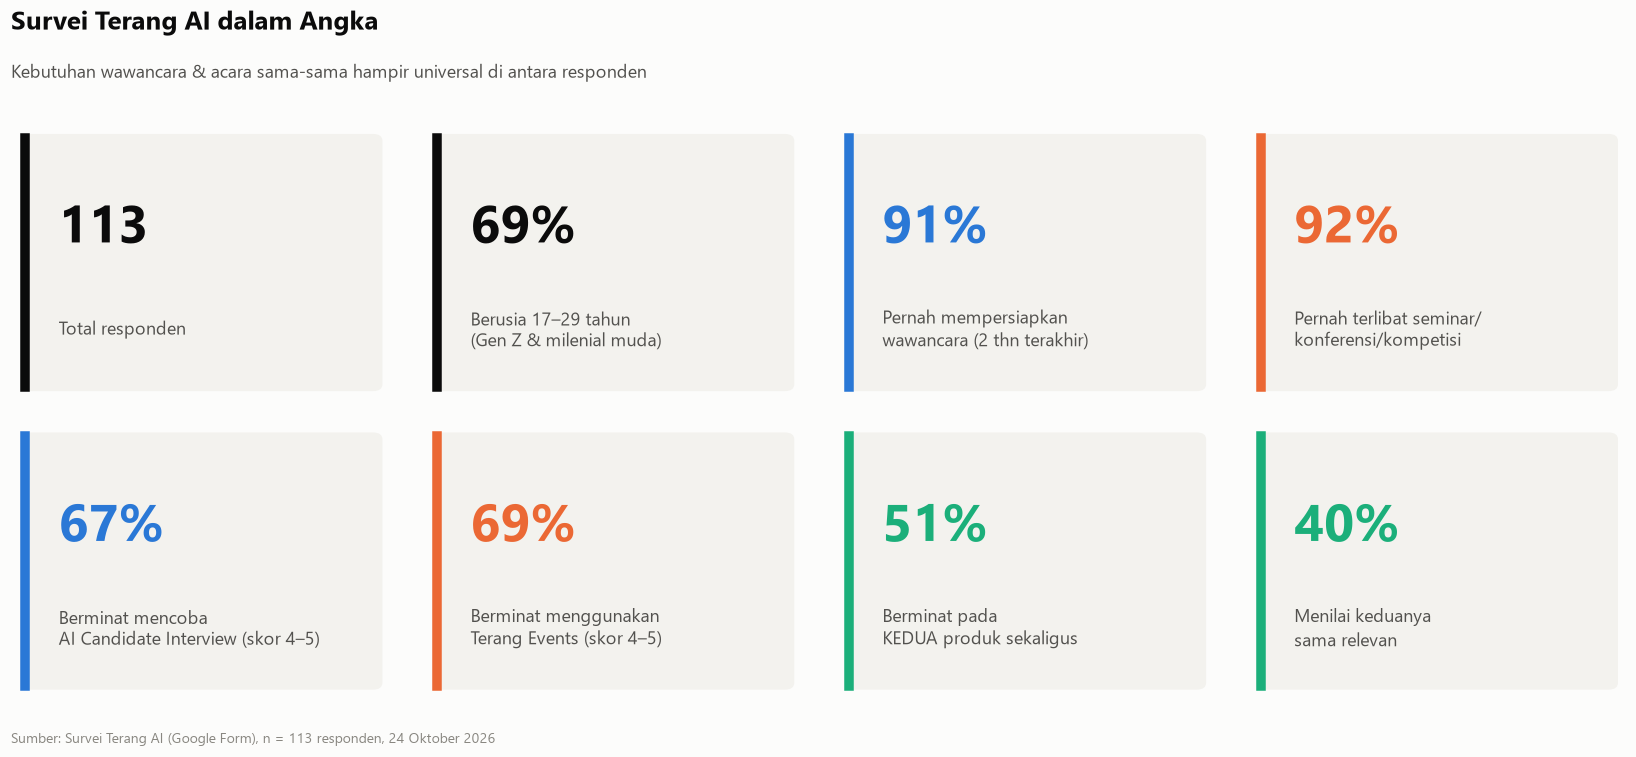

In [4]:
def share(mask): return mask.mean() * 100

kpi = [
    (f'{N}', 'Total responden', INK),
    (f"{share(df['usia'] == '17 - 29'):.0f}%", 'Berusia 17–29 tahun\n(Gen Z & milenial muda)', INK),
    (f"{share(df['pernah_wwc'] == 1):.0f}%", 'Pernah mempersiapkan\nwawancara (2 thn terakhir)', AI),
    (f"{share(df['pernah_acara'] != 'Belum pernah'):.0f}%", 'Pernah terlibat seminar/\nkonferensi/kompetisi', EV),
    (f"{share(df['t2b_minat_ai'] == 1):.0f}%", 'Berminat mencoba\nAI Candidate Interview (skor 4–5)', AI),
    (f"{share(df['t2b_minat_ev'] == 1):.0f}%", 'Berminat menggunakan\nTerang Events (skor 4–5)', EV),
    (f"{share(df['t2b_both'] == 1):.0f}%", 'Berminat pada\nKEDUA produk sekaligus', BOTH),
    (f"{share(df['pilih_relevan'] == 'Keduanya'):.0f}%", 'Menilai keduanya\nsama relevan', BOTH),
]
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6))
for ax, (val, lab, col) in zip(axes.flat, kpi):
    ax.axis('off')
    card(ax, 0.02, 0.04, 0.96, 0.92, PLANE)
    ax.add_patch(mpatches.Rectangle((0.02, 0.04), 0.022, 0.92, color=col, transform=ax.transAxes))
    ax.text(0.12, 0.62, val, fontsize=34, weight='bold', color=col if col != INK else INK, transform=ax.transAxes, va='center')
    ax.text(0.12, 0.26, lab, fontsize=11.5, color=INK2, transform=ax.transAxes, va='center', linespacing=1.35)
titled(fig, 'Survei Terang AI dalam Angka', 'Kebutuhan wawancara & acara sama-sama hampir universal di antara responden')
save(fig, '01_ringkasan_survei')

## 3. Profil & Karakteristik Responden
Siapa yang mengisi survei? Bagian ini memetakan **usia, pekerjaan, pengalaman wawancara, dan keterlibatan dalam acara** — dua aktivitas yang menjadi pasar AI Candidate Interview dan Terang Events.

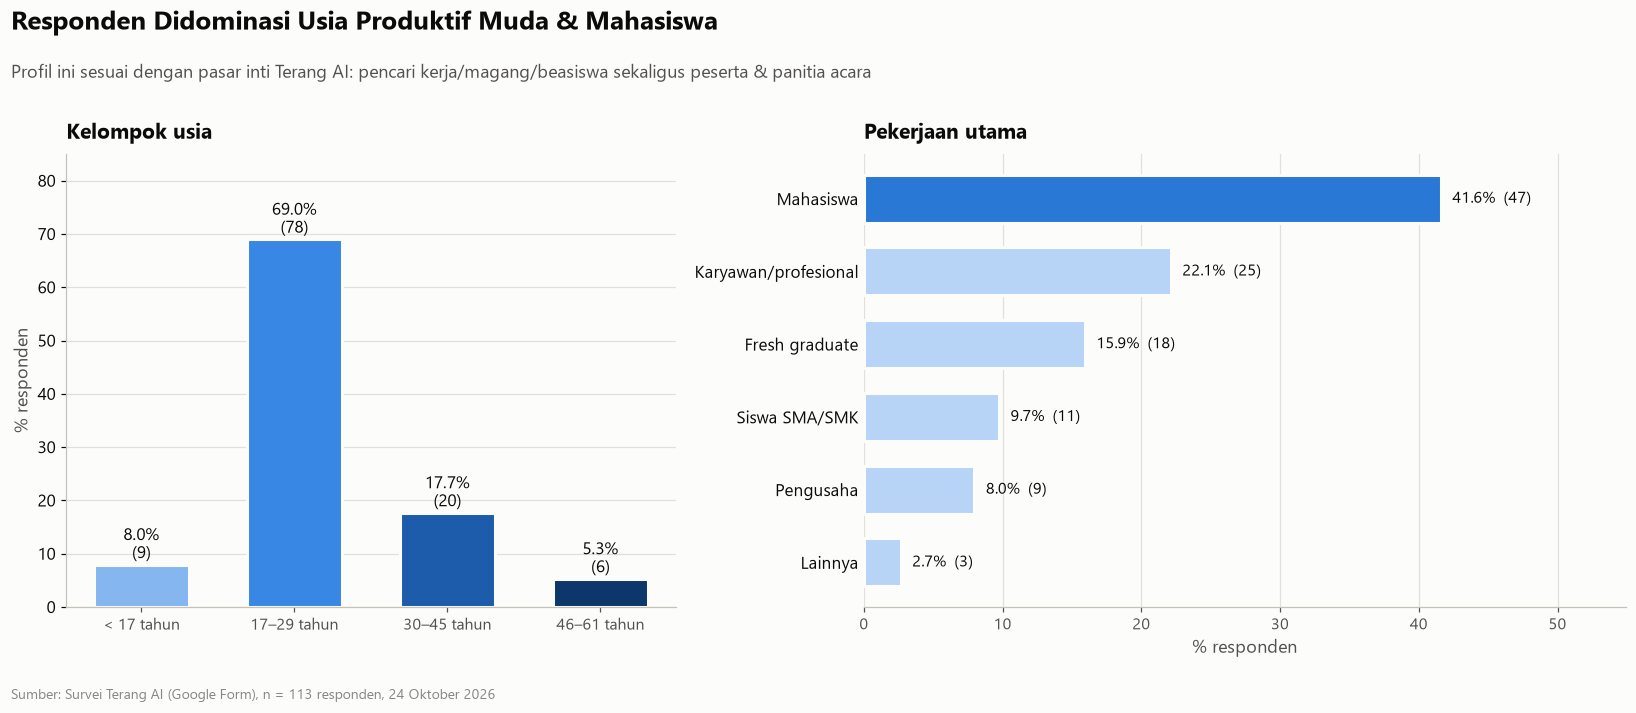

> **💡 Insight:** **69%** responden berusia 17–29 tahun dan **42%** adalah mahasiswa. Bila digabung dengan fresh graduate (16%), **58%** responden berada di fase transisi kampus → karier — fase dengan intensitas wawancara (magang, beasiswa, kerja pertama) dan aktivitas acara kampus yang paling tinggi. Kelompok profesional & pengusaha (30%) merepresentasikan sisi yang lebih dekat dengan pengguna B2B (rekruter/penyelenggara).

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})
u = df['usia'].value_counts().reindex(USIA_ORDER)
ramp = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']
bars = a1.bar(['< 17 tahun', '17–29 tahun', '30–45 tahun', '46–61 tahun'], u.values / N * 100, color=ramp,
              width=0.62, edgecolor=SURF, linewidth=2)
for b, c in zip(bars, u.values):
    a1.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f'{c / N * 100:.1f}%\n({c})', ha='center', fontsize=11)
a1.set_ylim(0, 85); a1.set_ylabel('% responden'); a1.yaxis.grid(True); a1.set_axisbelow(True)
a1.set_title('Kelompok usia')
hbar(a2, df['pekerjaan'].value_counts(), N, AI, AI_T, highlight=1, title='Pekerjaan utama')
titled(fig, 'Responden Didominasi Usia Produktif Muda & Mahasiswa',
       'Profil ini sesuai dengan pasar inti Terang AI: pencari kerja/magang/beasiswa sekaligus peserta & panitia acara')
save(fig, '02_profil_usia_pekerjaan')

pk = df['pekerjaan'].value_counts()
insight(f"**{u['17 - 29'] / N:.0%}** responden berusia 17–29 tahun dan **{pk['Mahasiswa'] / N:.0%}** adalah mahasiswa. "
        f"Bila digabung dengan fresh graduate ({pk['Fresh graduate'] / N:.0%}), **{(pk['Mahasiswa'] + pk['Fresh graduate']) / N:.0%}** responden "
        f"berada di fase transisi kampus → karier — fase dengan intensitas wawancara (magang, beasiswa, kerja pertama) "
        f"dan aktivitas acara kampus yang paling tinggi. Kelompok profesional & pengusaha ({(pk['Karyawan/profesional'] + pk['Pengusaha']) / N:.0%}) "
        f"merepresentasikan sisi yang lebih dekat dengan pengguna B2B (rekruter/penyelenggara).")

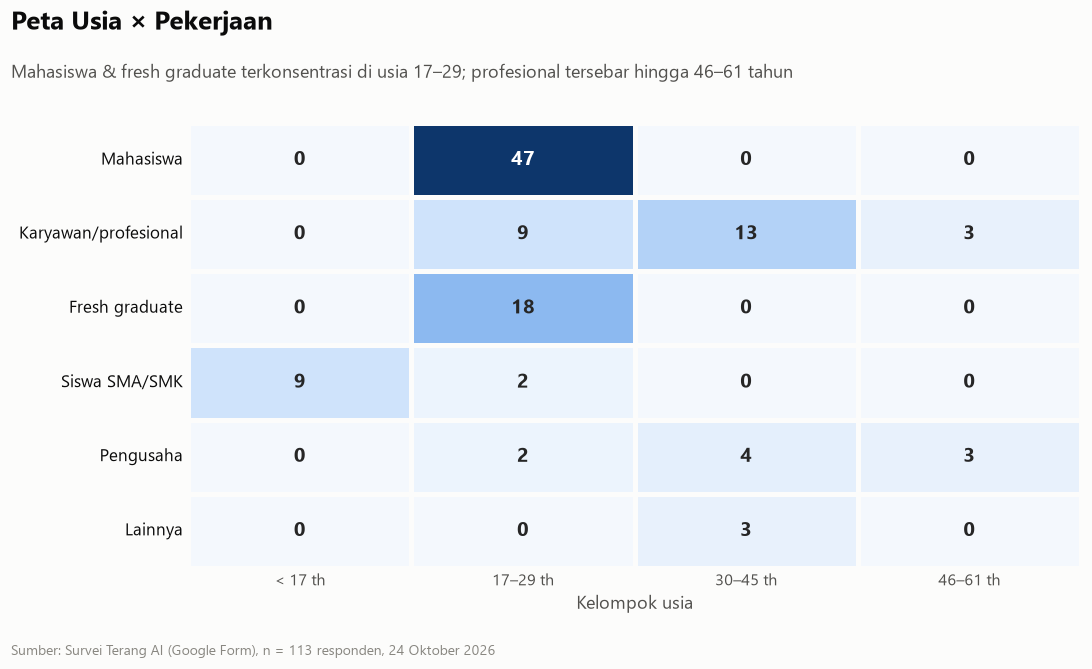

In [6]:
ct = pd.crosstab(df['pekerjaan'], df['usia']).reindex(columns=USIA_ORDER)
ct = ct.loc[df['pekerjaan'].value_counts().index]
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(ct, annot=True, fmt='d', cmap=SEQ, cbar=False, linewidths=2, linecolor=SURF,
            annot_kws={'fontsize': 13, 'weight': 'bold'}, ax=ax)
ax.set_xticklabels(['< 17 th', '17–29 th', '30–45 th', '46–61 th'], rotation=0)
ax.set_xlabel('Kelompok usia'); ax.set_ylabel('')
ax.tick_params(length=0)
titled(fig, 'Peta Usia × Pekerjaan', 'Mahasiswa & fresh graduate terkonsentrasi di usia 17–29; profesional tersebar hingga 46–61 tahun')
save(fig, '03_usia_x_pekerjaan')

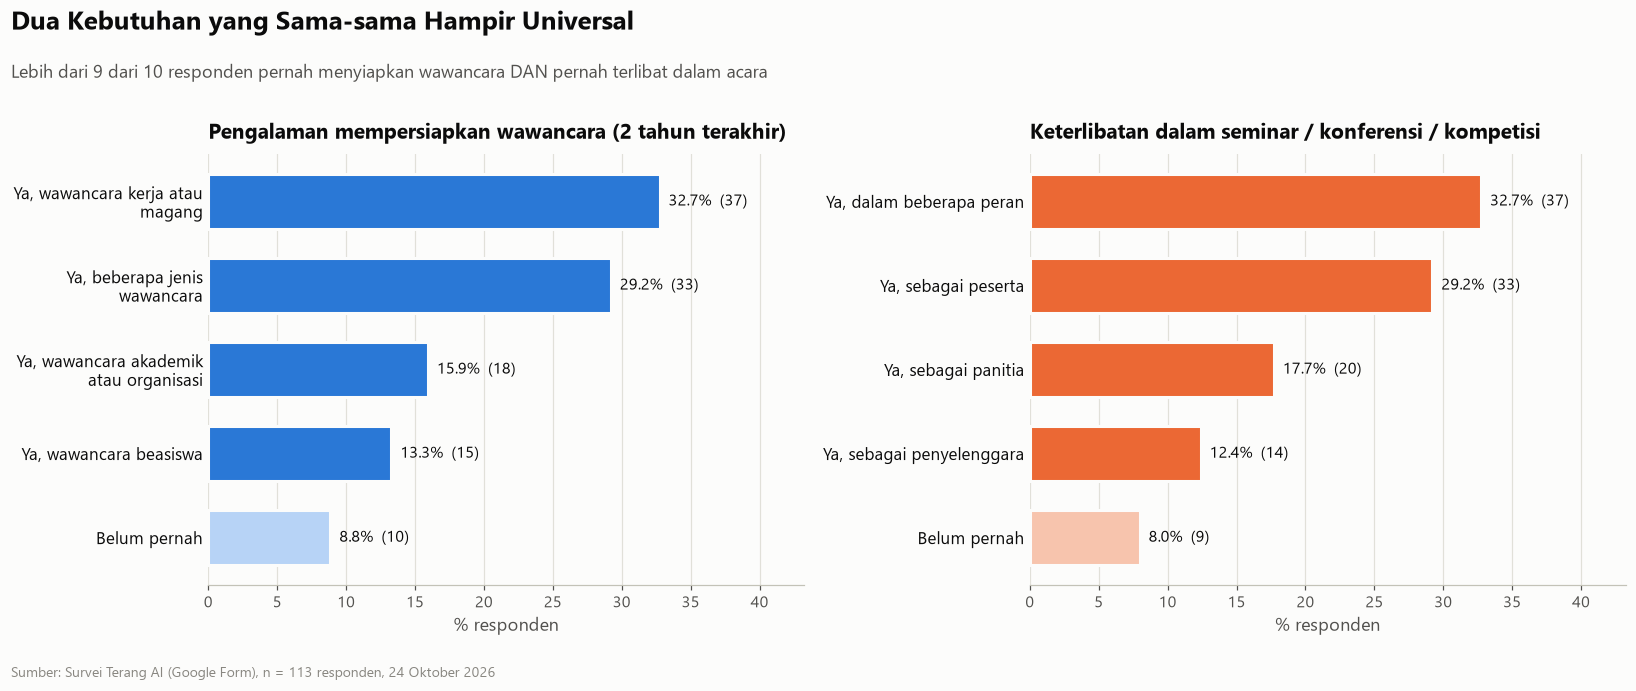

> **💡 Insight:** **91%** responden pernah menyiapkan wawancara dan **92%** pernah terlibat acara. Yang menarik, **83%** responden mengalami **keduanya sekaligus** — artinya basis pengguna kedua produk **sangat beririsan**. Selain itu **63%** responden pernah menjadi panitia/penyelenggara, yaitu calon pengguna (dan *buyer* organisasi) Terang Events.

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
hbar(a1, df['pernah_wawancara'].value_counts(), N, AI, AI_T, highlight=4, wrap_w=26,
     title='Pengalaman mempersiapkan wawancara (2 tahun terakhir)')
hbar(a2, df['pernah_acara'].value_counts(), N, EV, EV_T, highlight=4, wrap_w=26,
     title='Keterlibatan dalam seminar / konferensi / kompetisi')
titled(fig, 'Dua Kebutuhan yang Sama-sama Hampir Universal',
       'Lebih dari 9 dari 10 responden pernah menyiapkan wawancara DAN pernah terlibat dalam acara')
save(fig, '04_pengalaman_wawancara_acara')

org = (df['peran_acara'] == 'Pernah jadi panitia/penyelenggara').mean()
both_exp = ((df['pernah_wwc'] == 1) & (df['pernah_acara'] != 'Belum pernah')).mean()
insight(f"**{df['pernah_wwc'].mean():.0%}** responden pernah menyiapkan wawancara dan **{(df['pernah_acara'] != 'Belum pernah').mean():.0%}** pernah terlibat acara. "
        f"Yang menarik, **{both_exp:.0%}** responden mengalami **keduanya sekaligus** — artinya basis pengguna kedua produk "
        f"**sangat beririsan**. Selain itu **{org:.0%}** responden pernah menjadi panitia/penyelenggara, yaitu calon pengguna "
        f"(dan *buyer* organisasi) Terang Events.")

## 4. Sisi AI Candidate Interview — Masalah, Perilaku & Kebutuhan

Bagian ini menjawab: **apakah masalah persiapan wawancara cukup nyata dan cukup tajam untuk dijadikan fokus produk?** Ini adalah fondasi argumen **ONE Strategy**.

### 4.1 Tantangan terbesar saat mempersiapkan wawancara
Pertanyaan ini multi-pilih, sehingga persentase dihitung dari **jumlah responden** (total bisa > 100%).

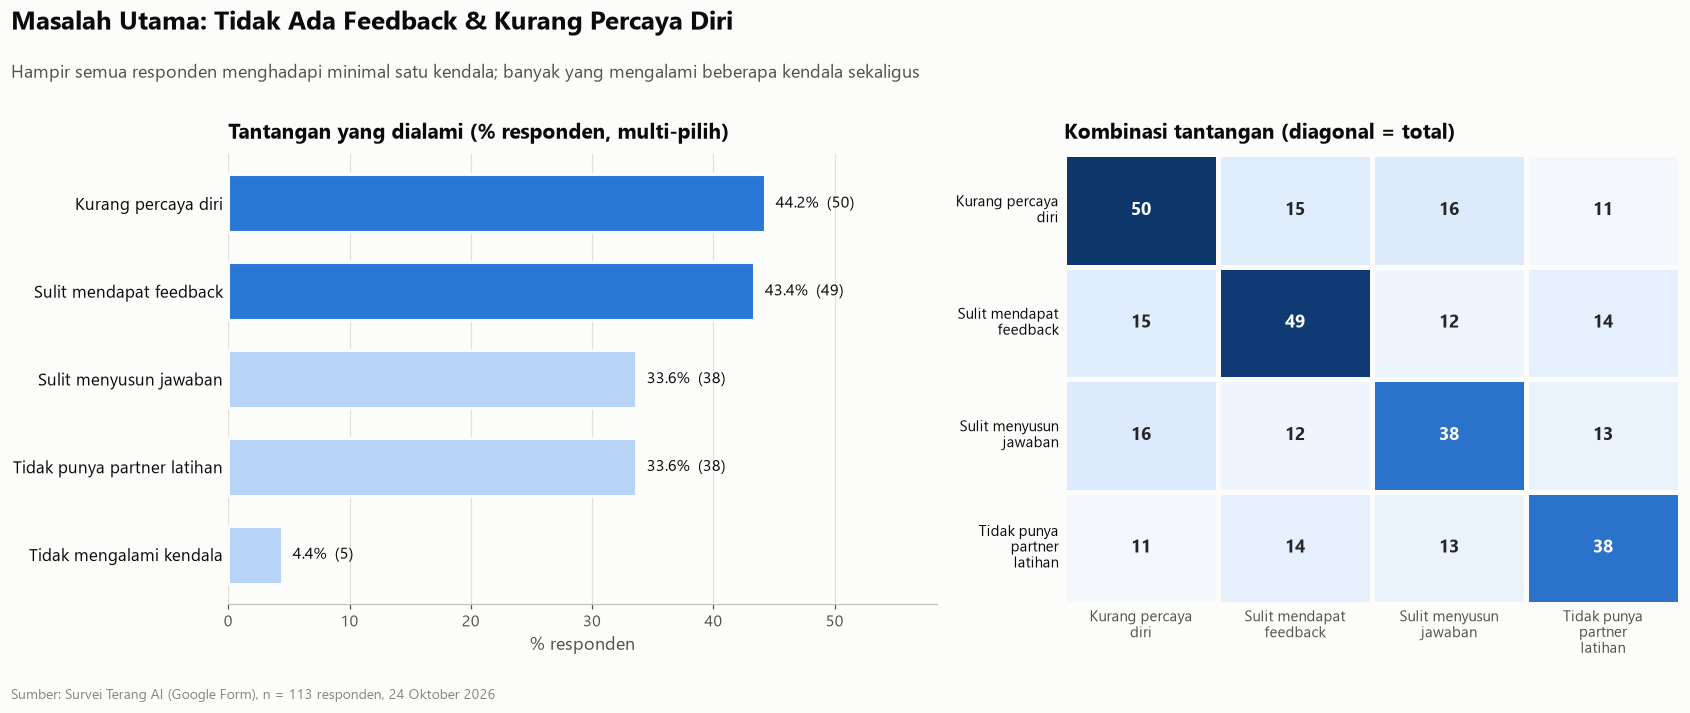

> **💡 Insight:** Tantangan teratas adalah **Kurang percaya diri** (44%) dan **Sulit mendapat feedback** (43%). Hanya **4%** responden yang mengaku tidak mengalami kendala, sedangkan **47%** menghadapi ≥2 kendala sekaligus. Masalah ini bersifat **struktural** (tidak ada evaluator & partner latihan) — tepat di area yang bisa diotomatisasi AI (simulasi 24/7 + feedback instan).

In [8]:
tw_counts = TW.sum().sort_values(ascending=False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15.5, 5.2), gridspec_kw={'width_ratios': [1.15, 1]})
hbar(a1, tw_counts, N, AI, AI_T, highlight=2, title='Tantangan yang dialami (% responden, multi-pilih)')

opts = [o for o in tw_counts.index if o != 'Tidak mengalami kendala']
co = pd.DataFrame(0, index=opts, columns=opts)
for o1 in opts:
    for o2 in opts:
        co.loc[o1, o2] = int(((TW[o1] == 1) & (TW[o2] == 1)).sum())
lab = [wrap(o, 14) for o in opts]
sns.heatmap(co, annot=True, fmt='d', cmap=SEQ, cbar=False, linewidths=2, linecolor=SURF,
            xticklabels=lab, yticklabels=lab, annot_kws={'fontsize': 12, 'weight': 'bold'}, ax=a2)
a2.set_title('Kombinasi tantangan (diagonal = total)'); a2.tick_params(length=0)
plt.setp(a2.get_xticklabels(), rotation=0, fontsize=9.5); plt.setp(a2.get_yticklabels(), rotation=0, fontsize=9.5)
titled(fig, 'Masalah Utama: Tidak Ada Feedback & Kurang Percaya Diri',
       'Hampir semua responden menghadapi minimal satu kendala; banyak yang mengalami beberapa kendala sekaligus')
save(fig, '05_ai_tantangan_wawancara')

multi = (df['n_tantangan'] >= 2).mean()
no_issue = TW['Tidak mengalami kendala'].mean()
insight(f"Tantangan teratas adalah **{tw_counts.index[0]}** ({tw_counts.iloc[0] / N:.0%}) dan **{tw_counts.index[1]}** ({tw_counts.iloc[1] / N:.0%}). "
        f"Hanya **{no_issue:.0%}** responden yang mengaku tidak mengalami kendala, sedangkan **{multi:.0%}** menghadapi ≥2 kendala sekaligus. "
        f"Masalah ini bersifat **struktural** (tidak ada evaluator & partner latihan) — tepat di area yang bisa diotomatisasi AI "
        f"(simulasi 24/7 + feedback instan).")

### 4.2 Cara berlatih, situasi kebutuhan & faktor kesiapan

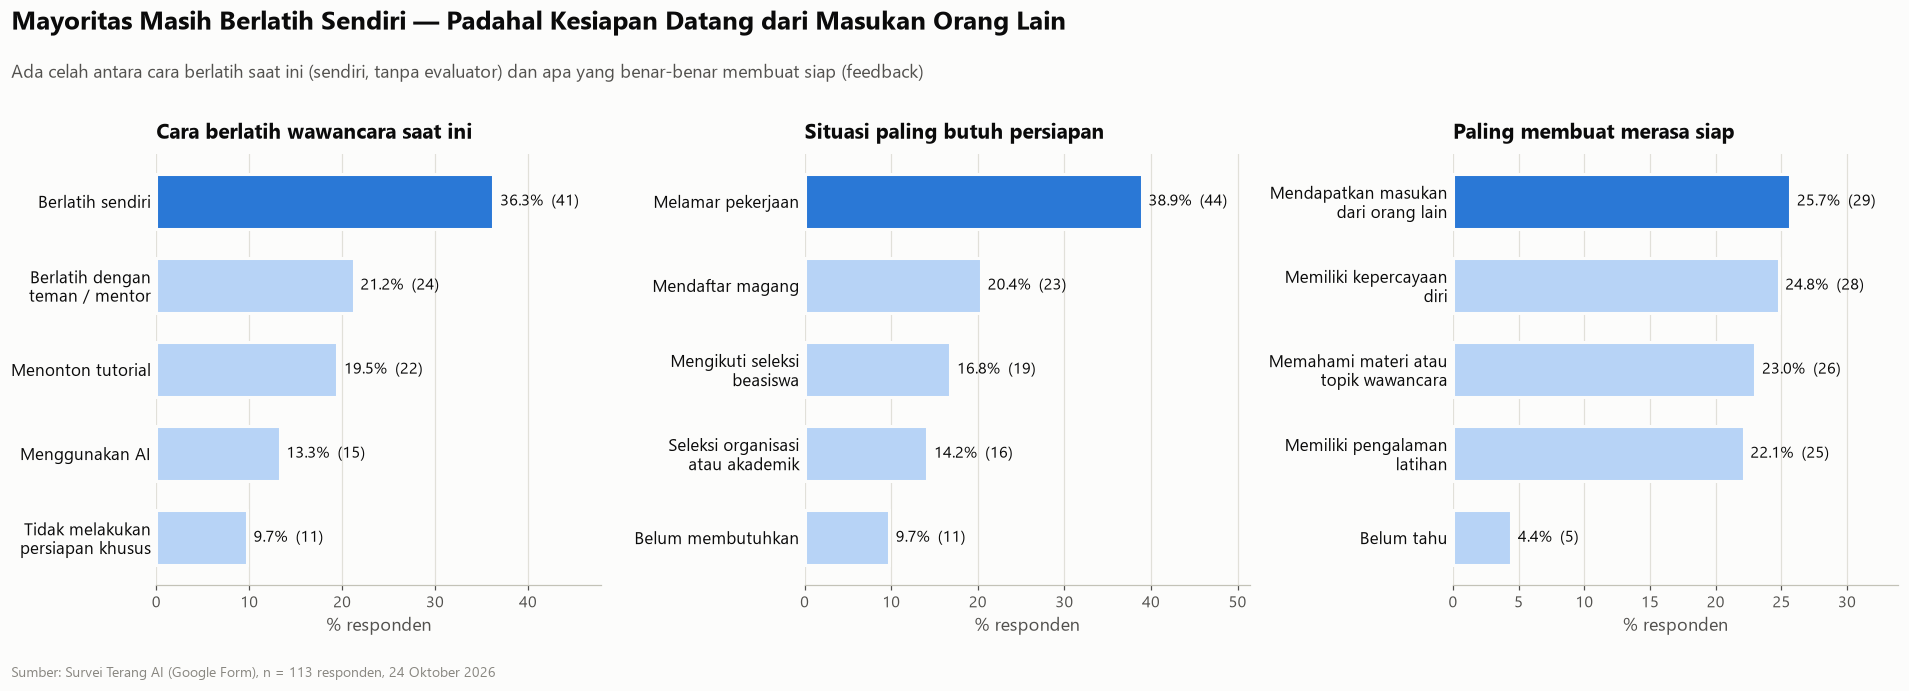

> **💡 Insight:** **36%** responden berlatih **sendiri** dan **10%** tidak melakukan persiapan khusus, sementara hanya **13%** yang sudah memakai AI. Di sisi lain, faktor kesiapan nomor satu adalah **mendapatkan masukan dari orang lain** (26%). Inilah *problem gap* AI Candidate Interview: orang butuh feedback, tetapi berlatih tanpa evaluator. Rendahnya adopsi AI saat ini = **ruang pasar yang masih terbuka (whitespace)**.

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5))
hbar(axes[0], df['cara_latihan'].value_counts(), N, AI, AI_T, highlight=1, wrap_w=20, title='Cara berlatih wawancara saat ini')
hbar(axes[1], df['situasi_butuh'].value_counts(), N, AI, AI_T, highlight=1, wrap_w=20, title='Situasi paling butuh persiapan')
hbar(axes[2], df['faktor_siap'].value_counts(), N, AI, AI_T, highlight=1, wrap_w=20, title='Paling membuat merasa siap')
titled(fig, 'Mayoritas Masih Berlatih Sendiri — Padahal Kesiapan Datang dari Masukan Orang Lain',
       'Ada celah antara cara berlatih saat ini (sendiri, tanpa evaluator) dan apa yang benar-benar membuat siap (feedback)')
save(fig, '06_ai_perilaku_latihan')

cl = df['cara_latihan'].value_counts(normalize=True)
fs = df['faktor_siap'].value_counts(normalize=True)
insight(f"**{cl['Berlatih sendiri']:.0%}** responden berlatih **sendiri** dan **{cl['Tidak melakukan persiapan khusus']:.0%}** tidak melakukan persiapan khusus, "
        f"sementara hanya **{cl['Menggunakan AI']:.0%}** yang sudah memakai AI. Di sisi lain, faktor kesiapan nomor satu adalah "
        f"**mendapatkan masukan dari orang lain** ({fs['Mendapatkan masukan dari orang lain']:.0%}). Inilah *problem gap* AI Candidate Interview: "
        f"orang butuh feedback, tetapi berlatih tanpa evaluator. Rendahnya adopsi AI saat ini = **ruang pasar yang masih terbuka (whitespace)**.")

### 4.3 Persepsi pentingnya wawancara, kebutuhan fitur & pertimbangan mencoba

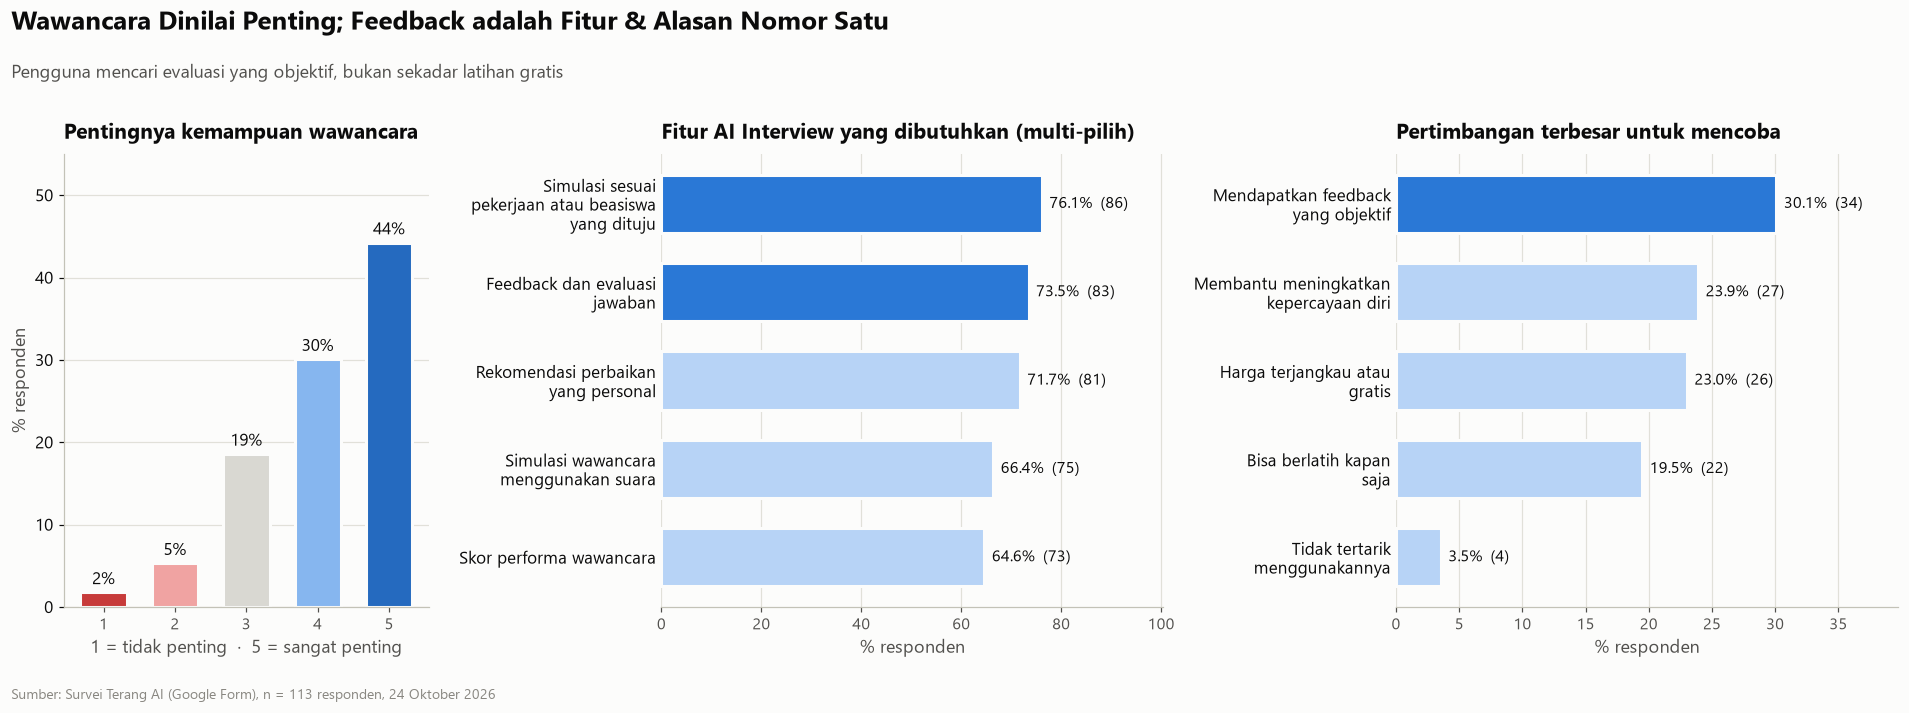

> **💡 Insight:** **74%** responden menilai kemampuan wawancara penting/sangat penting (skor 4–5). Fitur paling dibutuhkan: **Simulasi sesuai pekerjaan atau beasiswa yang dituju** (76%) dan **Feedback dan evaluasi jawaban** (73%); rata-rata responden memilih **3.5 fitur**, menandakan ekspektasi produk yang lengkap. Pertimbangan terbesar adalah **feedback objektif** (30%), di atas **harga murah/gratis** (23%) — sinyal bahwa nilai produk (kualitas evaluasi) lebih menentukan daripada harga, modal penting untuk monetisasi.

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2), gridspec_kw={'width_ratios': [0.8, 1.1, 1.1]})
imp = df['penting_wawancara'].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
cols = [NEG2, NEG1, MID, POS1, POS2]
b = axes[0].bar(imp.index.astype(str), imp.values / N * 100, color=cols, width=0.65, edgecolor=SURF, linewidth=2)
for bb, c in zip(b, imp.values):
    axes[0].text(bb.get_x() + bb.get_width() / 2, bb.get_height() + 1, f'{c / N:.0%}', ha='center', fontsize=11)
axes[0].set_xlabel('1 = tidak penting  ·  5 = sangat penting'); axes[0].set_ylabel('% responden')
axes[0].set_ylim(0, 55); axes[0].yaxis.grid(True); axes[0].set_axisbelow(True)
axes[0].set_title('Pentingnya kemampuan wawancara')
hbar(axes[1], FA.sum(), N, AI, AI_T, highlight=2, wrap_w=24, title='Fitur AI Interview yang dibutuhkan (multi-pilih)')
hbar(axes[2], df['pertimbangan_ai'].value_counts(), N, AI, AI_T, highlight=1, wrap_w=22, title='Pertimbangan terbesar untuk mencoba')
titled(fig, 'Wawancara Dinilai Penting; Feedback adalah Fitur & Alasan Nomor Satu',
       'Pengguna mencari evaluasi yang objektif, bukan sekadar latihan gratis')
save(fig, '07_ai_fitur_pertimbangan')

fa = FA.sum().sort_values(ascending=False)
pa = df['pertimbangan_ai'].value_counts(normalize=True)
insight(f"**{df['t2b_penting_wawancara'].mean():.0%}** responden menilai kemampuan wawancara penting/sangat penting (skor 4–5). "
        f"Fitur paling dibutuhkan: **{fa.index[0]}** ({fa.iloc[0] / N:.0%}) dan **{fa.index[1]}** ({fa.iloc[1] / N:.0%}); "
        f"rata-rata responden memilih **{df['n_fitur_ai'].mean():.1f} fitur**, menandakan ekspektasi produk yang lengkap. "
        f"Pertimbangan terbesar adalah **feedback objektif** ({pa['Mendapatkan feedback yang objektif']:.0%}), di atas **harga murah/gratis** "
        f"({pa['Harga terjangkau atau gratis']:.0%}) — sinyal bahwa nilai produk (kualitas evaluasi) lebih menentukan daripada harga, "
        f"modal penting untuk monetisasi.")

### 4.4 Jembatan *Pain → Solution*
Apakah masalah yang dirasakan responden **nyambung** dengan fitur yang mereka minta dan alasan mereka mau mencoba? Grafik berikut menelusuri benang merah "feedback" dan "percaya diri" dari masalah → kebutuhan → alasan adopsi.

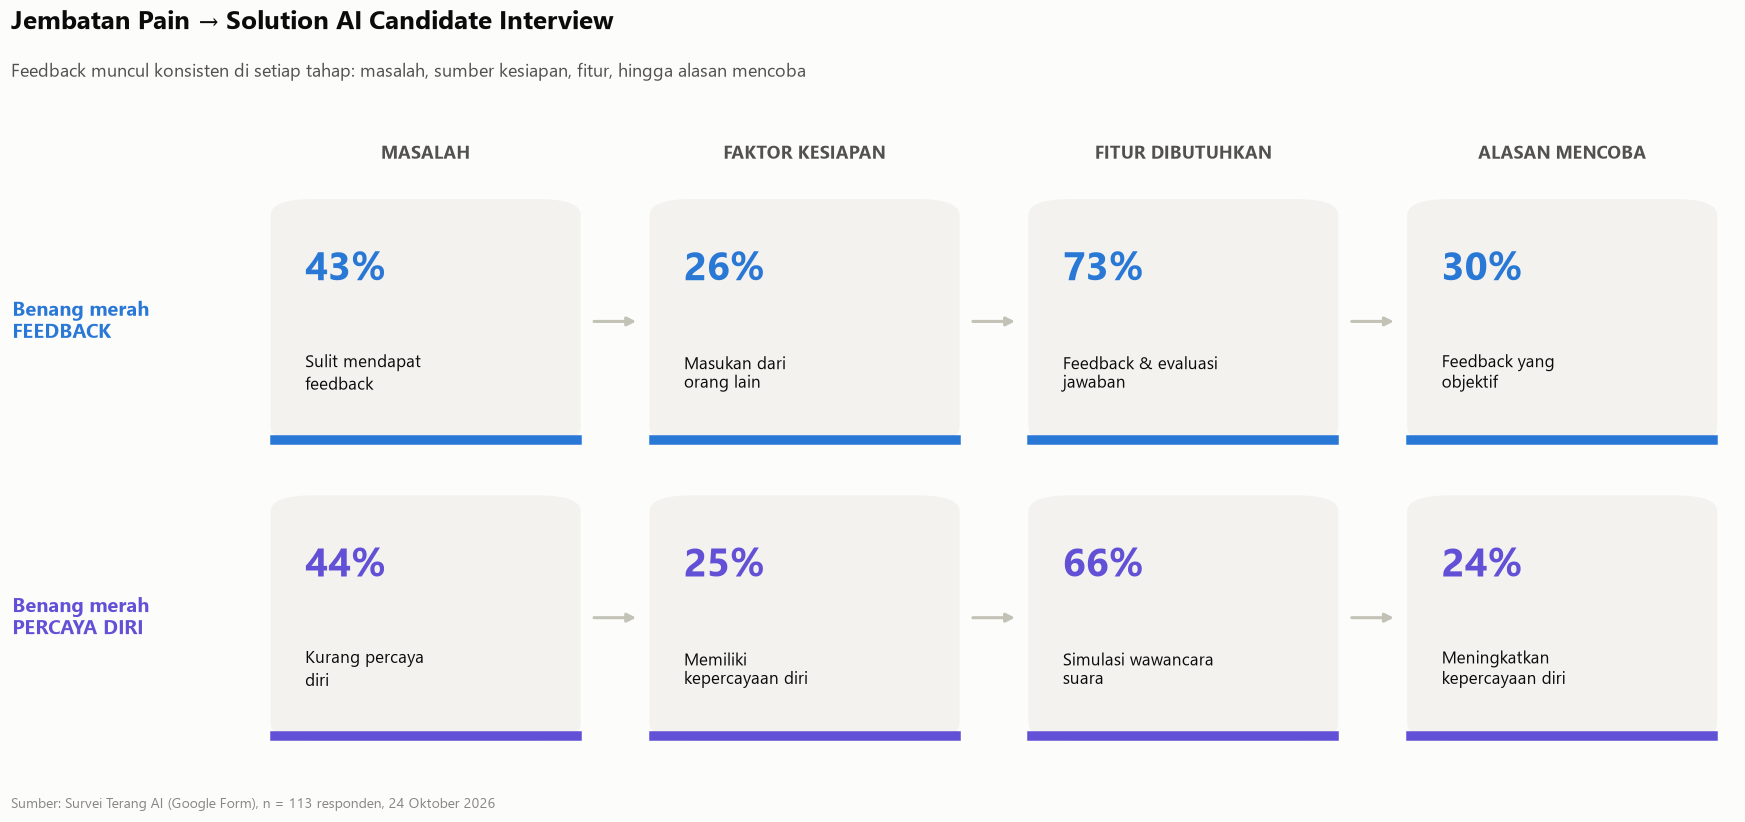

> **💡 Insight:** **43%** responden kesulitan mendapat feedback, tetapi **73%** meminta fitur feedback & evaluasi jawaban — permintaan solusinya jauh melampaui masalah yang dilaporkan, karena bahkan yang tidak mengeluhkan feedback tetap menginginkannya. Feedback juga menjadi alasan mencoba nomor satu (30%). Artinya *value proposition* AI Candidate Interview yang paling kuat adalah **evaluasi jawaban yang objektif & personal**, bukan sekadar bank soal — dasar pilar **Optimize Product Value** pada ONE Strategy.

In [11]:
bridge = pd.DataFrame({
    'Masalah': [TW['Sulit mendapat feedback'].mean(), TW['Kurang percaya diri'].mean()],
    'Faktor kesiapan': [(df['faktor_siap'] == 'Mendapatkan masukan dari orang lain').mean(),
                        (df['faktor_siap'] == 'Memiliki kepercayaan diri').mean()],
    'Fitur dibutuhkan': [FA['Feedback dan evaluasi jawaban'].mean(), FA['Simulasi wawancara menggunakan suara'].mean()],
    'Alasan mencoba': [(df['pertimbangan_ai'] == 'Mendapatkan feedback yang objektif').mean(),
                       (df['pertimbangan_ai'] == 'Membantu meningkatkan kepercayaan diri').mean()],
}, index=['Benang merah FEEDBACK', 'Benang merah PERCAYA DIRI']) * 100
detail = {
    'Benang merah FEEDBACK': ['Sulit mendapat\nfeedback', 'Masukan dari\norang lain', 'Feedback & evaluasi\njawaban', 'Feedback yang\nobjektif'],
    'Benang merah PERCAYA DIRI': ['Kurang percaya\ndiri', 'Memiliki\nkepercayaan diri', 'Simulasi wawancara\nsuara', 'Meningkatkan\nkepercayaan diri'],
}
fig, ax = plt.subplots(figsize=(16, 6.2))
ax.axis('off'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
bw, gap = 0.18, 0.04
x0s = [0.15 + i * (bw + gap) for i in range(4)]
for j, stage in enumerate(bridge.columns):
    ax.text(x0s[j] + bw / 2, 0.95, stage.upper(), ha='center', va='center', fontsize=12, weight='bold', color=INK2)
for r, ((name, row), col) in enumerate(zip(bridge.iterrows(), [AI, VIOLET])):
    y0 = 0.5 - r * 0.46
    ax.text(0.0, y0 + 0.19, wrap(name.replace('Benang merah ', 'Benang merah\n'), 16), fontsize=13, weight='bold', color=col, va='center')
    for j, (v, d) in enumerate(zip(row.values, detail[name])):
        card(ax, x0s[j], y0, bw, 0.38, PLANE)
        ax.add_patch(mpatches.Rectangle((x0s[j], y0), bw, 0.012, color=col, transform=ax.transAxes))
        ax.text(x0s[j] + 0.02, y0 + 0.27, f'{v:.0f}%', fontsize=26, weight='bold', color=col, va='center')
        ax.text(x0s[j] + 0.02, y0 + 0.11, d, fontsize=11, color=INK, va='center', linespacing=1.3)
        if j < 3:
            ax.annotate('', xy=(x0s[j + 1] - 0.006, y0 + 0.19), xytext=(x0s[j] + bw + 0.006, y0 + 0.19),
                        arrowprops=dict(arrowstyle='-|>', color=BASE, lw=2))
titled(fig, 'Jembatan Pain → Solution AI Candidate Interview',
       'Feedback muncul konsisten di setiap tahap: masalah, sumber kesiapan, fitur, hingga alasan mencoba')
save(fig, '08_ai_pain_to_solution')
insight(f"**{bridge.iloc[0, 0]:.0f}%** responden kesulitan mendapat feedback, tetapi **{bridge.iloc[0, 2]:.0f}%** meminta fitur feedback & evaluasi jawaban — "
        "permintaan solusinya jauh melampaui masalah yang dilaporkan, karena bahkan yang tidak mengeluhkan feedback tetap menginginkannya. "
        f"Feedback juga menjadi alasan mencoba nomor satu ({bridge.iloc[0, 3]:.0f}%). Artinya *value proposition* AI Candidate Interview yang paling kuat adalah "
        "**evaluasi jawaban yang objektif & personal**, bukan sekadar bank soal — dasar pilar **Optimize Product Value** pada ONE Strategy.")

### 4.5 Corong permintaan (*demand funnel*) AI Candidate Interview
Dari seluruh responden, berapa yang **punya kebutuhan → merasa penting → melihat manfaat → berminat mencoba**?

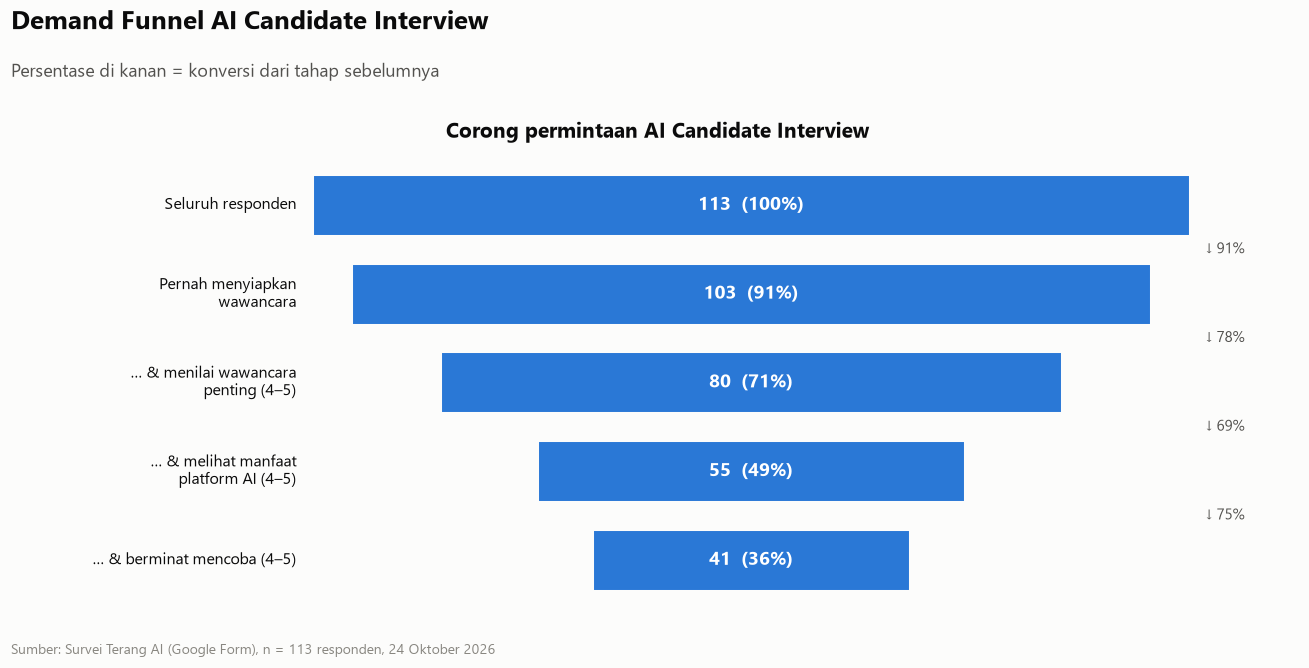

> **💡 Insight:** Sebanyak **41 responden (36%)** lolos seluruh tahap — mereka adalah *core early adopter* AI Candidate Interview: punya kebutuhan nyata, menganggapnya penting, melihat manfaat, dan siap mencoba. Kebocoran terbesar ada di tahap **'melihat manfaat platform AI (4–5)'** (hanya 69% lanjut dari tahap sebelumnya) — titik yang paling efektif ditekan lewat demo, contoh hasil evaluasi, dan uji coba gratis.

In [12]:
def funnel(ax, steps, color, title):
    labels = [s[0] for s in steps]; vals = [s[1] for s in steps]
    y = np.arange(len(steps))[::-1]
    for yi, v, l in zip(y, vals, labels):
        ax.barh(yi, v, left=(N - v) / 2, color=color, height=0.7,
                edgecolor=SURF, linewidth=2)
        ax.text(N / 2, yi, f'{v}  ({v / N:.0%})', ha='center', va='center', fontsize=12.5, weight='bold', color='white')
        ax.text(-2, yi, wrap(l, 26), ha='right', va='center', fontsize=10.5, color=INK)
    for i in range(1, len(vals)):
        ax.text(N + 2, y[i] + 0.5, f'↓ {vals[i] / vals[i - 1]:.0%}', ha='left', va='center', fontsize=10, color=INK2)
    ax.set_xlim(-38, N + 14); ax.axis('off'); ax.set_title(title, loc='center')

ai_steps = [('Seluruh responden', N),
            ('Pernah menyiapkan wawancara', int(df['pernah_wwc'].sum())),
            ('… & menilai wawancara penting (4–5)', int(((df['pernah_wwc'] == 1) & (df['penting_wawancara'] >= 4)).sum())),
            ('… & melihat manfaat platform AI (4–5)', int(((df['pernah_wwc'] == 1) & (df['penting_wawancara'] >= 4) & (df['manfaat_ai'] >= 4)).sum())),
            ('… & berminat mencoba (4–5)', int(((df['pernah_wwc'] == 1) & (df['penting_wawancara'] >= 4) & (df['manfaat_ai'] >= 4) & (df['minat_ai'] >= 4)).sum()))]
fig, ax = plt.subplots(figsize=(12, 4.8))
funnel(ax, ai_steps, AI, 'Corong permintaan AI Candidate Interview')
titled(fig, 'Demand Funnel AI Candidate Interview', 'Persentase di kanan = konversi dari tahap sebelumnya')
save(fig, '09_ai_demand_funnel')
conv = [(ai_steps[i][0], ai_steps[i][1] / ai_steps[i - 1][1]) for i in range(2, len(ai_steps))]
leak = min(conv, key=lambda t: t[1])
insight(f"Sebanyak **{ai_steps[-1][1]} responden ({ai_steps[-1][1] / N:.0%})** lolos seluruh tahap — mereka adalah *core early adopter* "
        f"AI Candidate Interview: punya kebutuhan nyata, menganggapnya penting, melihat manfaat, dan siap mencoba. "
        f"Kebocoran terbesar ada di tahap **'{leak[0].replace('… & ', '')}'** (hanya {leak[1]:.0%} lanjut dari tahap sebelumnya) — "
        f"titik yang paling efektif ditekan lewat demo, contoh hasil evaluasi, dan uji coba gratis.")

## 5. Sisi Terang Events — Masalah, Perilaku & Kebutuhan

Bagian ini menjawab: **seberapa besar dan seberapa nyata masalah pengelolaan acara**, dan apakah alat yang dipakai saat ini masih manual? Ini adalah fondasi argumen **ACE Strategy** (mengapa Terang Events tidak boleh ditinggalkan).

### 5.1 Sisi peserta: sumber informasi & faktor ketertarikan

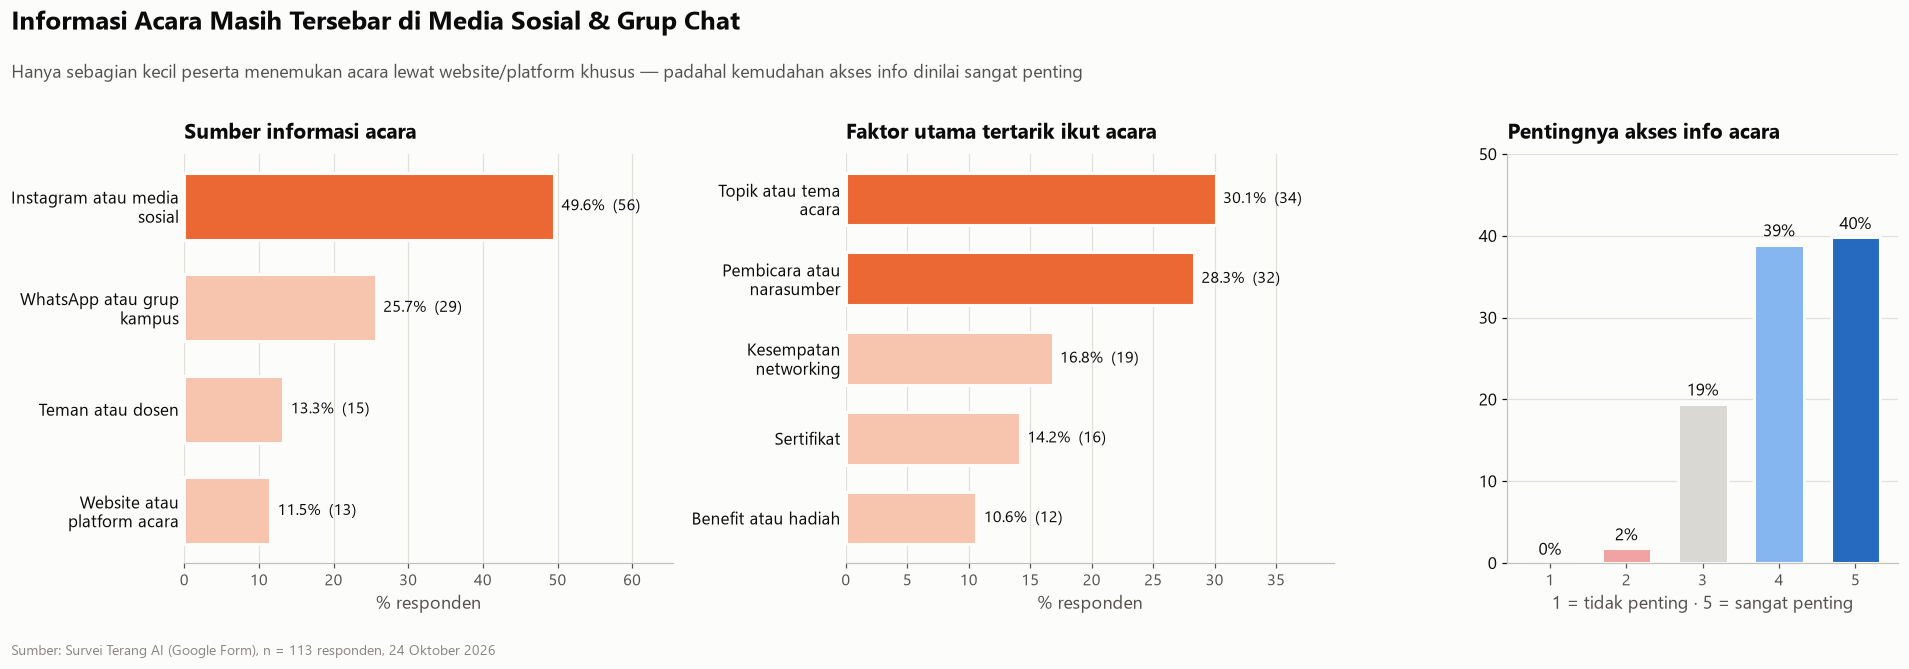

> **💡 Insight:** **75%** responden mendapat info acara dari Instagram/medsos atau grup WhatsApp, dan hanya **12%** dari website/platform acara. Padahal **79%** menilai kemudahan akses info penting (skor 4–5). Ada peluang bagi Terang Events sebagai **hub penemuan acara (event discovery)** — dan karena faktor penarik utamanya topik & pembicara, konten acara harus mudah ditemukan dan dibandingkan.

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.8), gridspec_kw={'width_ratios': [1, 1, 0.8]})
hbar(axes[0], df['sumber_info'].value_counts(), N, EV, EV_T, highlight=1, wrap_w=20, title='Sumber informasi acara')
hbar(axes[1], df['faktor_acara'].value_counts(), N, EV, EV_T, highlight=2, wrap_w=20, title='Faktor utama tertarik ikut acara')
pi = df['penting_info'].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
b = axes[2].bar(pi.index.astype(str), pi.values / N * 100, color=[NEG2, NEG1, MID, POS1, POS2], width=0.65, edgecolor=SURF, linewidth=2)
for bb, c in zip(b, pi.values):
    axes[2].text(bb.get_x() + bb.get_width() / 2, bb.get_height() + 1, f'{c / N:.0%}', ha='center', fontsize=11)
axes[2].set_ylim(0, 50); axes[2].yaxis.grid(True); axes[2].set_axisbelow(True)
axes[2].set_xlabel('1 = tidak penting · 5 = sangat penting'); axes[2].set_title('Pentingnya akses info acara')
titled(fig, 'Informasi Acara Masih Tersebar di Media Sosial & Grup Chat',
       'Hanya sebagian kecil peserta menemukan acara lewat website/platform khusus — padahal kemudahan akses info dinilai sangat penting')
save(fig, '10_ev_sisi_peserta')
si = df['sumber_info'].value_counts(normalize=True)
insight(f"**{si['Instagram atau media sosial'] + si['WhatsApp atau grup kampus']:.0%}** responden mendapat info acara dari Instagram/medsos atau grup WhatsApp, "
        f"dan hanya **{si['Website atau platform acara']:.0%}** dari website/platform acara. Padahal **{df['t2b_penting_info'].mean():.0%}** menilai "
        f"kemudahan akses info penting (skor 4–5). Ada peluang bagi Terang Events sebagai **hub penemuan acara (event discovery)** — "
        f"dan karena faktor penarik utamanya topik & pembicara, konten acara harus mudah ditemukan dan dibandingkan.")

### 5.2 Sisi penyelenggara: tantangan & alat yang dipakai saat ini
Analisis alat pengelolaan difokuskan pada **responden yang pernah mengelola acara** (mengecualikan "Belum pernah mengelola acara") agar mencerminkan calon pengguna/pembeli B2B Terang Events.

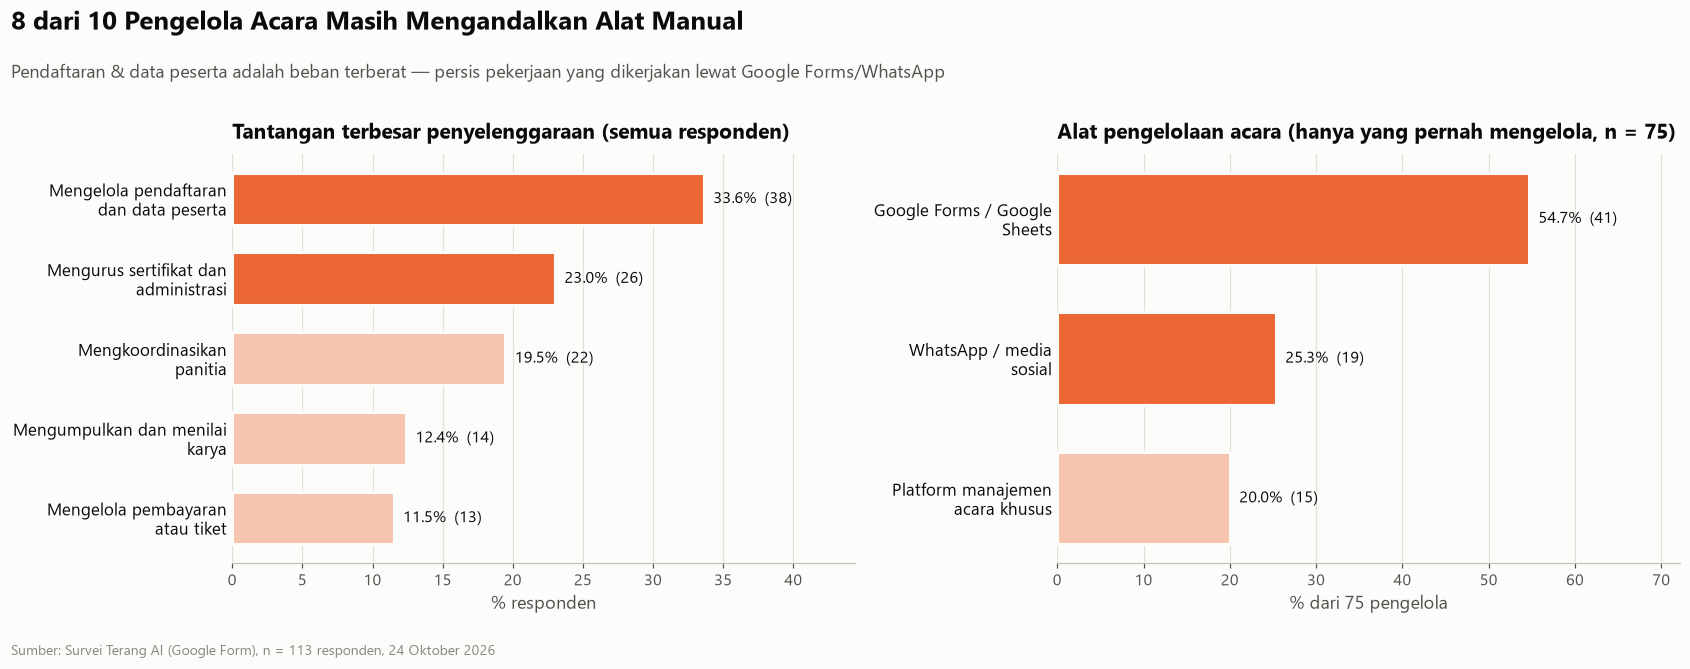

> **💡 Insight:** **75 responden (66%)** pernah mengelola pendaftaran/administrasi acara. Dari mereka, **55%** memakai Google Forms/Sheets dan **25%** memakai WhatsApp/medsos — total **80% masih manual**; hanya **20%** yang memakai platform khusus. Tantangan teratas: **pendaftaran & data peserta** (34%) dan **sertifikat & administrasi** (23%). Pasar ini masih *underserved* — peluang konversi dari tools gratis ke platform terintegrasi.

In [14]:
mgr = df[df['pengelola'] == 1]
nm = len(mgr)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15.5, 4.8))
hbar(a1, df['tantangan_acara'].value_counts(), N, EV, EV_T, highlight=2, wrap_w=24, title='Tantangan terbesar penyelenggaraan (semua responden)')
hbar(a2, mgr['kelola_acara'].value_counts(), nm, EV, EV_T, highlight=2, wrap_w=22,
     title=f'Alat pengelolaan acara (hanya yang pernah mengelola, n = {nm})', xlabel=f'% dari {nm} pengelola')
titled(fig, '8 dari 10 Pengelola Acara Masih Mengandalkan Alat Manual',
       'Pendaftaran & data peserta adalah beban terberat — persis pekerjaan yang dikerjakan lewat Google Forms/WhatsApp')
save(fig, '11_ev_tantangan_tools')
ta = df['tantangan_acara'].value_counts(normalize=True)
km = mgr['kelola_acara'].value_counts(normalize=True)
insight(f"**{nm} responden ({nm / N:.0%})** pernah mengelola pendaftaran/administrasi acara. Dari mereka, **{km['Google Forms / Google Sheets']:.0%}** memakai "
        f"Google Forms/Sheets dan **{km['WhatsApp / media sosial']:.0%}** memakai WhatsApp/medsos — total **{km['Google Forms / Google Sheets'] + km['WhatsApp / media sosial']:.0%} masih manual**; "
        f"hanya **{km['Platform manajemen acara khusus']:.0%}** yang memakai platform khusus. Tantangan teratas: **pendaftaran & data peserta** ({ta.iloc[0]:.0%}) "
        f"dan **sertifikat & administrasi** ({ta.iloc[1]:.0%}). Pasar ini masih *underserved* — peluang konversi dari tools gratis ke platform terintegrasi.")

### 5.3 Kebutuhan fitur, manfaat & minat platform manajemen acara

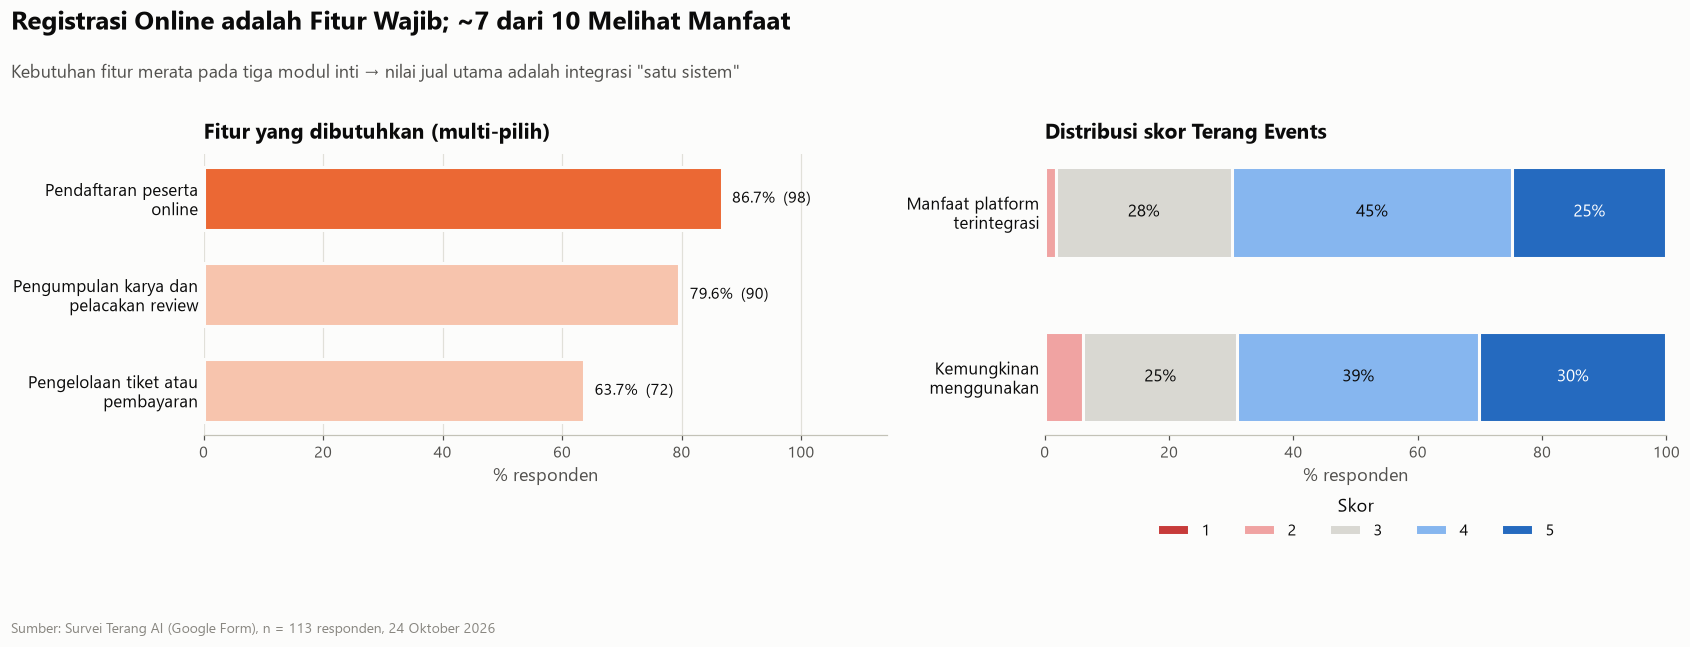

> **💡 Insight:** **87%** responden membutuhkan **Pendaftaran peserta online**, diikuti **Pengumpulan karya dan pelacakan review** (80%) dan **Pengelolaan tiket atau pembayaran** (64%). Rata-rata responden memilih **2.3 dari 3 fitur** — mereka menginginkan alur **end-to-end** (daftar → bayar → kumpul karya → review → sertifikat). **70%** menilai platform terintegrasi bermanfaat dan **69%** berminat menggunakannya.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
hbar(axes[0], FE.sum(), N, EV, EV_T, highlight=1, wrap_w=24, title='Fitur yang dibutuhkan (multi-pilih)')
dist = pd.DataFrame({'Manfaat platform\nterintegrasi': df['manfaat_ev'].value_counts(normalize=True),
                     'Kemungkinan\nmenggunakan': df['minat_ev'].value_counts(normalize=True)}).reindex([1, 2, 3, 4, 5]).fillna(0).T * 100
left = np.zeros(len(dist))
for lvl, col in zip([1, 2, 3, 4, 5], [NEG2, NEG1, MID, POS1, POS2]):
    axes[1].barh(dist.index, dist[lvl], left=left, color=col, edgecolor=SURF, linewidth=2, height=0.55, label=str(lvl))
    for i, v in enumerate(dist[lvl]):
        if v >= 7: axes[1].text(left[i] + v / 2, i, f'{v:.0f}%', ha='center', va='center', fontsize=11,
                                color='white' if lvl in (1, 5) else INK)
    left += dist[lvl].values
axes[1].set_xlim(0, 100); axes[1].invert_yaxis(); axes[1].set_xlabel('% responden')
axes[1].legend(title='Skor', ncol=5, loc='lower center', bbox_to_anchor=(0.5, -0.42))
axes[1].set_title('Distribusi skor Terang Events'); axes[1].spines['left'].set_visible(False); axes[1].tick_params(axis='y', length=0)
titled(fig, 'Registrasi Online adalah Fitur Wajib; ~7 dari 10 Melihat Manfaat',
       'Kebutuhan fitur merata pada tiga modul inti → nilai jual utama adalah integrasi "satu sistem"')
save(fig, '12_ev_fitur_minat')
fe = FE.sum().sort_values(ascending=False)
insight(f"**{fe.iloc[0] / N:.0%}** responden membutuhkan **{fe.index[0]}**, diikuti **{fe.index[1]}** ({fe.iloc[1] / N:.0%}) dan "
        f"**{fe.index[2]}** ({fe.iloc[2] / N:.0%}). Rata-rata responden memilih **{df['n_fitur_ev'].mean():.1f} dari 3 fitur** — "
        f"mereka menginginkan alur **end-to-end** (daftar → bayar → kumpul karya → review → sertifikat). "
        f"**{df['t2b_manfaat_ev'].mean():.0%}** menilai platform terintegrasi bermanfaat dan **{df['t2b_minat_ev'].mean():.0%}** berminat menggunakannya.")

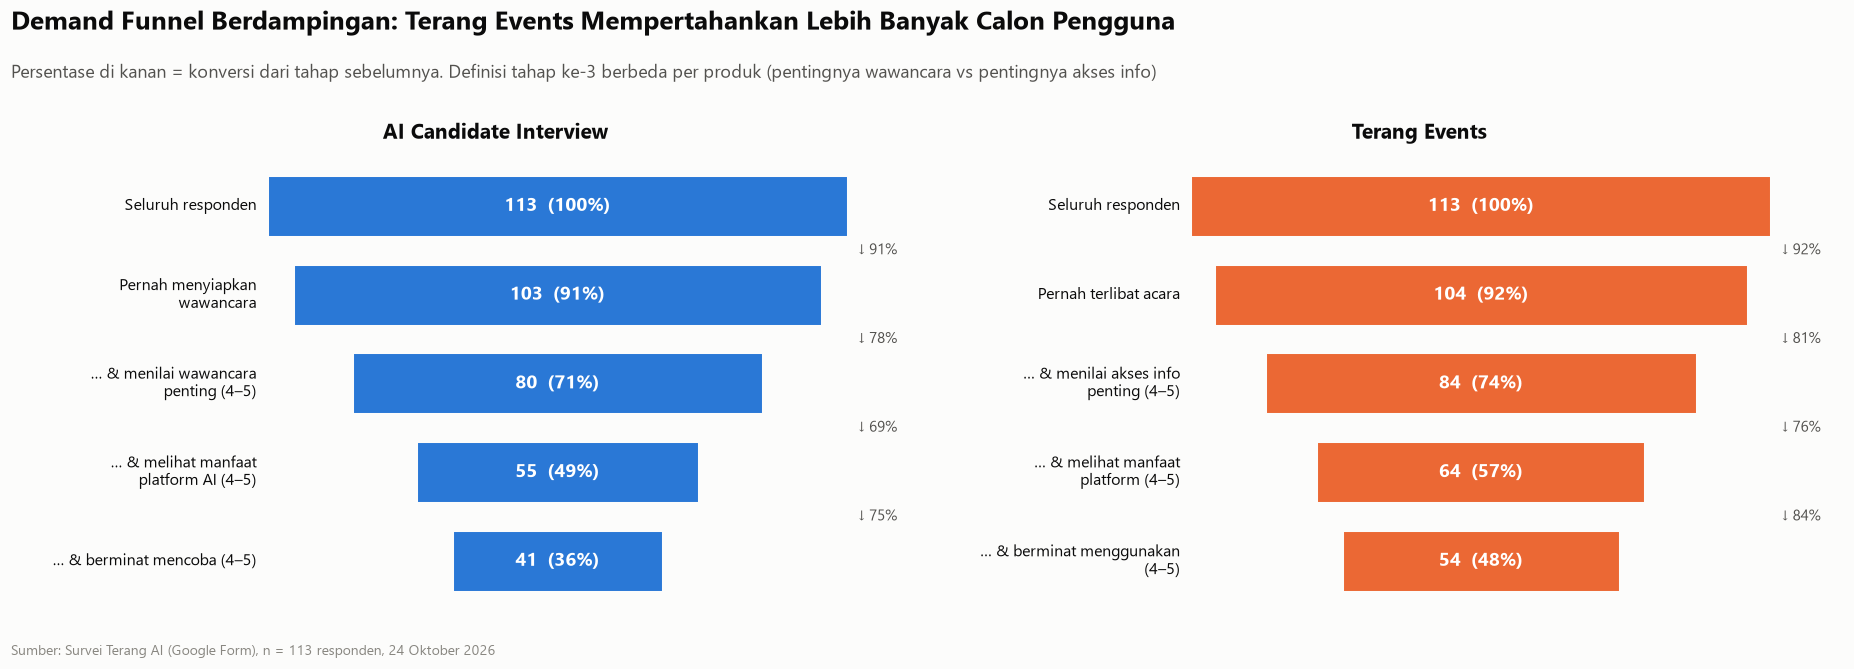

> **💡 Insight:** Early adopter penuh: AI Candidate Interview **41 orang (36%)** vs Terang Events **54 orang (48%)**. Funnel Events lebih 'landai' di setiap tahap — kebutuhan acara lebih mudah dikonversi menjadi minat. Sebanyak **23 orang** lolos di **kedua** funnel. Bagi ACE, ini bukti bahwa Terang Events punya *core demand* yang tidak boleh diabaikan; bagi ONE, ini menegaskan bahwa AI Interview perlu investasi pembuktian manfaat yang lebih fokus agar konversinya menyusul.

In [16]:
ev_steps = [('Seluruh responden', N),
            ('Pernah terlibat acara', int((df['pernah_acara'] != 'Belum pernah').sum())),
            ('… & menilai akses info penting (4–5)', int(((df['pernah_acara'] != 'Belum pernah') & (df['penting_info'] >= 4)).sum())),
            ('… & melihat manfaat platform (4–5)', int(((df['pernah_acara'] != 'Belum pernah') & (df['penting_info'] >= 4) & (df['manfaat_ev'] >= 4)).sum())),
            ('… & berminat menggunakan (4–5)', int(((df['pernah_acara'] != 'Belum pernah') & (df['penting_info'] >= 4) & (df['manfaat_ev'] >= 4) & (df['minat_ev'] >= 4)).sum()))]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.8))
funnel(a1, ai_steps, AI, 'AI Candidate Interview')
funnel(a2, ev_steps, EV, 'Terang Events')
titled(fig, 'Demand Funnel Berdampingan: Terang Events Mempertahankan Lebih Banyak Calon Pengguna',
       'Persentase di kanan = konversi dari tahap sebelumnya. Definisi tahap ke-3 berbeda per produk (pentingnya wawancara vs pentingnya akses info)')
save(fig, '13_funnel_berdampingan')
both_core = int(((df['pernah_wwc'] == 1) & (df['penting_wawancara'] >= 4) & (df['manfaat_ai'] >= 4) & (df['minat_ai'] >= 4) &
                 (df['pernah_acara'] != 'Belum pernah') & (df['penting_info'] >= 4) & (df['manfaat_ev'] >= 4) & (df['minat_ev'] >= 4)).sum())
insight(f"Early adopter penuh: AI Candidate Interview **{ai_steps[-1][1]} orang ({ai_steps[-1][1] / N:.0%})** vs Terang Events **{ev_steps[-1][1]} orang ({ev_steps[-1][1] / N:.0%})**. "
        f"Funnel Events lebih 'landai' di setiap tahap — kebutuhan acara lebih mudah dikonversi menjadi minat. Sebanyak **{both_core} orang** lolos di **kedua** funnel. "
        "Bagi ACE, ini bukti bahwa Terang Events punya *core demand* yang tidak boleh diabaikan; bagi ONE, ini menegaskan bahwa AI Interview "
        "perlu investasi pembuktian manfaat yang lebih fokus agar konversinya menyusul.")

## 6. *Head-to-Head*: AI Candidate Interview vs Terang Events

Bagian inti untuk debat ONE vs ACE. Kita membandingkan kedua produk dari sisi **skor Likert**, **pilihan relevansi**, **pilihan prioritas**, dan **uji statistik** untuk mengetahui apakah perbedaannya signifikan atau hanya kebetulan.

### 6.1 Perbandingan semua skala Likert (diverging chart)

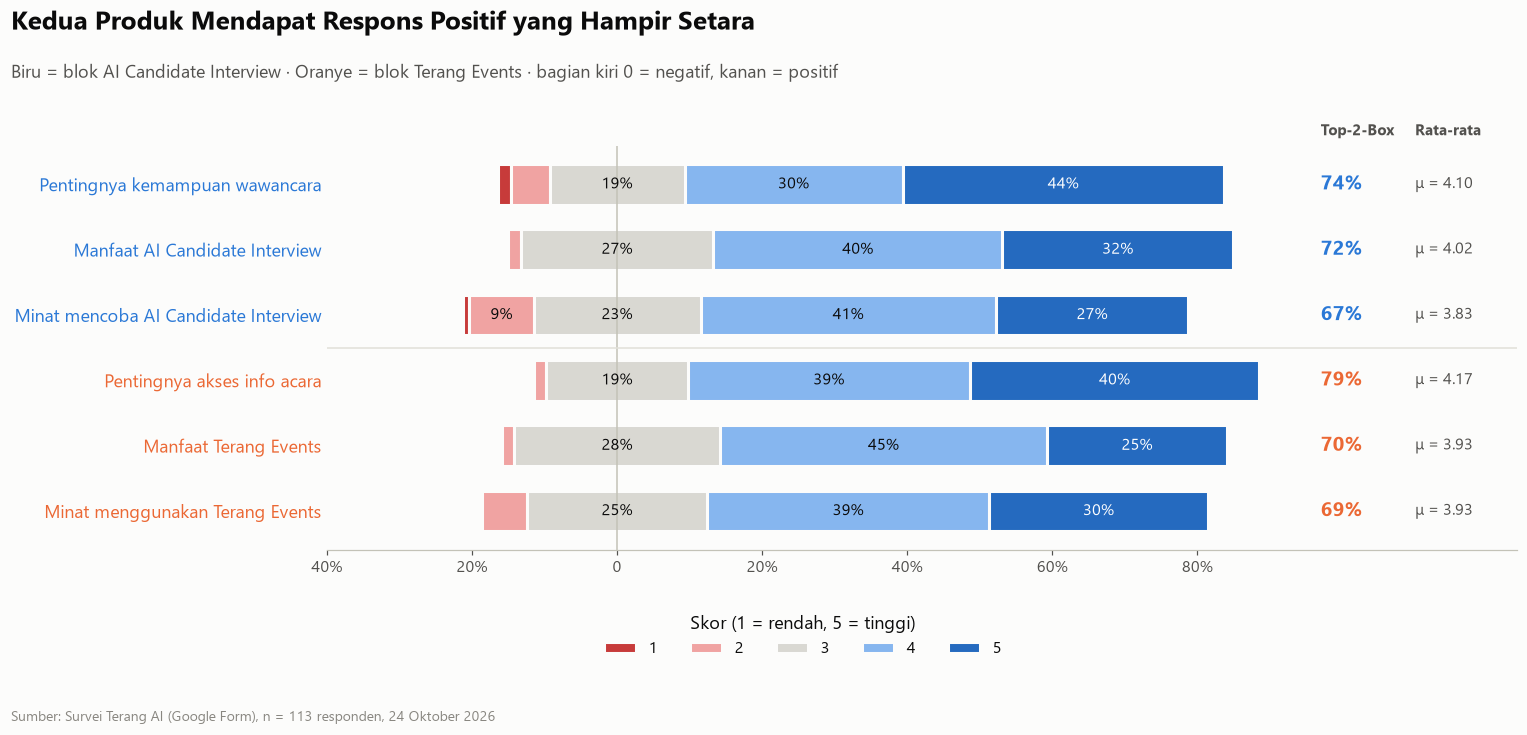

Uji Wilcoxon berpasangan (responden yang sama menilai kedua produk):
  Manfaat : AI 4.02 vs Events 3.93  → p = 0.350
  Minat   : AI 3.83 vs Events 3.93  → p = 0.392


> **💡 Insight:** Rata-rata skor manfaat dan minat kedua produk hanya berbeda tipis dan **tidak signifikan secara statistik** (Wilcoxon p manfaat = 0.35, p minat = 0.39). Dengan kata lain, dari sisi pengguna **tidak ada produk yang jelas lebih unggul**. Implikasinya: keputusan ONE vs ACE tidak bisa hanya didasarkan pada "produk mana yang lebih disukai", tetapi juga pada **potensi monetisasi B2B, kapasitas tim, dan sinergi** — yang dibahas di bagian selanjutnya.

In [17]:
items = [('penting_wawancara', 'Pentingnya kemampuan wawancara', 'AI'),
         ('manfaat_ai', 'Manfaat AI Candidate Interview', 'AI'),
         ('minat_ai', 'Minat mencoba AI Candidate Interview', 'AI'),
         ('penting_info', 'Pentingnya akses info acara', 'EV'),
         ('manfaat_ev', 'Manfaat Terang Events', 'EV'),
         ('minat_ev', 'Minat menggunakan Terang Events', 'EV')]
fig, ax = plt.subplots(figsize=(14, 5.4))
cols5 = [NEG2, NEG1, MID, POS1, POS2]
for i, (c, lab, grp) in enumerate(items):
    p = df[c].value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0) * 100
    start = -(p[1] + p[2] + p[3] / 2)
    for lvl in [1, 2, 3, 4, 5]:
        ax.barh(i, p[lvl], left=start, color=cols5[lvl - 1], height=0.62, edgecolor=SURF, linewidth=2,
                label=str(lvl) if i == 0 else None)
        if p[lvl] >= 8:
            ax.text(start + p[lvl] / 2, i, f'{p[lvl]:.0f}%', ha='center', va='center', fontsize=10.5,
                    color='white' if lvl in (1, 5) else INK)
        start += p[lvl]
    ax.text(97, i, f'{(p[4] + p[5]):.0f}%', va='center', ha='left', fontsize=13, weight='bold', color=AI if grp == 'AI' else EV)
    ax.text(110, i, f'μ = {df[c].mean():.2f}', va='center', ha='left', fontsize=10.5, color=INK2)
ax.text(97, -0.75, 'Top-2-Box', fontsize=10, color=INK2, weight='bold'); ax.text(110, -0.75, 'Rata-rata', fontsize=10, color=INK2, weight='bold')
ax.set_yticks(range(len(items))); ax.set_yticklabels([x[1] for x in items], fontsize=11.5)
for t, (_, _, g) in zip(ax.get_yticklabels(), items): t.set_color(AI if g == 'AI' else EV)
ax.axvline(0, color=BASE, lw=1); ax.set_xlim(-40, 124); ax.invert_yaxis()
ax.axhline(2.5, color=GRID, lw=1)
ax.set_xticks([-40, -20, 0, 20, 40, 60, 80]); ax.set_xticklabels(['40%', '20%', '0', '20%', '40%', '60%', '80%'])
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.legend(title='Skor (1 = rendah, 5 = tinggi)', ncol=5, loc='lower center', bbox_to_anchor=(0.4, -0.3))
titled(fig, 'Kedua Produk Mendapat Respons Positif yang Hampir Setara',
       'Biru = blok AI Candidate Interview · Oranye = blok Terang Events · bagian kiri 0 = negatif, kanan = positif')
save(fig, '14_likert_diverging')

w_m = stats.wilcoxon(df['manfaat_ai'], df['manfaat_ev'])
w_i = stats.wilcoxon(df['minat_ai'], df['minat_ev'])
print('Uji Wilcoxon berpasangan (responden yang sama menilai kedua produk):')
print(f"  Manfaat : AI {df['manfaat_ai'].mean():.2f} vs Events {df['manfaat_ev'].mean():.2f}  → p = {w_m.pvalue:.3f}")
print(f"  Minat   : AI {df['minat_ai'].mean():.2f} vs Events {df['minat_ev'].mean():.2f}  → p = {w_i.pvalue:.3f}")
insight(f"Rata-rata skor manfaat dan minat kedua produk hanya berbeda tipis dan **tidak signifikan secara statistik** "
        f"(Wilcoxon p manfaat = {w_m.pvalue:.2f}, p minat = {w_i.pvalue:.2f}). Dengan kata lain, dari sisi pengguna **tidak ada produk yang jelas "
        f"lebih unggul**. Implikasinya: keputusan ONE vs ACE tidak bisa hanya didasarkan pada \"produk mana yang lebih disukai\", tetapi juga "
        f"pada **potensi monetisasi B2B, kapasitas tim, dan sinergi** — yang dibahas di bagian selanjutnya.")

### 6.2 Pilihan relevansi & prioritas (dengan interval kepercayaan 95%)
Garis hitam pada tiap bar adalah **interval kepercayaan Wilson 95%** — bila garis dua kategori saling tumpang tindih, perbedaannya belum bisa dipastikan signifikan dengan n = 113.

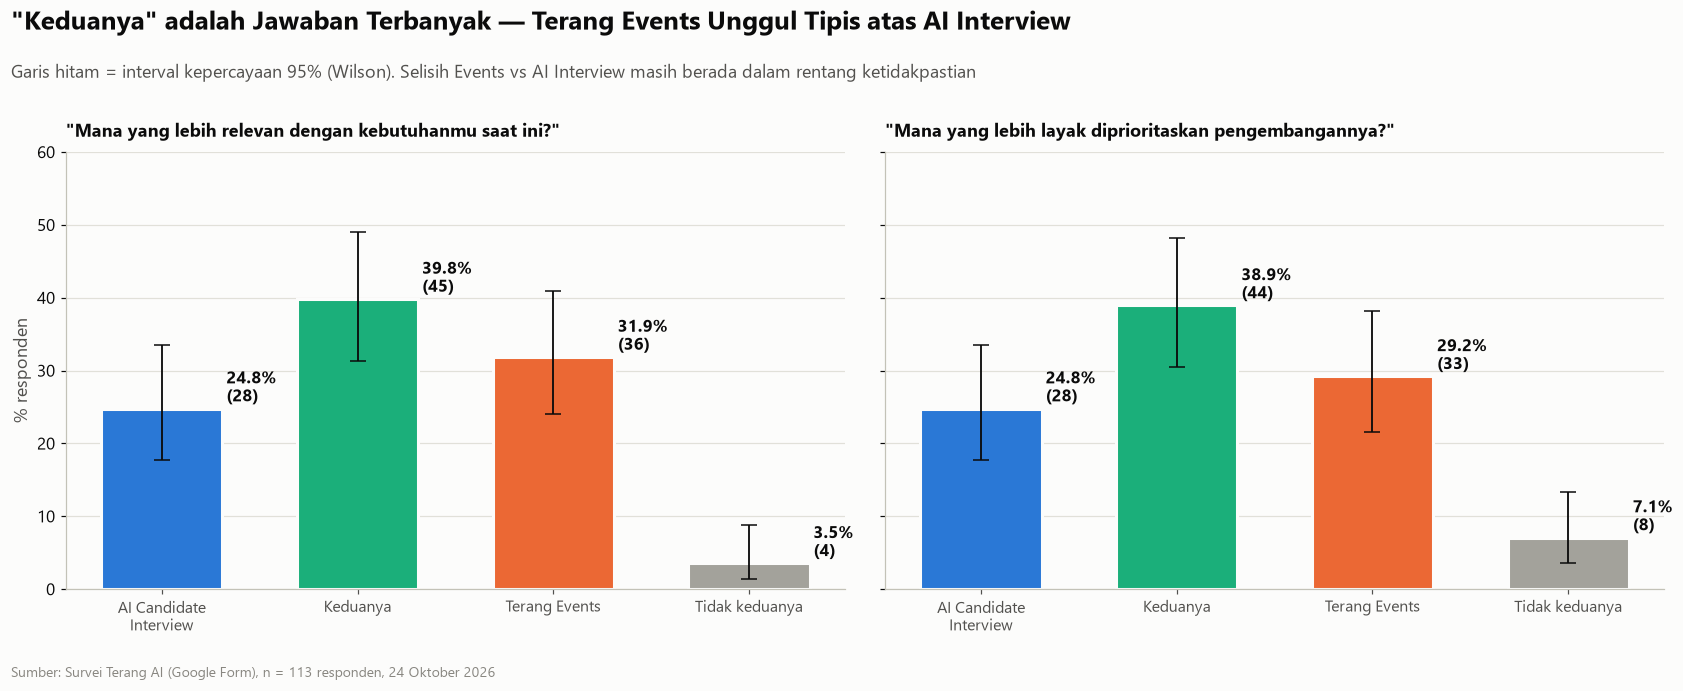

Uji binomial (Events vs AI Interview, di antara yang memilih salah satu produk):
  Relevansi : Events 36 vs AI 28  → p = 0.382
  Prioritas : Events 33 vs AI 28  → p = 0.609


> **💡 Insight:** **40%** responden menilai **keduanya sama relevan** dan **39%** menilai **keduanya sama penting** untuk diprioritaskan — kelompok terbesar di kedua pertanyaan. Jika dihitung jangkauan total, AI Candidate Interview relevan bagi **65%** responden (memilih AI atau keduanya) dan Terang Events bagi **72%**. Selisih Events vs AI Interview tidak signifikan (binomial p relevansi = 0.38; prioritas = 0.61).

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5), sharey=True)
for ax, col, ttl in zip(axes, ['pilih_relevan', 'pilih_prioritas'],
                        ['"Mana yang lebih relevan dengan kebutuhanmu saat ini?"', '"Mana yang lebih layak diprioritaskan pengembangannya?"']):
    vc = df[col].value_counts().reindex(CHOICE_ORDER, fill_value=0)
    p = vc / N * 100
    ci = np.array([wilson(k, N) for k in vc.values]) * 100
    bars = ax.bar(range(4), p.values, color=[CHOICE_COL[c] for c in CHOICE_ORDER], width=0.62, edgecolor=SURF, linewidth=2)
    ax.errorbar(range(4), p.values, yerr=[p.values - ci[:, 0], ci[:, 1] - p.values], fmt='none', ecolor=INK, elinewidth=1.2, capsize=5)
    for i, (v, k) in enumerate(zip(p.values, vc.values)):
        ax.text(i + 0.33, v + 1, f'{v:.1f}%\n({k})', ha='left', fontsize=11, weight='bold')
    ax.set_xticks(range(4)); ax.set_xticklabels([wrap(c, 14) for c in CHOICE_ORDER])
    ax.set_title(ttl, fontsize=12); ax.yaxis.grid(True); ax.set_axisbelow(True); ax.set_ylim(0, 60)
axes[0].set_ylabel('% responden')
titled(fig, '"Keduanya" adalah Jawaban Terbanyak — Terang Events Unggul Tipis atas AI Interview',
       'Garis hitam = interval kepercayaan 95% (Wilson). Selisih Events vs AI Interview masih berada dalam rentang ketidakpastian')
save(fig, '15_relevan_prioritas')

rel = df['pilih_relevan'].value_counts(); pri = df['pilih_prioritas'].value_counts()
bt_rel = stats.binomtest(rel['Terang Events'], rel['Terang Events'] + rel['AI Candidate Interview'])
bt_pri = stats.binomtest(pri['Terang Events'], pri['Terang Events'] + pri['AI Candidate Interview'])
print('Uji binomial (Events vs AI Interview, di antara yang memilih salah satu produk):')
print(f"  Relevansi : Events {rel['Terang Events']} vs AI {rel['AI Candidate Interview']}  → p = {bt_rel.pvalue:.3f}")
print(f"  Prioritas : Events {pri['Terang Events']} vs AI {pri['AI Candidate Interview']}  → p = {bt_pri.pvalue:.3f}")
any_ai = df['pilih_relevan'].isin(['AI Candidate Interview', 'Keduanya']).mean()
any_ev = df['pilih_relevan'].isin(['Terang Events', 'Keduanya']).mean()
insight(f"**{rel['Keduanya'] / N:.0%}** responden menilai **keduanya sama relevan** dan **{pri['Keduanya'] / N:.0%}** menilai **keduanya sama penting** untuk diprioritaskan — "
        f"kelompok terbesar di kedua pertanyaan. Jika dihitung jangkauan total, AI Candidate Interview relevan bagi **{any_ai:.0%}** responden "
        f"(memilih AI atau keduanya) dan Terang Events bagi **{any_ev:.0%}**. Selisih Events vs AI Interview tidak signifikan "
        f"(binomial p relevansi = {bt_rel.pvalue:.2f}; prioritas = {bt_pri.pvalue:.2f}).")

### 6.3 Konsistensi pilihan: dari "relevan" ke "prioritas"
Apakah orang yang menilai suatu produk relevan juga memprioritaskannya? Matriks ini menunjukkan **loyalitas pilihan**.

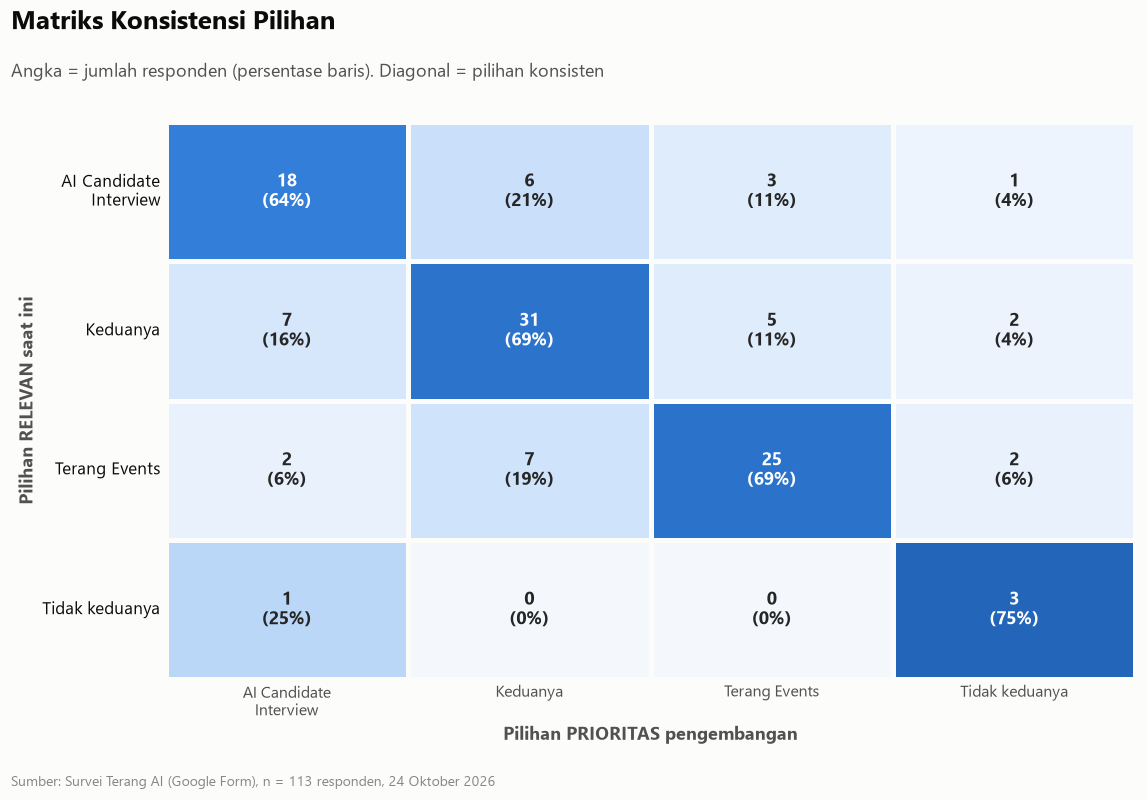

> **💡 Insight:** **68%** responden konsisten antara pilihan relevan dan prioritas. Retensi pilihan: AI Candidate Interview **64%**, Terang Events **69%**, Keduanya **69%**. Dari kelompok 'Keduanya relevan', saat dipaksa memprioritaskan, **7** orang beralih ke AI Interview dan **5** ke Events — kelompok tengah ini adalah *swing voter* yang menentukan arah strategi.

In [19]:
tr = pd.crosstab(df['pilih_relevan'], df['pilih_prioritas']).reindex(index=CHOICE_ORDER, columns=CHOICE_ORDER, fill_value=0)
trp = tr.div(tr.sum(axis=1), axis=0) * 100
annot = tr.astype(str) + '\n(' + trp.round(0).astype(int).astype(str) + '%)'
fig, ax = plt.subplots(figsize=(10.5, 6))
sns.heatmap(trp, annot=annot, fmt='', cmap=SEQ, cbar=False, linewidths=2, linecolor=SURF, vmin=0, vmax=100,
            annot_kws={'fontsize': 12, 'weight': 'bold'}, ax=ax)
ax.set_xticklabels([wrap(c, 14) for c in CHOICE_ORDER], rotation=0); ax.set_yticklabels([wrap(c, 14) for c in CHOICE_ORDER], rotation=0)
ax.set_xlabel('Pilihan PRIORITAS pengembangan', weight='bold'); ax.set_ylabel('Pilihan RELEVAN saat ini', weight='bold'); ax.tick_params(length=0)
titled(fig, 'Matriks Konsistensi Pilihan', 'Angka = jumlah responden (persentase baris). Diagonal = pilihan konsisten')
save(fig, '16_konsistensi_pilihan')
consist = np.trace(tr.values) / N
insight(f"**{consist:.0%}** responden konsisten antara pilihan relevan dan prioritas. Retensi pilihan: AI Candidate Interview **{trp.loc['AI Candidate Interview', 'AI Candidate Interview']:.0f}%**, "
        f"Terang Events **{trp.loc['Terang Events', 'Terang Events']:.0f}%**, Keduanya **{trp.loc['Keduanya', 'Keduanya']:.0f}%**. "
        f"Dari kelompok 'Keduanya relevan', saat dipaksa memprioritaskan, **{tr.loc['Keduanya', 'AI Candidate Interview']}** orang beralih ke AI Interview dan "
        f"**{tr.loc['Keduanya', 'Terang Events']}** ke Events — kelompok tengah ini adalah *swing voter* yang menentukan arah strategi.")

### 6.4 Peta permintaan ganda (*dual-demand quadrant*)
Setiap titik adalah satu responden, diplot berdasarkan **Indeks Permintaan AI Interview** (sumbu-x) dan **Indeks Permintaan Events** (sumbu-y). Indeks = rata-rata skor manfaat & minat (1–5). Garis putus pada 4,0 memisahkan permintaan tinggi vs rendah.

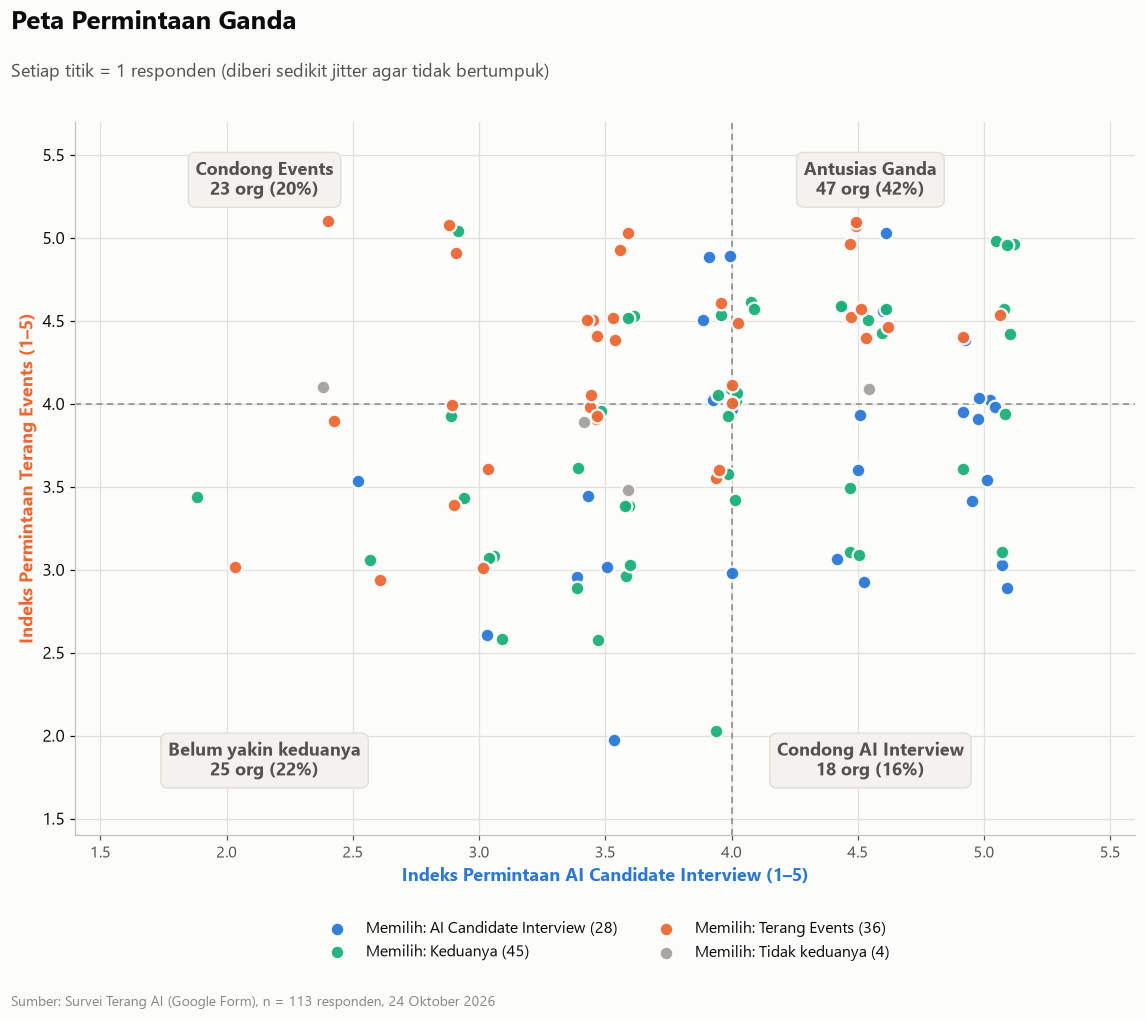

> **💡 Insight:** Kuadran **Antusias Ganda** berisi **47 responden (42%)** — mereka menilai kedua produk tinggi. Condong AI Interview: **16%**, condong Events: **20%**. Korelasi indeks AI–Events lemah (Spearman ρ = 0.23), artinya minat pada satu produk **bukan** prediktor minat pada produk lain: kedua produk melayani **kebutuhan yang berbeda**, walau penggunanya banyak yang sama.

In [20]:
rng = np.random.default_rng(7)
jx = df['idx_ai'] + rng.uniform(-0.12, 0.12, N); jy = df['idx_ev'] + rng.uniform(-0.12, 0.12, N)
fig, ax = plt.subplots(figsize=(10.5, 8))
for ch in CHOICE_ORDER:
    m = df['pilih_relevan'] == ch
    ax.scatter(jx[m], jy[m], s=80, color=CHOICE_COL[ch], edgecolor=SURF, linewidth=1.5, label=f'Memilih: {ch} ({m.sum()})', zorder=3, alpha=0.95)
ax.axvline(4, color=MUTED, lw=1, ls=(0, (4, 3))); ax.axhline(4, color=MUTED, lw=1, ls=(0, (4, 3)))
q = {'Antusias Ganda': ((df['idx_ai'] >= 4) & (df['idx_ev'] >= 4)),
     'Condong AI Interview': ((df['idx_ai'] >= 4) & (df['idx_ev'] < 4)),
     'Condong Events': ((df['idx_ai'] < 4) & (df['idx_ev'] >= 4)),
     'Belum yakin keduanya': ((df['idx_ai'] < 4) & (df['idx_ev'] < 4))}
pos = {'Antusias Ganda': (4.55, 5.35), 'Condong AI Interview': (4.55, 1.85), 'Condong Events': (2.15, 5.35), 'Belum yakin keduanya': (2.15, 1.85)}
for k, m in q.items():
    ax.text(*pos[k], f'{k}\n{m.sum()} org ({m.mean():.0%})', ha='center', va='center', fontsize=12, weight='bold', color=INK2,
            bbox=dict(boxstyle='round,pad=0.4', fc=PLANE, ec=GRID))
ax.set_xlim(1.4, 5.6); ax.set_ylim(1.4, 5.7)
ax.set_xlabel('Indeks Permintaan AI Candidate Interview (1–5)', color=AI, weight='bold')
ax.set_ylabel('Indeks Permintaan Terang Events (1–5)', color=EV, weight='bold')
ax.grid(True); ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=10.5)
titled(fig, 'Peta Permintaan Ganda', 'Setiap titik = 1 responden (diberi sedikit jitter agar tidak bertumpuk)')
save(fig, '17_dual_demand_quadrant')
r_s = stats.spearmanr(df['idx_ai'], df['idx_ev'])
insight(f"Kuadran **Antusias Ganda** berisi **{q['Antusias Ganda'].sum()} responden ({q['Antusias Ganda'].mean():.0%})** — mereka menilai kedua produk tinggi. "
        f"Condong AI Interview: **{q['Condong AI Interview'].mean():.0%}**, condong Events: **{q['Condong Events'].mean():.0%}**. "
        f"Korelasi indeks AI–Events lemah (Spearman ρ = {r_s.statistic:.2f}), artinya minat pada satu produk **bukan** prediktor minat pada produk lain: "
        f"kedua produk melayani **kebutuhan yang berbeda**, walau penggunanya banyak yang sama.")

## 7. Segmentasi: Siapa Memilih Apa?

Preferensi responden dipecah berdasarkan karakteristik: **tahap karier**, **usia**, **peran di acara**, dan **cara berlatih wawancara**. Tujuannya: menemukan segmen yang menjadi *beachhead* masing-masing produk.

> ⚠️ Beberapa segmen berukuran kecil (n < 15). Angka pada segmen kecil dibaca sebagai **indikasi arah**, bukan kesimpulan pasti.

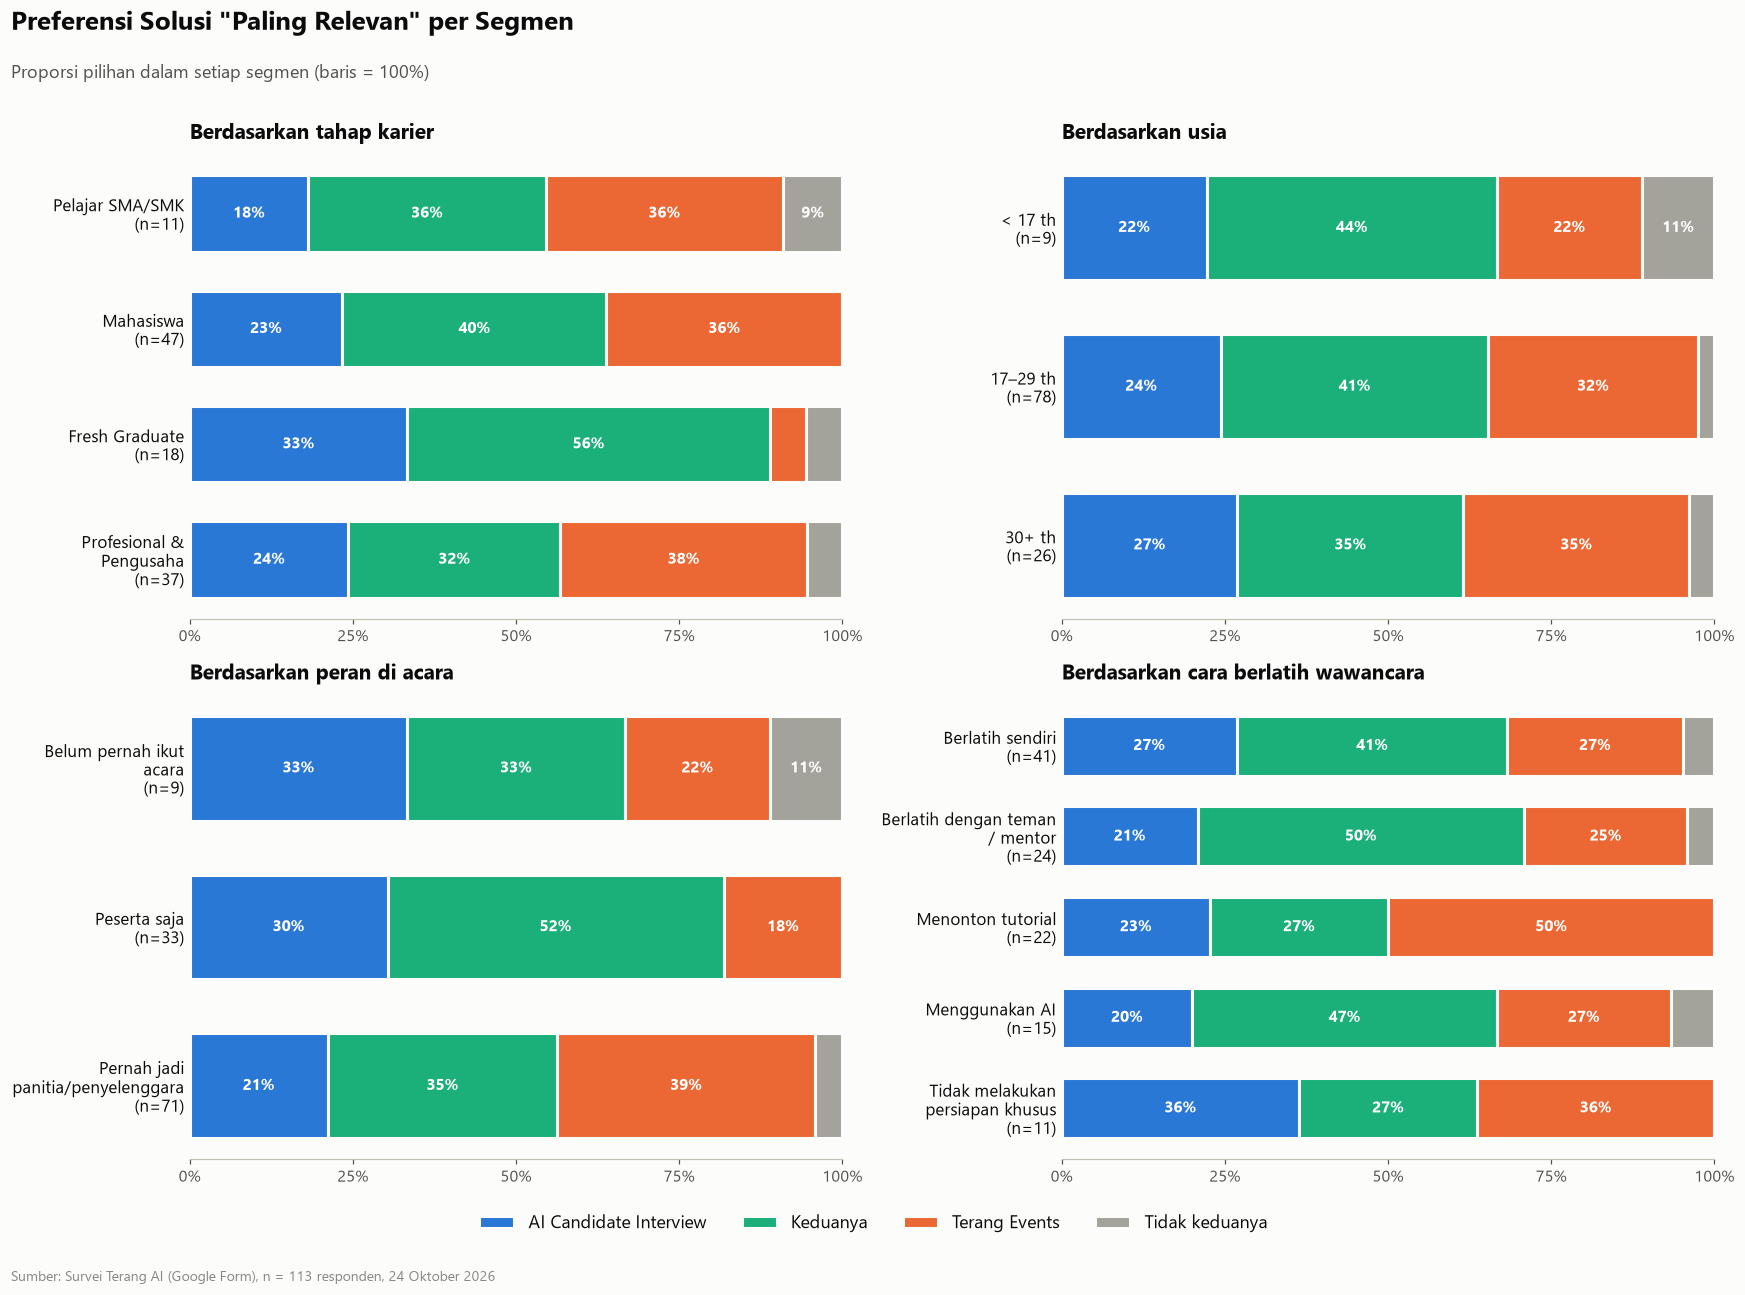

In [21]:
def stacked_share(ax, seg, order, title, col='pilih_relevan'):
    ct = pd.crosstab(df[seg], df[col]).reindex(index=order, columns=CHOICE_ORDER, fill_value=0)
    p = ct.div(ct.sum(axis=1), axis=0) * 100
    left = np.zeros(len(p))
    ylabels = [f'{wrap(i, 22)}\n(n={ct.loc[i].sum()})' for i in order]
    for ch in CHOICE_ORDER:
        ax.barh(ylabels, p[ch], left=left, color=CHOICE_COL[ch], edgecolor=SURF, linewidth=2, height=0.66, label=ch)
        for i, v in enumerate(p[ch]):
            if v >= 9: ax.text(left[i] + v / 2, i, f'{v:.0f}%', ha='center', va='center', fontsize=10.5, color='white', weight='bold')
        left += p[ch].values
    ax.set_xlim(0, 100); ax.invert_yaxis(); ax.set_title(title)
    ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0); ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'])

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
stacked_share(axes[0, 0], 'tahap', TAHAP_ORDER, 'Berdasarkan tahap karier')
stacked_share(axes[0, 1], 'usia_seg', ['< 17 th', '17–29 th', '30+ th'], 'Berdasarkan usia')
stacked_share(axes[1, 0], 'peran_acara', PERAN_ORDER, 'Berdasarkan peran di acara')
stacked_share(axes[1, 1], 'cara_latihan', df['cara_latihan'].value_counts().index.tolist(), 'Berdasarkan cara berlatih wawancara')
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.04), fontsize=11.5)
titled(fig, 'Preferensi Solusi "Paling Relevan" per Segmen', 'Proporsi pilihan dalam setiap segmen (baris = 100%)', note=None)
fig.text(0.01, -0.07, SOURCE, fontsize=9, color=MUTED)
save(fig, '18_preferensi_per_segmen')

In [22]:
seg_tbl = []
for seg, order in [('tahap', TAHAP_ORDER), ('usia_seg', ['< 17 th', '17–29 th', '30+ th']), ('peran_acara', PERAN_ORDER),
                   ('cara_latihan', df['cara_latihan'].value_counts().index.tolist())]:
    for g in order:
        s = df[df[seg] == g]
        seg_tbl.append({'Dimensi': seg, 'Segmen': g, 'n': len(s),
                        'AI Interview (%)': (s['pilih_relevan'] == 'AI Candidate Interview').mean() * 100,
                        'Keduanya (%)': (s['pilih_relevan'] == 'Keduanya').mean() * 100,
                        'Terang Events (%)': (s['pilih_relevan'] == 'Terang Events').mean() * 100,
                        'Minat AI T2B (%)': s['t2b_minat_ai'].mean() * 100, 'Minat Events T2B (%)': s['t2b_minat_ev'].mean() * 100})
seg_tbl = pd.DataFrame(seg_tbl)
display(seg_tbl.round(1).style.background_gradient(cmap=SEQ, subset=['AI Interview (%)', 'Minat AI T2B (%)'])
        .background_gradient(cmap=SEQ_EV, subset=['Terang Events (%)', 'Minat Events T2B (%)']).format(precision=1))

t = seg_tbl.set_index('Segmen')
fg = df[df['tahap'] == 'Fresh Graduate']['pilih_relevan'].value_counts(normalize=True)
pe = df[df['pekerjaan'] == 'Pengusaha']['pilih_relevan'].value_counts(normalize=True)
insight(f"**Fresh graduate** adalah segmen paling 'AI-first': {t.loc['Fresh Graduate', 'AI Interview (%)']:.0f}% memilih AI Interview + "
        f"{t.loc['Fresh Graduate', 'Keduanya (%)']:.0f}% memilih keduanya, dan **hanya {t.loc['Fresh Graduate', 'Terang Events (%)']:.0f}%** yang memilih Events saja — "
        f"mereka sedang aktif melamar kerja pertama (beachhead ONE). Sebaliknya, responden yang **pernah menjadi panitia/penyelenggara** paling condong ke Terang Events "
        f"({t.loc['Pernah jadi panitia/penyelenggara', 'Terang Events (%)']:.0f}%), begitu pula **pengusaha** ({pe.get('Terang Events', 0):.0%} memilih Events, n kecil = {(df.pekerjaan == 'Pengusaha').sum()}). "
        f"**Mahasiswa** (segmen terbesar) terbelah antara keduanya ({t.loc['Mahasiswa', 'Keduanya (%)']:.0f}%) dan Events ({t.loc['Mahasiswa', 'Terang Events (%)']:.0f}%) — "
        f"*bridge segment* yang membutuhkan kedua produk (basis argumen ACE).",
        icon='🎯', label='Insight segmen')

,Dimensi,Segmen,n,AI Interview (%),Keduanya (%),Terang Events (%),Minat AI T2B (%),Minat Events T2B (%)
0,tahap,Pelajar SMA/SMK,11,18.2,36.4,36.4,72.7,81.8
1,tahap,Mahasiswa,47,23.4,40.4,36.2,68.1,68.1
2,tahap,Fresh Graduate,18,33.3,55.6,5.6,66.7,61.1
3,tahap,Profesional & Pengusaha,37,24.3,32.4,37.8,64.9,70.3
4,usia_seg,< 17 th,9,22.2,44.4,22.2,77.8,88.9
5,usia_seg,17–29 th,78,24.4,41.0,32.1,69.2,67.9
6,usia_seg,30+ th,26,26.9,34.6,34.6,57.7,65.4
7,peran_acara,Belum pernah ikut acara,9,33.3,33.3,22.2,77.8,77.8
8,peran_acara,Peserta saja,33,30.3,51.5,18.2,75.8,60.6
9,peran_acara,Pernah jadi panitia/penyelenggara,71,21.1,35.2,39.4,62.0,71.8


> **🎯 Insight segmen:** **Fresh graduate** adalah segmen paling 'AI-first': 33% memilih AI Interview + 56% memilih keduanya, dan **hanya 6%** yang memilih Events saja — mereka sedang aktif melamar kerja pertama (beachhead ONE). Sebaliknya, responden yang **pernah menjadi panitia/penyelenggara** paling condong ke Terang Events (39%), begitu pula **pengusaha** (56% memilih Events, n kecil = 9). **Mahasiswa** (segmen terbesar) terbelah antara keduanya (40%) dan Events (36%) — *bridge segment* yang membutuhkan kedua produk (basis argumen ACE).

### 7.1 *Dumbbell chart*: minat AI Interview vs Events di setiap segmen
Titik biru = % berminat (skor 4–5) pada AI Candidate Interview, titik oranye = pada Terang Events. Semakin panjang garis penghubung, semakin besar perbedaan minat dalam segmen tersebut.

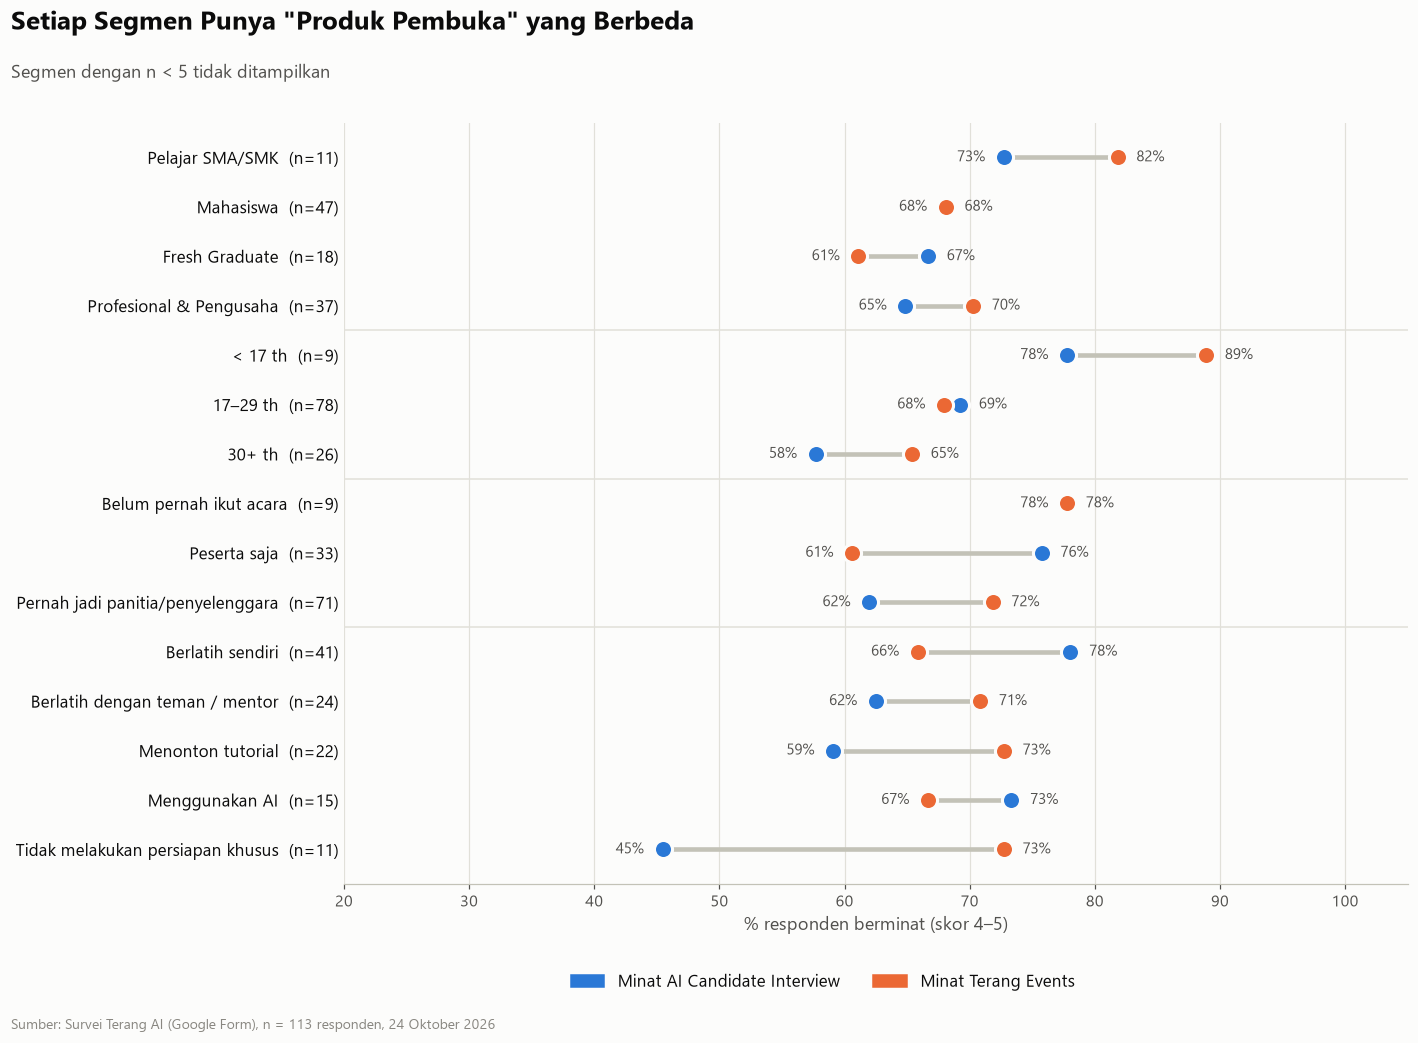

In [23]:
rows = seg_tbl[seg_tbl['n'] >= 5].copy()
rows['label'] = rows['Segmen'] + '  (n=' + rows['n'].astype(str) + ')'
fig, ax = plt.subplots(figsize=(13, 8.2))
y = np.arange(len(rows))[::-1]
dims = rows['Dimensi'].tolist()
for yi, (_, r) in zip(y, rows.iterrows()):
    a, e = r['Minat AI T2B (%)'], r['Minat Events T2B (%)']
    ax.plot([a, e], [yi, yi], color=BASE, lw=3, zorder=1, solid_capstyle='round')
    ax.scatter(a, yi, s=140, color=AI, zorder=3, edgecolor=SURF, linewidth=2)
    ax.scatter(e, yi, s=140, color=EV, zorder=3, edgecolor=SURF, linewidth=2)
    lo, hi = (a, e) if a < e else (e, a)
    ax.text(lo - 1.5, yi, f'{lo:.0f}%', ha='right', va='center', fontsize=10, color=INK2)
    ax.text(hi + 1.5, yi, f'{hi:.0f}%', ha='left', va='center', fontsize=10, color=INK2)
for i in range(1, len(dims)):
    if dims[i] != dims[i - 1]: ax.axhline(y[i] + 0.5, color=GRID, lw=1)
ax.set_yticks(y); ax.set_yticklabels(rows['label'])
ax.set_xlim(20, 105); ax.set_xlabel('% responden berminat (skor 4–5)'); ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.legend(handles=[mpatches.Patch(color=AI, label='Minat AI Candidate Interview'), mpatches.Patch(color=EV, label='Minat Terang Events')],
          loc='lower center', bbox_to_anchor=(0.45, -0.16), ncol=2, fontsize=11)
titled(fig, 'Setiap Segmen Punya "Produk Pembuka" yang Berbeda', 'Segmen dengan n < 5 tidak ditampilkan')
save(fig, '19_dumbbell_minat_segmen')

### 7.2 Heatmap profil metrik per tahap karier

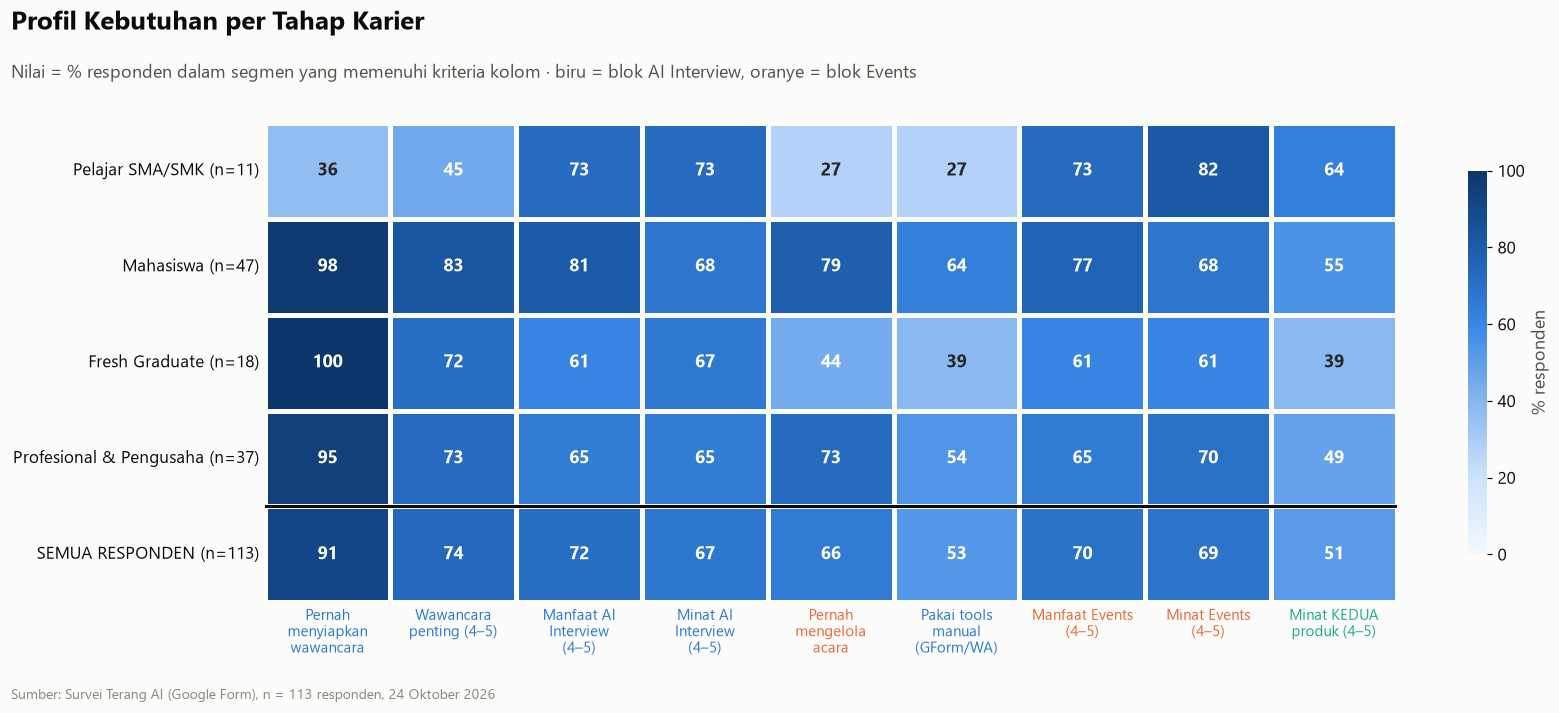

> **💡 Insight:** Pelajar SMA/SMK sebagian besar **belum pernah** menyiapkan wawancara (64% belum) — mereka lebih cocok sebagai pasar **edukasi/persiapan awal** (B2C), bukan target awal. **Mahasiswa** unggul di dua sisi sekaligus: proporsi tertinggi yang pernah mengelola acara (79%) dan yang melihat manfaat AI Interview (81%). Mahasiswa adalah titik temu kedua kebutuhan — segmen paling strategis untuk *cross-sell*, sedangkan Fresh Graduate (100% pernah menyiapkan wawancara, hanya 44% pernah mengelola acara) adalah segmen murni AI Interview.

In [24]:
metrics = {'Pernah menyiapkan wawancara': 'pernah_wwc', 'Wawancara penting (4–5)': 't2b_penting_wawancara',
           'Manfaat AI Interview (4–5)': 't2b_manfaat_ai', 'Minat AI Interview (4–5)': 't2b_minat_ai',
           'Pernah mengelola acara': 'pengelola', 'Pakai tools manual (GForm/WA)': 'tools_manual',
           'Manfaat Events (4–5)': 't2b_manfaat_ev', 'Minat Events (4–5)': 't2b_minat_ev', 'Minat KEDUA produk (4–5)': 't2b_both'}
hm = pd.DataFrame({k: df.groupby('tahap')[v].mean() * 100 for k, v in metrics.items()}).reindex(TAHAP_ORDER)
hm.loc['SEMUA RESPONDEN'] = [df[v].mean() * 100 for v in metrics.values()]
fig, ax = plt.subplots(figsize=(15.5, 5.2))
sns.heatmap(hm, annot=True, fmt='.0f', cmap=SEQ, cbar_kws={'label': '% responden', 'shrink': 0.8}, linewidths=2, linecolor=SURF,
            annot_kws={'fontsize': 12, 'weight': 'bold'}, vmin=0, vmax=100, ax=ax)
ax.set_xticklabels([wrap(c, 14) for c in hm.columns], rotation=0, fontsize=10)
ax.set_yticklabels([f'{i} (n={(df.tahap == i).sum() if i in TAHAP_ORDER else N})' for i in hm.index], rotation=0)
ax.set_ylabel(''); ax.tick_params(length=0); ax.axhline(len(TAHAP_ORDER), color=INK, lw=2)
for i, c in enumerate(hm.columns):
    cl_ = c.lower()
    ax.get_xticklabels()[i].set_color(BOTH if 'kedua' in cl_ else (AI if ('ai' in cl_ or 'wawancara' in cl_) else EV))
titled(fig, 'Profil Kebutuhan per Tahap Karier', 'Nilai = % responden dalam segmen yang memenuhi kriteria kolom · biru = blok AI Interview, oranye = blok Events')
save(fig, '20_heatmap_tahap_karier')
seg4 = hm.drop(index='SEMUA RESPONDEN')
s_mg, s_ai = seg4['Pernah mengelola acara'].idxmax(), seg4['Manfaat AI Interview (4–5)'].idxmax()
lead = (f"**{s_mg}** unggul di dua sisi sekaligus: proporsi tertinggi yang pernah mengelola acara ({seg4[ 'Pernah mengelola acara'].max():.0f}%) "
        f"dan yang melihat manfaat AI Interview ({seg4['Manfaat AI Interview (4–5)'].max():.0f}%)." if s_mg == s_ai else
        f"**{s_mg}** memiliki proporsi tertinggi yang pernah mengelola acara ({seg4['Pernah mengelola acara'].max():.0f}%), sedangkan "
        f"**{s_ai}** paling tinggi melihat manfaat AI Interview ({seg4['Manfaat AI Interview (4–5)'].max():.0f}%).")
insight(f"Pelajar SMA/SMK sebagian besar **belum pernah** menyiapkan wawancara ({1 - hm.loc['Pelajar SMA/SMK', 'Pernah menyiapkan wawancara'] / 100:.0%} belum) — "
        f"mereka lebih cocok sebagai pasar **edukasi/persiapan awal** (B2C), bukan target awal. {lead} "
        f"Mahasiswa adalah titik temu kedua kebutuhan — segmen paling strategis untuk *cross-sell*, "
        f"sedangkan Fresh Graduate (100% pernah menyiapkan wawancara, hanya {hm.loc['Fresh Graduate', 'Pernah mengelola acara']:.0f}% pernah mengelola acara) adalah segmen murni AI Interview.")

### 7.3 Uji asosiasi Chi-square & Cramér's V
Apakah karakteristik responden **berhubungan secara statistik** dengan pilihan solusi? Cramér's V mengukur kekuatan hubungan (0 = tidak ada, 0,1 = lemah, 0,3 = sedang, ≥0,5 = kuat).

,Karakteristik,Target,Cramér's V,p-value,% sel expected<5
15,sumber_info,pilih_prioritas,0.234,0.030,50.000
3,pekerjaan,pilih_prioritas,0.228,0.287,66.667
2,pekerjaan,pilih_relevan,0.219,0.370,66.667
7,peran_acara,pilih_prioritas,0.214,0.110,41.667
12,pernah_wawancara,pilih_relevan,0.200,0.330,55.000
6,peran_acara,pilih_relevan,0.198,0.182,50.000
1,tahap,pilih_prioritas,0.185,0.238,50.000
9,kelola_acara,pilih_prioritas,0.175,0.319,43.750
0,tahap,pilih_relevan,0.174,0.328,50.000
5,usia_seg,pilih_prioritas,0.165,0.407,41.667


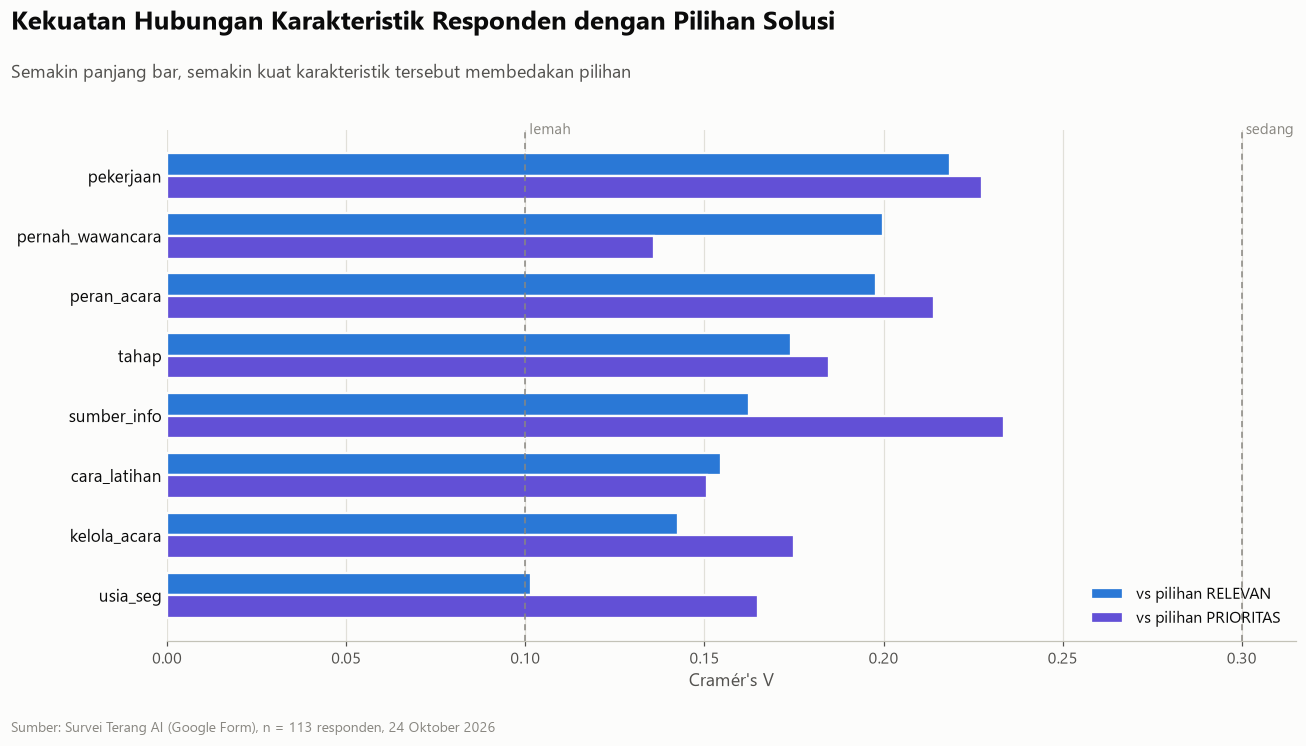

> **💡 Insight:** Hubungan terkuat: **sumber_info** terhadap **pilih_prioritas** (V = 0.23, p = 0.030). Hanya **1 dari 16** pasangan yang signifikan pada α = 5%, dan banyak sel ber-*expected* < 5 sehingga hasil uji perlu dibaca hati-hati. Kesimpulannya: **tidak ada karakteristik tunggal yang secara kuat menentukan pilihan produk** — preferensi tersebar di semua segmen. Pola arah di bagian 7 (fresh graduate → AI, panitia → Events) tetap berguna sebagai hipotesis *targeting*, tetapi perlu divalidasi lewat pilot (memperkuat **Product–Market Validation Gap**).

In [25]:
res = []
for seg in ['tahap', 'pekerjaan', 'usia_seg', 'peran_acara', 'kelola_acara', 'cara_latihan', 'pernah_wawancara', 'sumber_info']:
    for tgt in ['pilih_relevan', 'pilih_prioritas']:
        ct = pd.crosstab(df[seg], df[tgt])
        v, p, low = cramers_v(ct)
        res.append({'Karakteristik': seg, 'Target': tgt, "Cramér's V": v, 'p-value': p, '% sel expected<5': low * 100})
res = pd.DataFrame(res).sort_values("Cramér's V", ascending=False)
display(res.round(3).style.background_gradient(cmap=SEQ, subset=["Cramér's V"]).format(precision=3))

fig, ax = plt.subplots(figsize=(12, 5.5))
piv = res.pivot(index='Karakteristik', columns='Target', values="Cramér's V").sort_values('pilih_relevan')
yy = np.arange(len(piv))
ax.barh(yy + 0.19, piv['pilih_relevan'], height=0.38, color=AI, label='vs pilihan RELEVAN', edgecolor=SURF, linewidth=1.5)
ax.barh(yy - 0.19, piv['pilih_prioritas'], height=0.38, color=VIOLET, label='vs pilihan PRIORITAS', edgecolor=SURF, linewidth=1.5)
ax.set_yticks(yy); ax.set_yticklabels(piv.index)
ax.axvline(0.1, color=MUTED, lw=1, ls=(0, (4, 3))); ax.axvline(0.3, color=MUTED, lw=1, ls=(0, (4, 3)))
ax.text(0.1, len(piv) - 0.3, ' lemah', color=MUTED, fontsize=9.5); ax.text(0.3, len(piv) - 0.3, ' sedang', color=MUTED, fontsize=9.5)
ax.set_xlabel("Cramér's V"); ax.xaxis.grid(True); ax.set_axisbelow(True); ax.legend(loc='lower right')
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
titled(fig, 'Kekuatan Hubungan Karakteristik Responden dengan Pilihan Solusi',
       'Semakin panjang bar, semakin kuat karakteristik tersebut membedakan pilihan')
save(fig, '21_cramers_v')
sig = res[res['p-value'] < 0.05]
top_r = res.iloc[0]; top_v = top_r["Cramér's V"]
insight(f"Hubungan terkuat: **{top_r['Karakteristik']}** terhadap **{top_r['Target']}** (V = {top_v:.2f}, p = {top_r['p-value']:.3f}). "
        f"Hanya **{len(sig)} dari {len(res)}** pasangan yang signifikan pada α = 5%, dan banyak sel ber-*expected* < 5 sehingga hasil uji perlu dibaca hati-hati. "
        "Kesimpulannya: **tidak ada karakteristik tunggal yang secara kuat menentukan pilihan produk** — preferensi tersebar di semua segmen. "
        "Pola arah di bagian 7 (fresh graduate → AI, panitia → Events) tetap berguna sebagai hipotesis *targeting*, tetapi perlu divalidasi lewat pilot "
        "(memperkuat **Product–Market Validation Gap**).")

## 8. *Driver Analysis*: Apa yang Mendorong Minat?
Korelasi Spearman antara karakteristik/perilaku responden dengan **minat AI Interview** dan **minat Terang Events**. Bar ke kanan = mendorong minat, ke kiri = menurunkan minat.

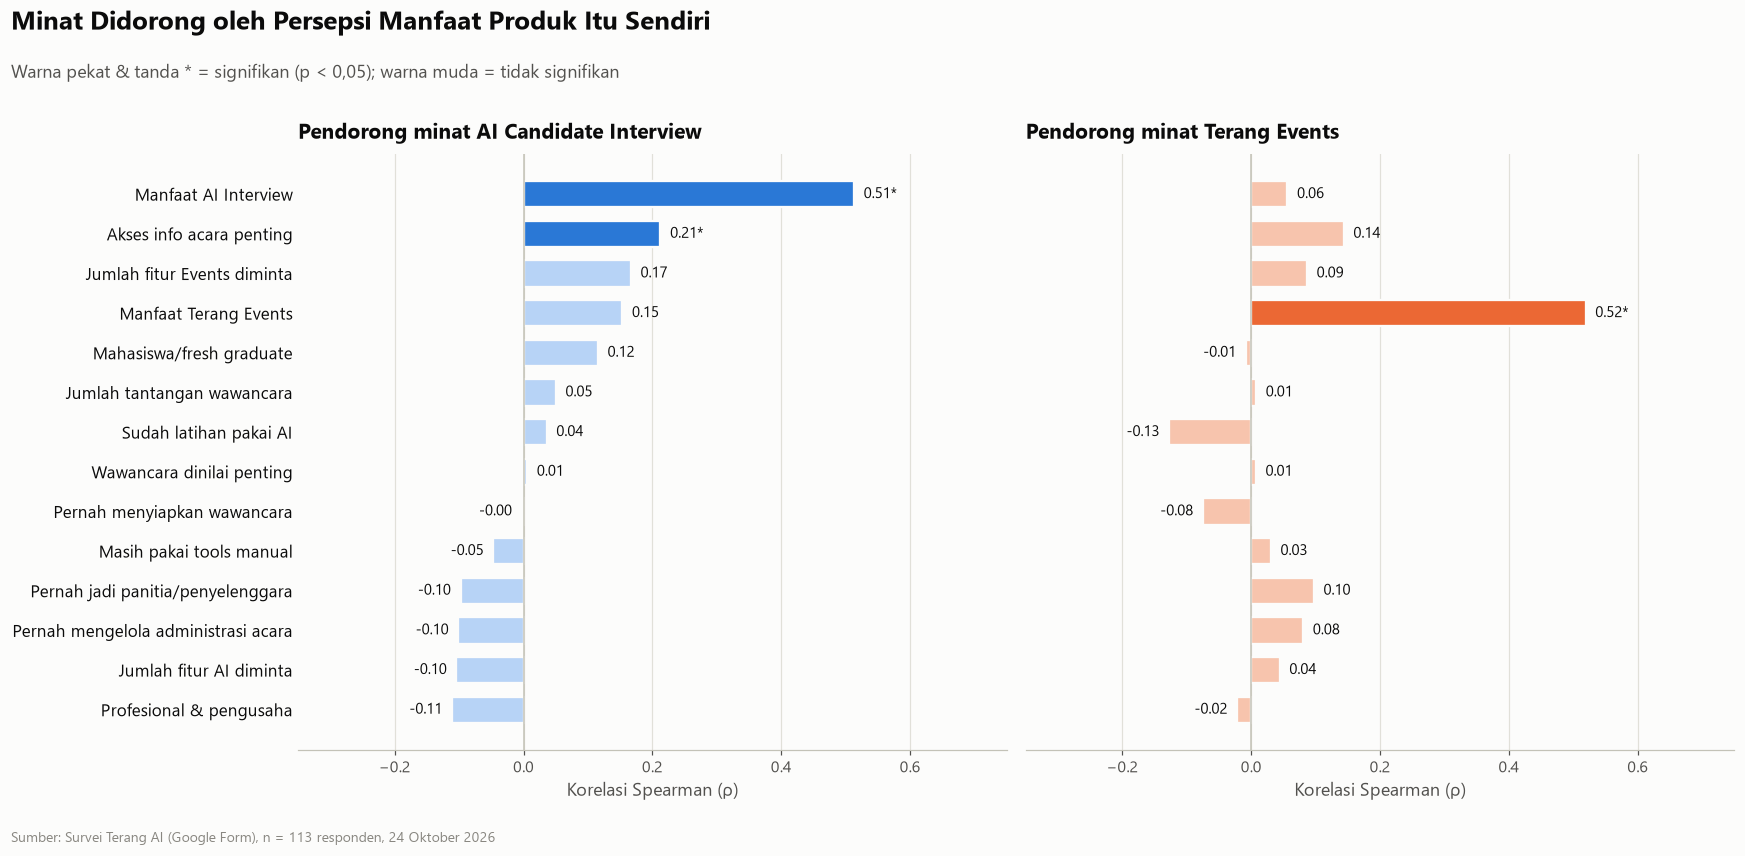

> **💡 Insight:** Pendorong terkuat minat AI Interview adalah **persepsi manfaat AI Interview** (ρ = 0.51), dan untuk Events adalah **persepsi manfaat Events** (ρ = 0.52). Korelasi silang (manfaat produk A → minat produk B) jauh lebih lemah. Implikasi strategis: **adopsi dibangun lewat pembuktian manfaat** (demo, pilot, studi kasus) — bukan lewat demografi. Ini mendukung pilar *Evaluate for Expansion* (ONE) maupun *Evaluate and Evolve Portfolio* (ACE).

In [26]:
drivers = pd.DataFrame({
    'Wawancara dinilai penting': df['penting_wawancara'],
    'Manfaat AI Interview': df['manfaat_ai'],
    'Akses info acara penting': df['penting_info'],
    'Manfaat Terang Events': df['manfaat_ev'],
    'Pernah menyiapkan wawancara': df['pernah_wwc'],
    'Pernah jadi panitia/penyelenggara': (df['peran_acara'] == 'Pernah jadi panitia/penyelenggara').astype(int),
    'Pernah mengelola administrasi acara': df['pengelola'],
    'Masih pakai tools manual': df['tools_manual'],
    'Sudah latihan pakai AI': df['latihan_ai'],
    'Jumlah tantangan wawancara': df['n_tantangan'],
    'Jumlah fitur AI diminta': df['n_fitur_ai'],
    'Jumlah fitur Events diminta': df['n_fitur_ev'],
    'Mahasiswa/fresh graduate': df['tahap'].isin(['Mahasiswa', 'Fresh Graduate']).astype(int),
    'Profesional & pengusaha': (df['tahap'] == 'Profesional & Pengusaha').astype(int),
})
cor = pd.DataFrame({t: {c: stats.spearmanr(drivers[c], df[t]) for c in drivers} for t in ['minat_ai', 'minat_ev']})
rho = cor.map(lambda r: r.statistic); pv = cor.map(lambda r: r.pvalue)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
order = rho['minat_ai'].sort_values().index
for ax, t, col, ttl in zip(axes, ['minat_ai', 'minat_ev'], [AI, EV], ['Pendorong minat AI Candidate Interview', 'Pendorong minat Terang Events']):
    vals = rho.loc[order, t]
    ax.barh(order, vals, color=[col if pv.loc[i, t] < 0.05 else (AI_T if t == 'minat_ai' else EV_T) for i in order], height=0.66,
            edgecolor=SURF, linewidth=1.5)
    for i, (v, p) in enumerate(zip(vals, pv.loc[order, t])):
        ax.text(v + (0.015 if v >= 0 else -0.015), i, f'{v:.2f}{"*" if p < 0.05 else ""}', va='center', ha='left' if v >= 0 else 'right', fontsize=10)
    ax.axvline(0, color=BASE, lw=1); ax.set_xlim(-0.35, 0.75); ax.set_title(ttl); ax.xaxis.grid(True); ax.set_axisbelow(True)
    ax.set_xlabel('Korelasi Spearman (ρ)'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
titled(fig, 'Minat Didorong oleh Persepsi Manfaat Produk Itu Sendiri',
       'Warna pekat & tanda * = signifikan (p < 0,05); warna muda = tidak signifikan')
save(fig, '22_driver_analysis')
insight(f"Pendorong terkuat minat AI Interview adalah **persepsi manfaat AI Interview** (ρ = {rho.loc['Manfaat AI Interview', 'minat_ai']:.2f}), dan untuk Events adalah "
        f"**persepsi manfaat Events** (ρ = {rho.loc['Manfaat Terang Events', 'minat_ev']:.2f}). Korelasi silang (manfaat produk A → minat produk B) jauh lebih lemah. "
        f"Implikasi strategis: **adopsi dibangun lewat pembuktian manfaat** (demo, pilot, studi kasus) — bukan lewat demografi. Ini mendukung pilar "
        f"*Evaluate for Expansion* (ONE) maupun *Evaluate and Evolve Portfolio* (ACE).")

## 9. Clustering & Persona Responden
Menggunakan **K-Means** pada 6 skala Likert (distandardisasi) untuk menemukan kelompok responden alami. Jumlah klaster dipilih berdasarkan **silhouette score** (rentang 3–5 klaster agar persona tetap bermakna), lalu divisualisasikan dengan **PCA 2 dimensi**.

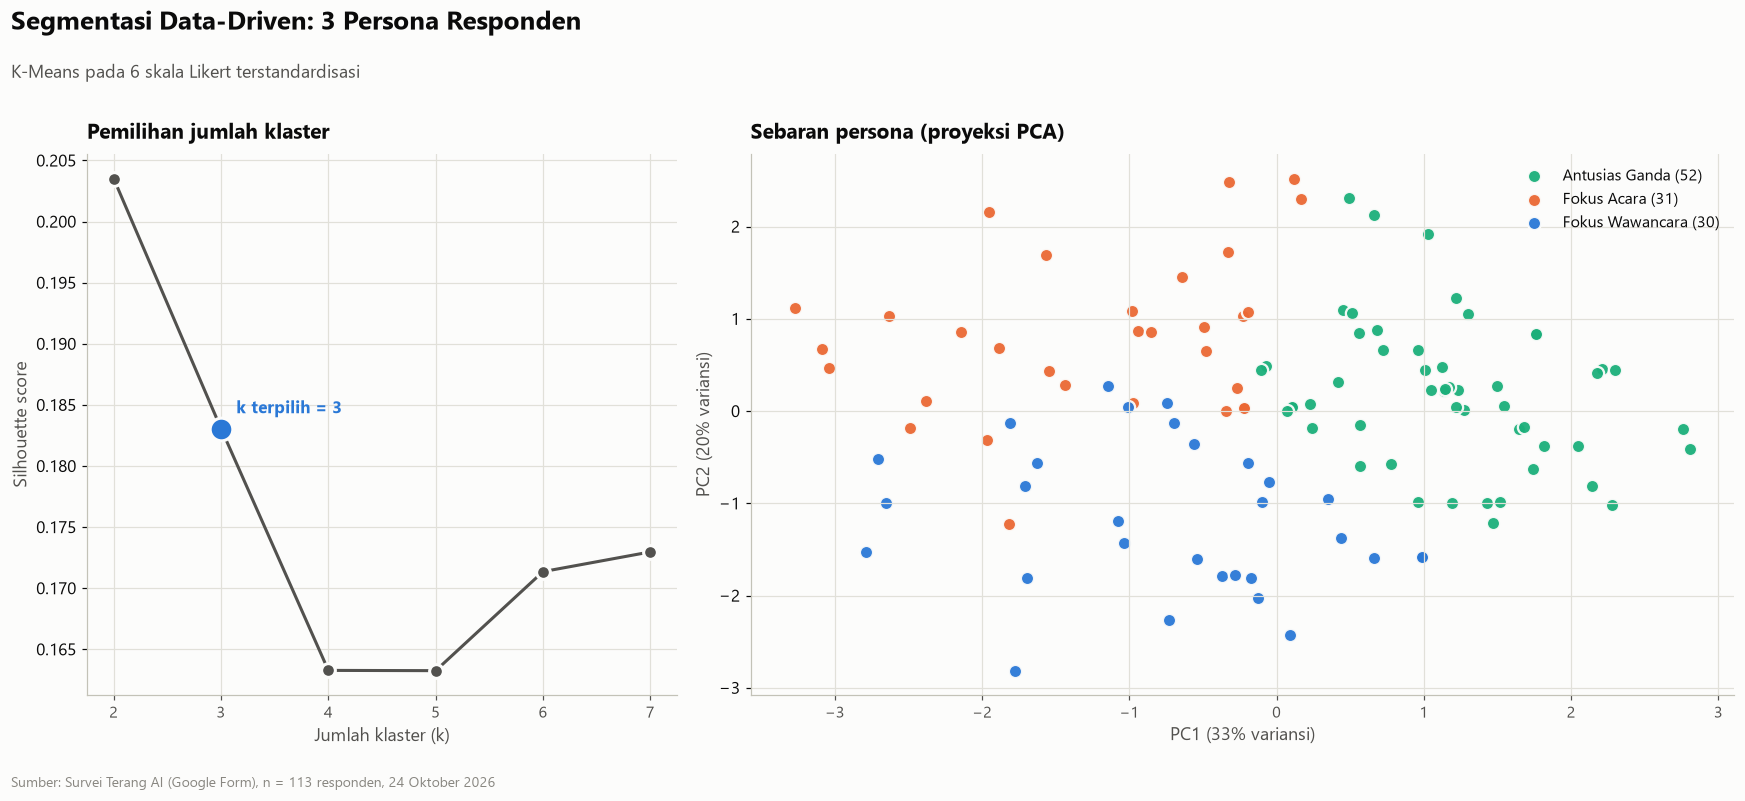

,penting_wawancara,manfaat_ai,minat_ai,penting_info,manfaat_ev,minat_ev,idx_ai,idx_ev,n
Persona,,,,,,,,,
Antusias Ganda,4.15,4.37,4.31,4.46,4.44,4.48,4.34,4.46,52
Fokus Acara,3.94,3.29,3.00,3.39,3.77,3.90,3.15,3.84,31
Fokus Wawancara,4.17,4.17,3.87,4.47,3.20,3.00,4.02,3.10,30


In [27]:
X = StandardScaler().fit_transform(df[LIKERT])
sil = {k: silhouette_score(X, KMeans(k, n_init=50, random_state=42).fit_predict(X)) for k in range(2, 8)}
best_k = max([3, 4, 5], key=lambda k: sil[k])
km = KMeans(best_k, n_init=50, random_state=42).fit(X)
df['cluster'] = km.labels_

prof = df.groupby('cluster')[LIKERT + ['idx_ai', 'idx_ev']].mean()
def name_cluster(r):
    a, e = r['idx_ai'], r['idx_ev']
    if a >= 4.0 and e >= 4.0: return 'Antusias Ganda'
    if a - e >= 0.35: return 'Fokus Wawancara'
    if e - a >= 0.35: return 'Fokus Acara'
    if a < 3.6 and e < 3.6: return 'Skeptis – Perlu Bukti'
    return 'Moderat Seimbang'
names = prof.apply(name_cluster, axis=1)
# jaga nama unik
seen = Counter()
for i in names.index:
    seen[names[i]] += 1
    if seen[names[i]] > 1: names[i] = f'{names[i]} {seen[names[i]]}'
df['persona'] = df['cluster'].map(names)
PCOL = {'Antusias Ganda': BOTH, 'Fokus Wawancara': AI, 'Fokus Acara': EV, 'Skeptis – Perlu Bukti': NONE, 'Moderat Seimbang': VIOLET}
pcol = lambda n: PCOL.get(n.rsplit(' ', 1)[0] if n[-1].isdigit() else n, MAGENTA)

pc = PCA(2, random_state=42).fit(X); Z = pc.transform(X)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [0.75, 1.25]})
a1.plot(list(sil), list(sil.values()), color=INK2, lw=2, marker='o', ms=9, markeredgecolor=SURF, markeredgewidth=2)
a1.scatter(best_k, sil[best_k], s=220, color=AI, zorder=3, edgecolor=SURF, linewidth=2)
a1.annotate(f'k terpilih = {best_k}', (best_k, sil[best_k]), xytext=(10, 10), textcoords='offset points', fontsize=11, weight='bold', color=AI)
a1.set_xlabel('Jumlah klaster (k)'); a1.set_ylabel('Silhouette score'); a1.set_title('Pemilihan jumlah klaster'); a1.grid(True)
for p in names.values:
    m = df['persona'] == p
    a2.scatter(Z[m, 0], Z[m, 1], s=75, color=pcol(p), edgecolor=SURF, linewidth=1.5, label=f'{p} ({m.sum()})', alpha=0.95)
a2.set_xlabel(f'PC1 ({pc.explained_variance_ratio_[0]:.0%} variansi)'); a2.set_ylabel(f'PC2 ({pc.explained_variance_ratio_[1]:.0%} variansi)')
a2.set_title('Sebaran persona (proyeksi PCA)'); a2.grid(True); a2.legend(loc='best', fontsize=10.5)
titled(fig, f'Segmentasi Data-Driven: {best_k} Persona Responden', 'K-Means pada 6 skala Likert terstandardisasi')
save(fig, '23_cluster_pca')
display(prof.assign(Persona=names, n=df['cluster'].value_counts().sort_index()).set_index('Persona').round(2))

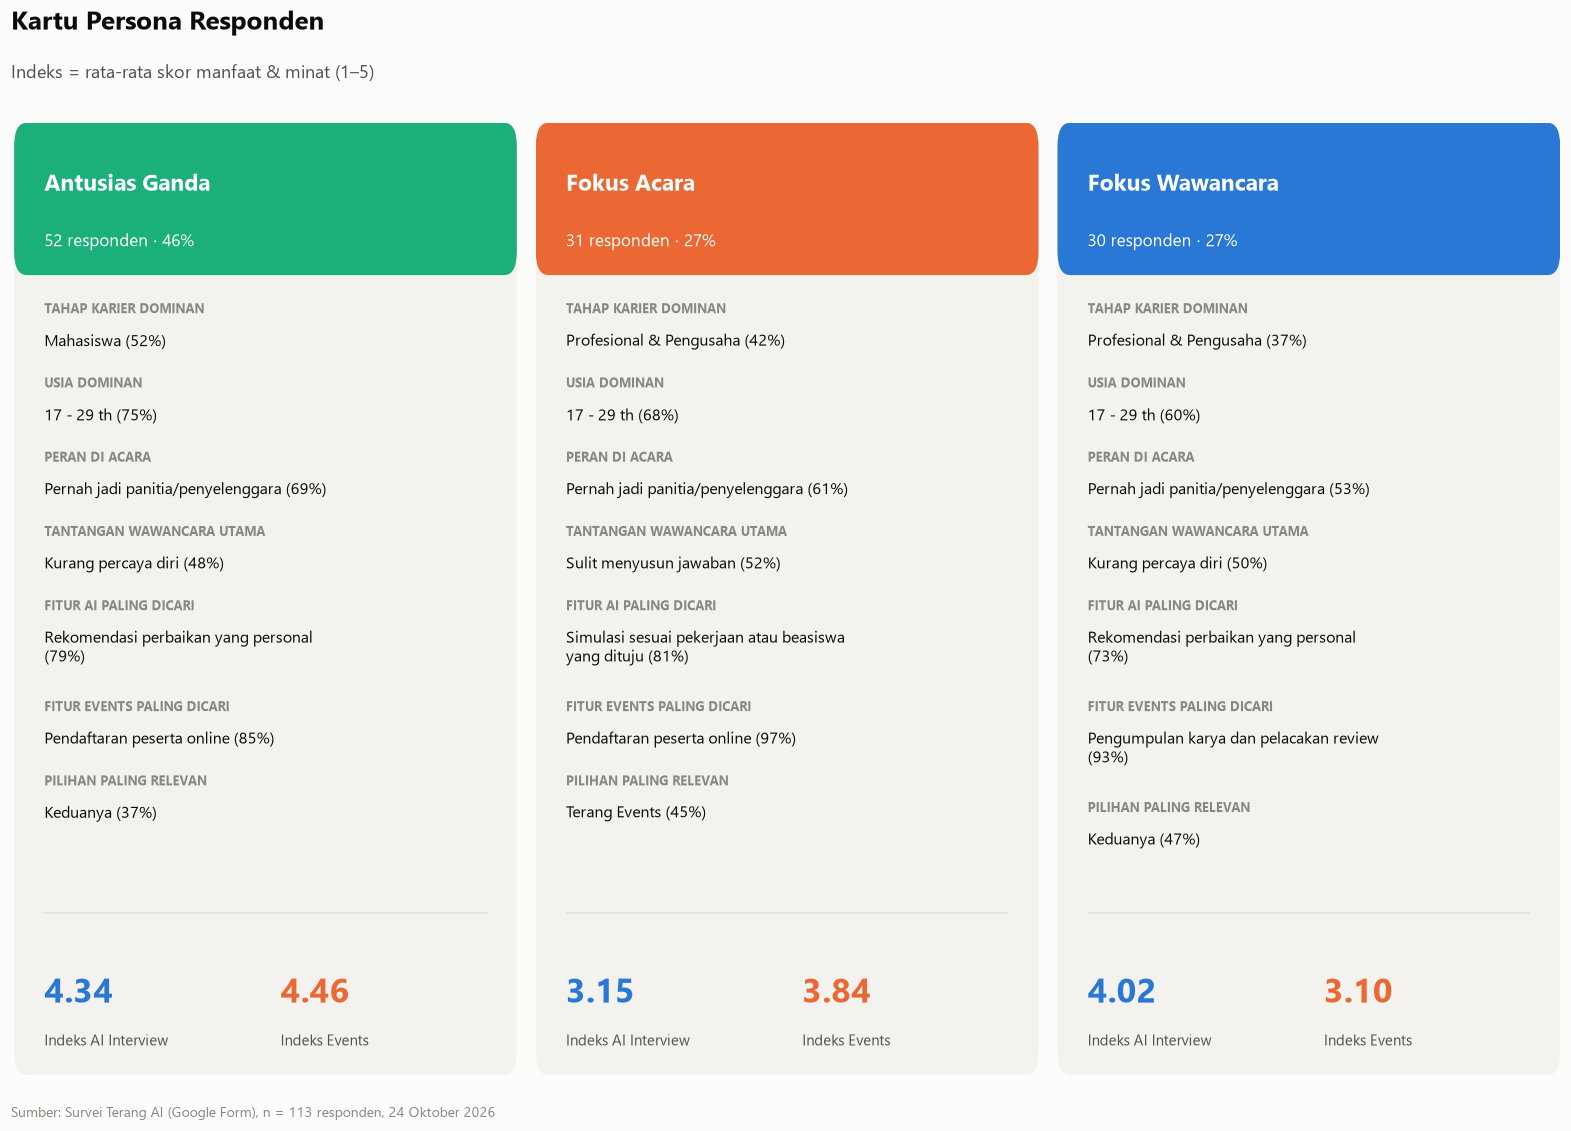

In [28]:
def top(s, k=1):
    vc = s.value_counts(normalize=True)
    return vc.index[0], vc.iloc[0]

def top_multi(frame, mask):
    s = frame[mask].mean().sort_values(ascending=False)
    return s.index[0], s.iloc[0]

pers = df['persona'].value_counts().index.tolist()
ncol = len(pers)
fig, axes = plt.subplots(1, ncol, figsize=(4.8 * ncol, 9))
axes = np.atleast_1d(axes)
for ax, p in zip(axes, pers):
    m = df['persona'] == p; s = df[m]; col = pcol(p)
    ax.axis('off'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    card(ax, 0, 0, 1, 1, PLANE)
    card(ax, 0, 0.84, 1, 0.16, col)
    ax.text(0.06, 0.935, p, fontsize=15, weight='bold', color='white', va='center', transform=ax.transAxes)
    ax.text(0.06, 0.875, f'{m.sum()} responden · {m.mean():.0%}', fontsize=11, color='white', va='center', transform=ax.transAxes)
    tw_top, tw_v = top_multi(TW.drop(columns='Tidak mengalami kendala'), m)
    fa_top, fa_v = top_multi(FA, m); fe_top, fe_v = top_multi(FE, m)
    rel_top, rel_v = top(s['pilih_relevan'])
    lines = [('Tahap karier dominan', '{} ({:.0%})'.format(*top(s['tahap']))),
             ('Usia dominan', '{} th ({:.0%})'.format(*top(s['usia'].astype(str)))),
             ('Peran di acara', '{} ({:.0%})'.format(*top(s['peran_acara']))),
             ('Tantangan wawancara utama', f'{tw_top} ({tw_v:.0%})'),
             ('Fitur AI paling dicari', f'{fa_top} ({fa_v:.0%})'),
             ('Fitur Events paling dicari', f'{fe_top} ({fe_v:.0%})'),
             ('Pilihan paling relevan', f'{rel_top} ({rel_v:.0%})')]
    yv = 0.8
    for k, v in lines:
        wv = wrap(v, 40)
        ax.text(0.06, yv, k.upper(), fontsize=8.5, color=MUTED, weight='bold', transform=ax.transAxes)
        ax.text(0.06, yv - 0.02, wv, fontsize=10.5, color=INK, va='top', transform=ax.transAxes, linespacing=1.25)
        yv -= 0.02 + 0.028 * len(wv.split('\n')) + 0.03
    ax.plot([0.06, 0.94], [0.17, 0.17], color=GRID, lw=1, transform=ax.transAxes)
    for j, (lab, val, c) in enumerate([('Indeks AI Interview', s['idx_ai'].mean(), AI), ('Indeks Events', s['idx_ev'].mean(), EV)]):
        x0 = 0.06 + j * 0.47
        ax.text(x0, 0.085, f'{val:.2f}', fontsize=22, weight='bold', color=c, transform=ax.transAxes, va='center')
        ax.text(x0, 0.035, lab, fontsize=9.5, color=INK2, transform=ax.transAxes, va='center')
titled(fig, 'Kartu Persona Responden', 'Indeks = rata-rata skor manfaat & minat (1–5)')
save(fig, '24_persona_cards')

**Cara membaca persona:** setiap kartu merangkum karakter dominan klaster. Persona dengan indeks AI dan Events sama-sama tinggi adalah target **bundling/cross-sell** (argumen ACE), persona "Fokus Wawancara" adalah *beachhead* ONE Strategy, sedangkan persona yang skeptis menunjukkan perlunya **pembuktian nilai lewat pilot** (Product–Market Validation Gap).

## 10. Analisis Teks: Alasan di Balik Pilihan Responden
Jawaban terbuka "Apa alasan utama di balik pilihanmu?" diolah dengan:
1. **Frekuensi kata** (setelah menghapus *stopwords* bahasa Indonesia),
2. **Bigram** (pasangan kata yang sering muncul bersama),
3. **Word cloud** per kelompok pilihan, dan
4. **Coding tema** berbasis kamus kata kunci → dipetakan ke ONE / ACE / gap validasi.

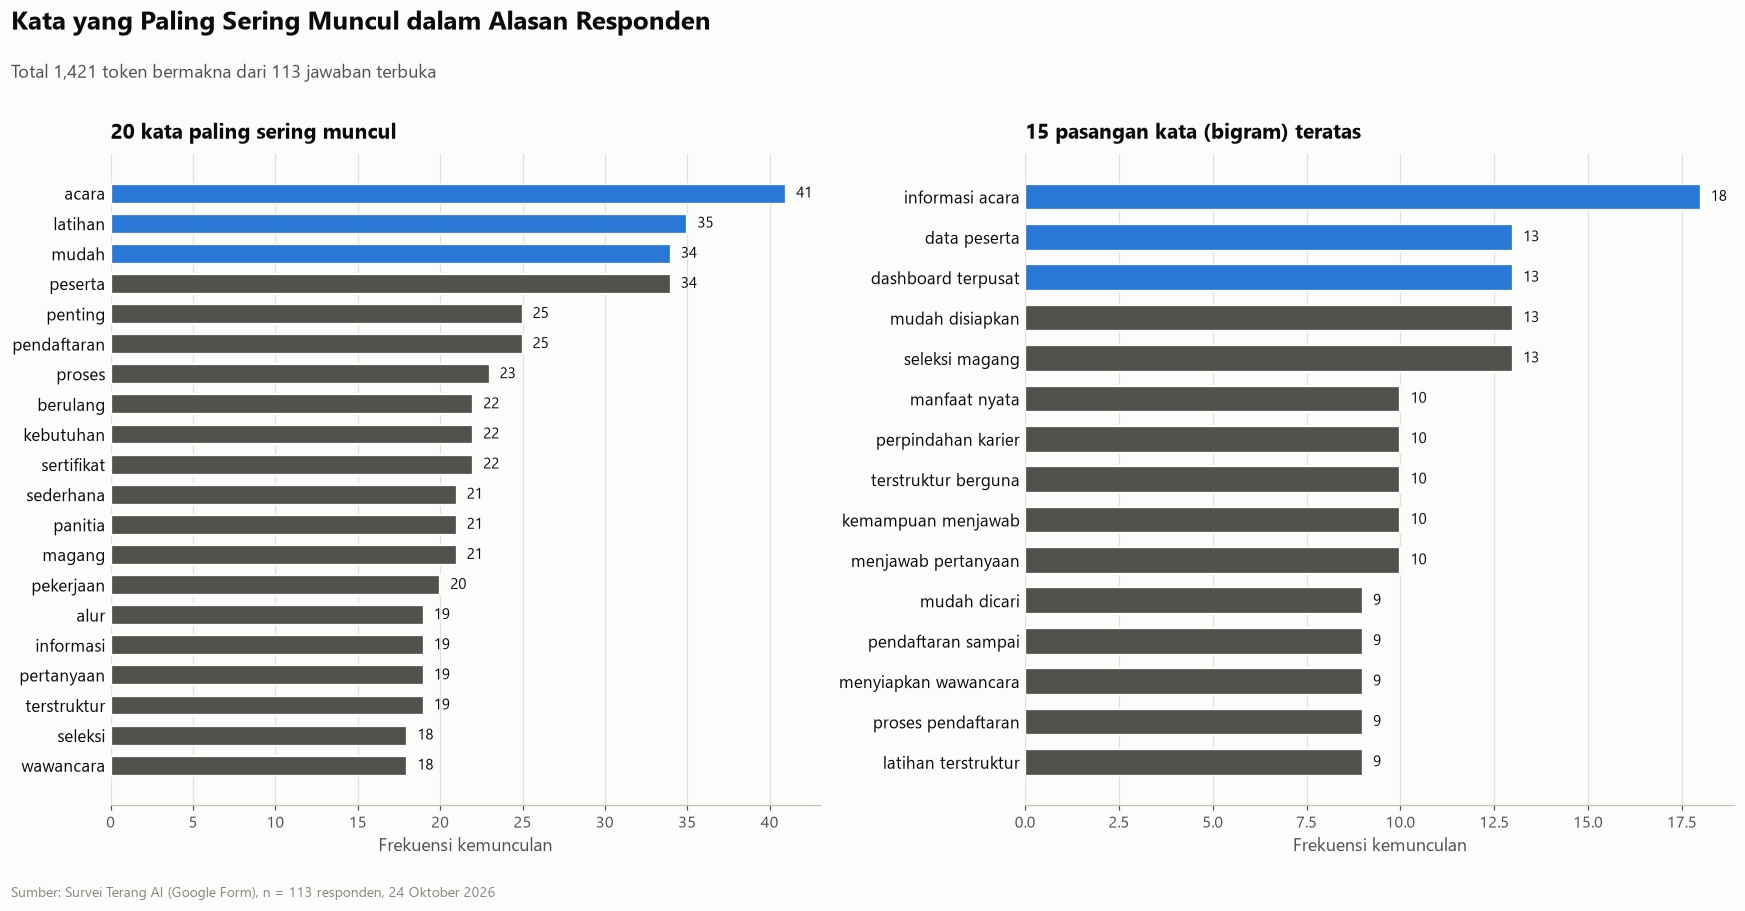

> **💡 Insight:** Kata dominan: **acara, latihan, peserta, mudah, penting, pendaftaran, proses, sertifikat**. Bigram teratas: **"informasi acara", "seleksi magang", "mudah disiapkan", "dashboard terpusat", "data peserta", "kemampuan menjawab"**. Kosakata responden terbagi jelas menjadi dua kelompok — kosakata **kandidat** (latihan, wawancara, seleksi, magang, feedback) dan kosakata **penyelenggara** (acara, peserta, pendaftaran, sertifikat, data) — ditambah tuntutan lintas produk akan alur yang **sederhana & dapat dipercaya**.

In [29]:
STOP = set("""
yang dan di ke dari untuk dengan saya karena lebih ini itu ada akan bisa jika juga tidak sebagai dalam pada atau sedangkan daripada
menurut bagi perlu tetap sangat sudah belum agar sehingga kami kamu mereka adalah oleh secara jadi tanpa seperti sering cukup
alasan sebaiknya menjadi yg nya pun lagi hal ingin punya masih saat paling kedua keduanya sama memiliki dapat melalui untuk
saja harus kalau atau namun tetapi tapi bila serta mau sekadar akan
kegiatan bermanfaat menghadapi membutuhkan memerlukan memilih terang events mungkin nanti lebih
""".split())

def words(t):
    return re.sub(r'[^a-zà-ÿ\s]', ' ', str(t).lower()).split()

def tokens(t):
    return [w for w in words(t) if w not in STOP and len(w) > 2]

df['tok'] = df['alasan'].apply(tokens)
wc_all = Counter(w for l in df['tok'] for w in l)
# bigram dihitung dari kata yang benar-benar bersebelahan di kalimat asli (bukan setelah stopword dibuang)
bigr = Counter((a, b) for t in df['alasan'] for a, b in zip(words(t), words(t)[1:])
               if a not in STOP and b not in STOP and len(a) > 2 and len(b) > 2)
top_w = pd.Series(dict(wc_all.most_common(20)))
top_b = pd.Series({f'{a} {b}': c for (a, b), c in bigr.most_common(15)})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 7))
for ax, s, ttl in [(a1, top_w, '20 kata paling sering muncul'), (a2, top_b, '15 pasangan kata (bigram) teratas')]:
    s = s.sort_values()
    ax.barh(s.index, s.values, color=[INK2 if i < len(s) - 3 else AI for i in range(len(s))], height=0.66, edgecolor=SURF, linewidth=1.5)
    for i, v in enumerate(s.values): ax.text(v + s.max() * 0.015, i, str(v), va='center', fontsize=10)
    ax.set_title(ttl); ax.set_xlabel('Frekuensi kemunculan'); ax.xaxis.grid(True); ax.set_axisbelow(True)
    ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
titled(fig, 'Kata yang Paling Sering Muncul dalam Alasan Responden', f'Total {sum(wc_all.values()):,} token bermakna dari {N} jawaban terbuka')
save(fig, '25_frekuensi_kata')
insight(f"Kata dominan: **{', '.join(top_w.index[:8])}**. Bigram teratas: **{', '.join(chr(34) + b + chr(34) for b in top_b.index[:6])}**. "
        "Kosakata responden terbagi jelas menjadi dua kelompok — kosakata **kandidat** (latihan, wawancara, seleksi, magang, feedback) dan kosakata "
        "**penyelenggara** (acara, peserta, pendaftaran, sertifikat, data) — ditambah tuntutan lintas produk akan alur yang **sederhana & dapat dipercaya**.")

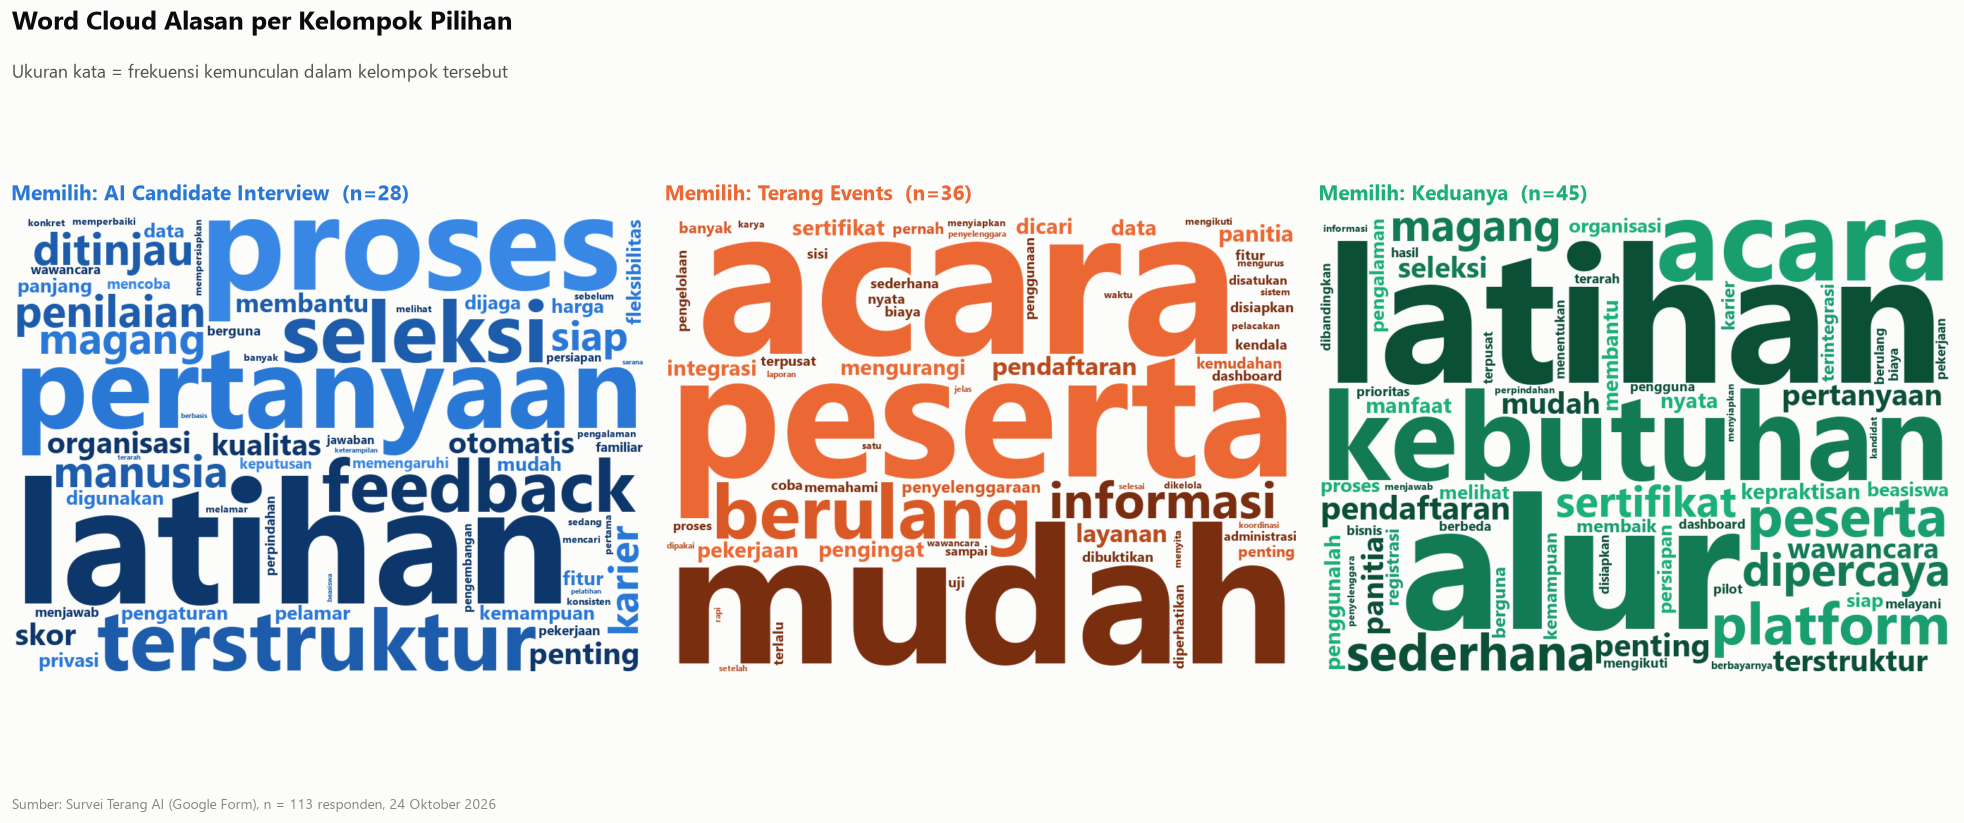

In [30]:
def color_fn(hexes):
    def f(word, font_size, position, orientation, random_state=None, **kw):
        return hexes[(font_size // 7) % len(hexes)]
    return f

groups = [('AI Candidate Interview', AI, ['#2a78d6', '#1c5cab', '#0d366b', '#3987e5']),
          ('Terang Events', EV, ['#eb6834', '#b84a1e', '#7a2e10', '#d95926']),
          ('Keduanya', BOTH, ['#1baf7a', '#127a55', '#0b4f37', '#199e70'])]
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
for ax, (g, col, hexes) in zip(axes, groups):
    freq = Counter(w for l in df.loc[df['pilih_relevan'] == g, 'tok'] for w in l)
    wc = WordCloud(width=900, height=650, background_color=SURF, color_func=color_fn(hexes), max_words=60,
                   prefer_horizontal=0.95, font_path='C:/Windows/Fonts/segoeuib.ttf' if Path('C:/Windows/Fonts/segoeuib.ttf').exists() else None,
                   random_state=3, margin=6).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off')
    ax.set_title(f'Memilih: {g}  (n={(df.pilih_relevan == g).sum()})', color=col, fontsize=14)
titled(fig, 'Word Cloud Alasan per Kelompok Pilihan', 'Ukuran kata = frekuensi kemunculan dalam kelompok tersebut')
save(fig, '26_wordcloud_per_pilihan')

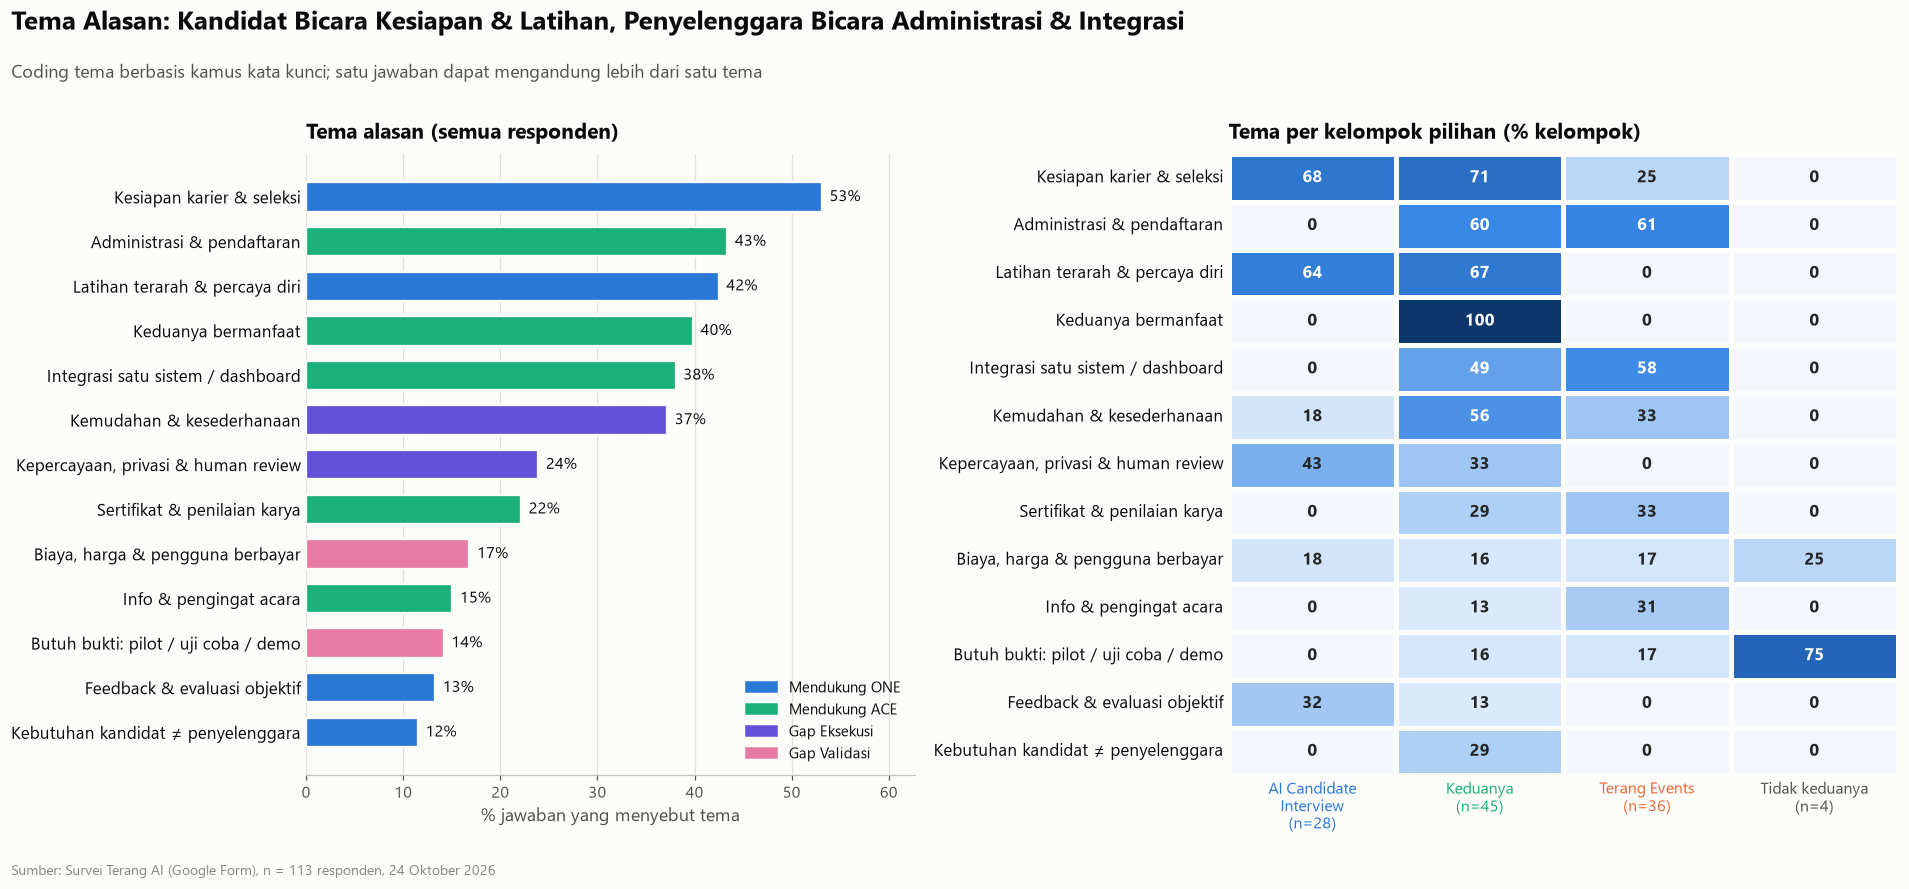

**Contoh kutipan responden per kelompok pilihan:**

- *AI Candidate Interview* — "Saya memilih ini karena saya belum banyak pengalaman wawancara sehingga perlu latihan. Privasi data pelamar tetap harus dijaga."

- *AI Candidate Interview* — "Karena saya ingin lebih siap menghadapi seleksi magang atau organisasi. Saya ingin fitur yang mudah digunakan tanpa proses pengaturan yang panjang."

- *Keduanya* — "Keduanya bermanfaat: saya ingin lebih siap menghadapi seleksi magang atau organisasi, sedangkan untuk kegiatan penyelenggaraan acara membutuhkan koordinasi pendaftaran dan peserta yang rapi. Saya ingin kedua platform memiliki alur yang sederhana dan dapat dipercaya."

- *Keduanya* — "Keduanya bermanfaat: kemampuan menjawab pertanyaan secara terstruktur berguna untuk perpindahan karier, sedangkan untuk kegiatan saya lebih sering mengikuti kegiatan daripada menyiapkan wawancara. Keduanya melayani kebutuhan yang berbeda, jadi hasil pilot perlu dibandingkan."

- *Terang Events* — "Saya lebih memerlukan Terang Events karena saya pernah menjadi peserta dan panitia sehingga memahami kendala di kedua sisi. Integrasi data peserta bisa mengurangi pekerjaan berulang."

- *Terang Events* — "Alasan saya: pengalaman peserta akan membaik jika registrasi dan sertifikat terintegrasi. Saya juga ingin ada pengingat dan informasi acara yang mudah dicari."

- *Tidak keduanya* — "Kebutuhan saya masih bisa dipenuhi dengan cara yang sekarang digunakan; saya perlu melihat demo lebih dahulu. Saya belum bisa menilai manfaatnya tanpa mencoba."

- *Tidak keduanya* — "Saya belum memiliki kebutuhan yang cukup sering untuk memakai kedua platform secara berkelanjutan. Mungkin kebutuhannya akan berubah nanti."

> **💡 Insight:** Pemilih **AI Interview** dominan berbicara tentang latihan terarah (64%), kesiapan karier (68%) dan **feedback** (32%); pemilih **Events** berbicara tentang administrasi (61%) dan **integrasi satu sistem** (58%). Kelompok **Keduanya** paling sering menuntut kemudahan (56%) dan menyadari bahwa kebutuhan kandidat ≠ penyelenggara (29%). Tema **biaya/pengguna berbayar** muncul pada 17% jawaban — sinyal bahwa responden sendiri menuntut bukti kelayakan komersial sebelum memprioritaskan.

In [31]:
THEMES = {
    'Feedback & evaluasi objektif':       (r'feedback|evaluasi|umpan balik|menilai jawaban|skor otomatis', 'ONE'),
    'Kesiapan karier & seleksi':          (r'pekerjaan|karier|magang|beasiswa|seleksi|melamar', 'ONE'),
    'Latihan terarah & percaya diri':     (r'latihan|terstruktur|terarah|konsisten|keterampilan|kepercayaan diri|komunikasi|berkomunikasi', 'ONE'),
    'Kebutuhan kandidat ≠ penyelenggara': (r'tidak bisa disamakan|kebutuhan yang berbeda', 'ONE'),
    'Administrasi & pendaftaran':         (r'administrasi|pendaftaran|registrasi|data peserta|spreadsheet', 'ACE'),
    'Integrasi satu sistem / dashboard':  (r'satu sistem|terintegrasi|integrasi|dashboard|terpusat|disatukan|tidak tersebar|laporan', 'ACE'),
    'Sertifikat & penilaian karya':       (r'sertifikat|karya', 'ACE'),
    'Info & pengingat acara':             (r'informasi acara|pengingat|mudah dicari|memperoleh informasi', 'ACE'),
    'Keduanya bermanfaat':                (r'keduanya bermanfaat', 'ACE'),
    'Kemudahan & kesederhanaan':          (r'mudah digunakan|sederhana|kepraktisan|pengaturan yang panjang|kemudahan penggunaan', 'Eksekusi'),
    'Kepercayaan, privasi & human review':(r'dipercaya|ditinjau manusia|privasi', 'Eksekusi'),
    'Butuh bukti: pilot / uji coba / demo':(r'uji coba|pilot|demo|dibuktikan|tanpa mencoba', 'Validasi'),
    'Biaya, harga & pengguna berbayar':   (r'biaya|harga|berbayar|gratis', 'Validasi'),
}
low = df['alasan'].str.lower()
TH = pd.DataFrame({k: low.str.contains(v[0], regex=True).astype(int) for k, v in THEMES.items()})
th_all = TH.mean().sort_values() * 100
TAG_COL = {'ONE': AI, 'ACE': BOTH, 'Eksekusi': VIOLET, 'Validasi': MAGENTA}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(17.5, 6.8), gridspec_kw={'width_ratios': [1, 1.1]})
a1.barh(th_all.index, th_all.values, color=[TAG_COL[THEMES[k][1]] for k in th_all.index], height=0.66, edgecolor=SURF, linewidth=1.5)
for i, v in enumerate(th_all.values): a1.text(v + 0.8, i, f'{v:.0f}%', va='center', fontsize=10.5)
a1.set_xlabel('% jawaban yang menyebut tema'); a1.set_title('Tema alasan (semua responden)'); a1.xaxis.grid(True); a1.set_axisbelow(True)
a1.spines['left'].set_visible(False); a1.tick_params(axis='y', length=0); a1.set_xlim(0, th_all.max() * 1.18)
a1.legend(handles=[mpatches.Patch(color=c, label=f'Mendukung {k}' if k in ('ONE', 'ACE') else f'Gap {k}') for k, c in TAG_COL.items()],
          loc='lower right', fontsize=10)
thg = TH.groupby(df['pilih_relevan']).mean().reindex(CHOICE_ORDER).T.loc[th_all.index[::-1]] * 100
sns.heatmap(thg, annot=True, fmt='.0f', cmap=SEQ, cbar=False, linewidths=2, linecolor=SURF, vmin=0, vmax=100,
            annot_kws={'fontsize': 11, 'weight': 'bold'}, ax=a2)
a2.set_xticklabels([f'{wrap(c, 14)}\n(n={(df.pilih_relevan == c).sum()})' for c in CHOICE_ORDER], rotation=0)
for t, c in zip(a2.get_xticklabels(), CHOICE_ORDER): t.set_color(CHOICE_COL[c] if c != 'Tidak keduanya' else INK2)
a2.set_ylabel(''); a2.set_xlabel(''); a2.tick_params(length=0); a2.set_title('Tema per kelompok pilihan (% kelompok)')
titled(fig, 'Tema Alasan: Kandidat Bicara Kesiapan & Latihan, Penyelenggara Bicara Administrasi & Integrasi',
       'Coding tema berbasis kamus kata kunci; satu jawaban dapat mengandung lebih dari satu tema')
save(fig, '27_tema_alasan')
display(Markdown('**Contoh kutipan responden per kelompok pilihan:**'))
for g in CHOICE_ORDER:
    sample = df.loc[df['pilih_relevan'] == g, 'alasan'].sample(min(2, (df.pilih_relevan == g).sum()), random_state=1)
    for s in sample: display(Markdown(f'- *{g}* — "{s}"'))
tg = TH.groupby(df['pilih_relevan']).mean()
insight(f"Pemilih **AI Interview** dominan berbicara tentang latihan terarah ({tg.loc['AI Candidate Interview', 'Latihan terarah & percaya diri']:.0%}), kesiapan karier "
        f"({tg.loc['AI Candidate Interview', 'Kesiapan karier & seleksi']:.0%}) dan **feedback** ({tg.loc['AI Candidate Interview', 'Feedback & evaluasi objektif']:.0%}); "
        f"pemilih **Events** berbicara tentang administrasi ({tg.loc['Terang Events', 'Administrasi & pendaftaran']:.0%}) dan **integrasi satu sistem** "
        f"({tg.loc['Terang Events', 'Integrasi satu sistem / dashboard']:.0%}). Kelompok **Keduanya** paling sering menuntut kemudahan "
        f"({tg.loc['Keduanya', 'Kemudahan & kesederhanaan']:.0%}) dan menyadari bahwa kebutuhan kandidat ≠ penyelenggara "
        f"({tg.loc['Keduanya', 'Kebutuhan kandidat ≠ penyelenggara']:.0%}). Tema **biaya/pengguna berbayar** muncul pada {TH['Biaya, harga & pengguna berbayar'].mean():.0%} jawaban "
        "— sinyal bahwa responden sendiri menuntut bukti kelayakan komersial sebelum memprioritaskan.")

## 11. Bukti untuk ONE Strategy vs ACE Strategy

Bagian ini merangkum seluruh temuan menjadi **amunisi debat** untuk kedua sisi. Prinsipnya: **data yang sama dibaca dengan dua lensa strategis.**

### 11.1 *Scorecard* perbandingan produk

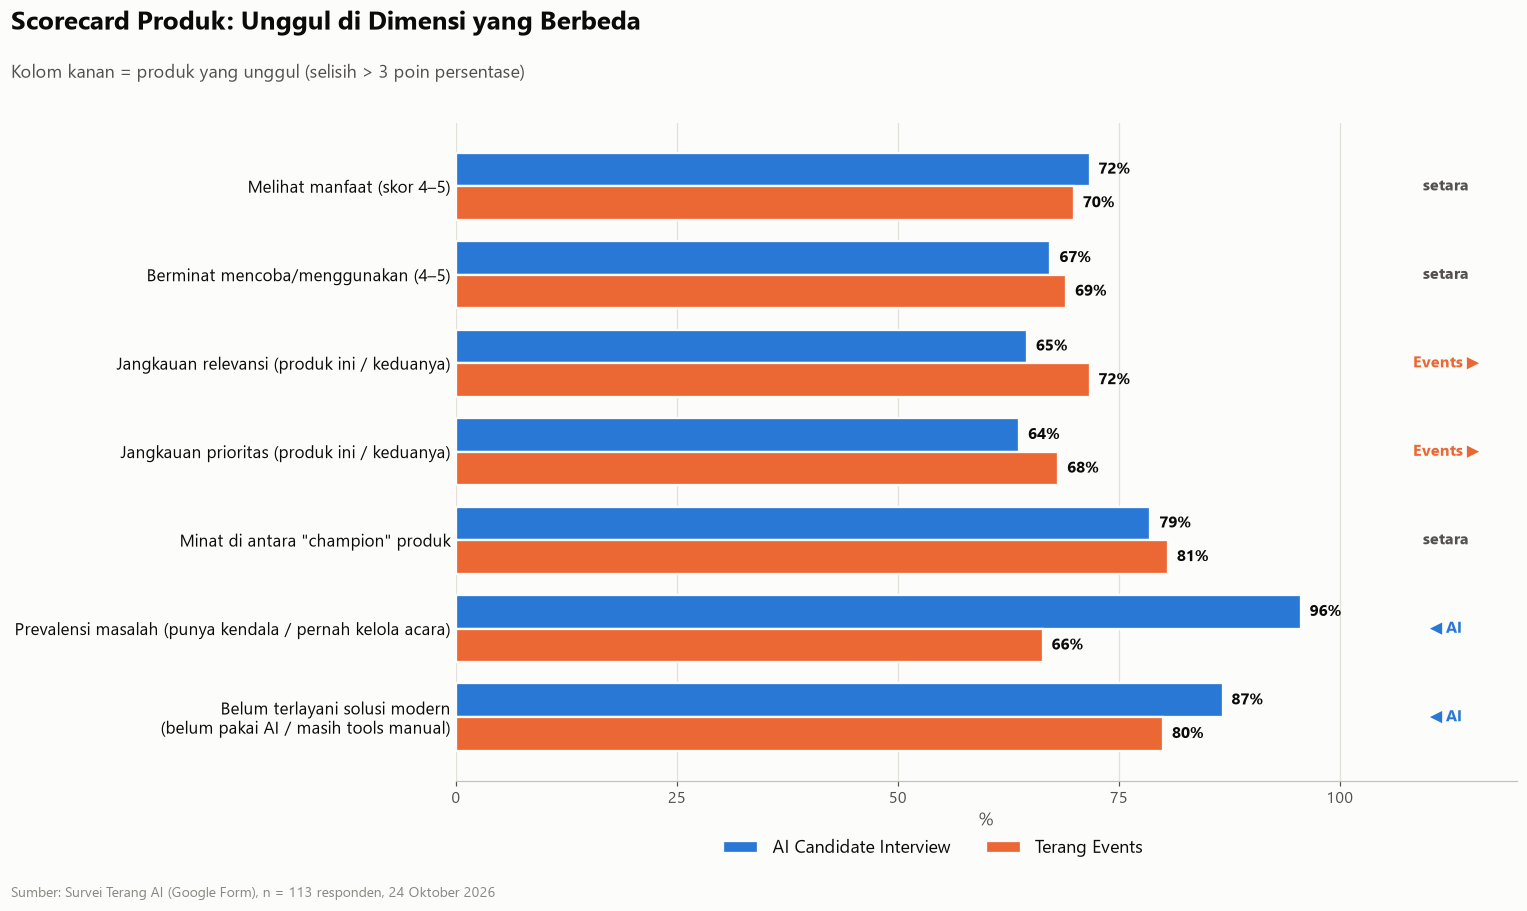

,AI Candidate Interview,Terang Events
Melihat manfaat (skor 4–5),71.7,69.9
Berminat mencoba/menggunakan (4–5),67.3,69.0
Jangkauan relevansi (produk ini / keduanya),64.6,71.7
Jangkauan prioritas (produk ini / keduanya),63.7,68.1
"Minat di antara ""champion"" produk",78.6,80.6
Prevalensi masalah (punya kendala / pernah kelola acara),95.6,66.4
Belum terlayani solusi modern\n(belum pakai AI / masih tools manual),86.7,80.0


In [32]:
champ_ai = df[df['pilih_relevan'] == 'AI Candidate Interview']
champ_ev = df[df['pilih_relevan'] == 'Terang Events']
score = pd.DataFrame({
    'AI Candidate Interview': [
        df['t2b_manfaat_ai'].mean(), df['t2b_minat_ai'].mean(),
        df['pilih_relevan'].isin(['AI Candidate Interview', 'Keduanya']).mean(),
        df['pilih_prioritas'].isin(['AI Candidate Interview', 'Keduanya']).mean(),
        (champ_ai['minat_ai'] >= 4).mean(),
        1 - TW['Tidak mengalami kendala'].mean(),
        1 - df['latihan_ai'].mean()],
    'Terang Events': [
        df['t2b_manfaat_ev'].mean(), df['t2b_minat_ev'].mean(),
        df['pilih_relevan'].isin(['Terang Events', 'Keduanya']).mean(),
        df['pilih_prioritas'].isin(['Terang Events', 'Keduanya']).mean(),
        (champ_ev['minat_ev'] >= 4).mean(),
        df['pengelola'].mean(),
        mgr['tools_manual'].mean()],
}, index=['Melihat manfaat (skor 4–5)', 'Berminat mencoba/menggunakan (4–5)', 'Jangkauan relevansi (produk ini / keduanya)',
          'Jangkauan prioritas (produk ini / keduanya)', 'Minat di antara "champion" produk',
          'Prevalensi masalah (punya kendala / pernah kelola acara)', 'Belum terlayani solusi modern\n(belum pakai AI / masih tools manual)']) * 100

fig, ax = plt.subplots(figsize=(14, 7))
yy = np.arange(len(score))[::-1]
ax.barh(yy + 0.19, score['AI Candidate Interview'], height=0.38, color=AI, label='AI Candidate Interview', edgecolor=SURF, linewidth=1.5)
ax.barh(yy - 0.19, score['Terang Events'], height=0.38, color=EV, label='Terang Events', edgecolor=SURF, linewidth=1.5)
for yi, (a, e) in zip(yy, score.values):
    ax.text(a + 1, yi + 0.19, f'{a:.0f}%', va='center', fontsize=10.5, weight='bold')
    ax.text(e + 1, yi - 0.19, f'{e:.0f}%', va='center', fontsize=10.5, weight='bold')
    w = 'AI' if a - e > 3 else ('EV' if e - a > 3 else '=')
    ax.text(112, yi, {'AI': '◀ AI', 'EV': 'Events ▶', '=': 'setara'}[w], va='center', ha='center', fontsize=10.5, weight='bold',
            color={'AI': AI, 'EV': EV, '=': INK2}[w])
ax.set_yticks(yy); ax.set_yticklabels(score.index); ax.set_xlim(0, 120); ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.grid(True); ax.set_axisbelow(True); ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.legend(loc='lower center', bbox_to_anchor=(0.45, -0.14), ncol=2, fontsize=11.5); ax.set_xlabel('%')
titled(fig, 'Scorecard Produk: Unggul di Dimensi yang Berbeda', 'Kolom kanan = produk yang unggul (selisih > 3 poin persentase)')
save(fig, '28_scorecard_produk')
display(score.round(1))

### 11.2 *Evidence board*: ONE vs ACE

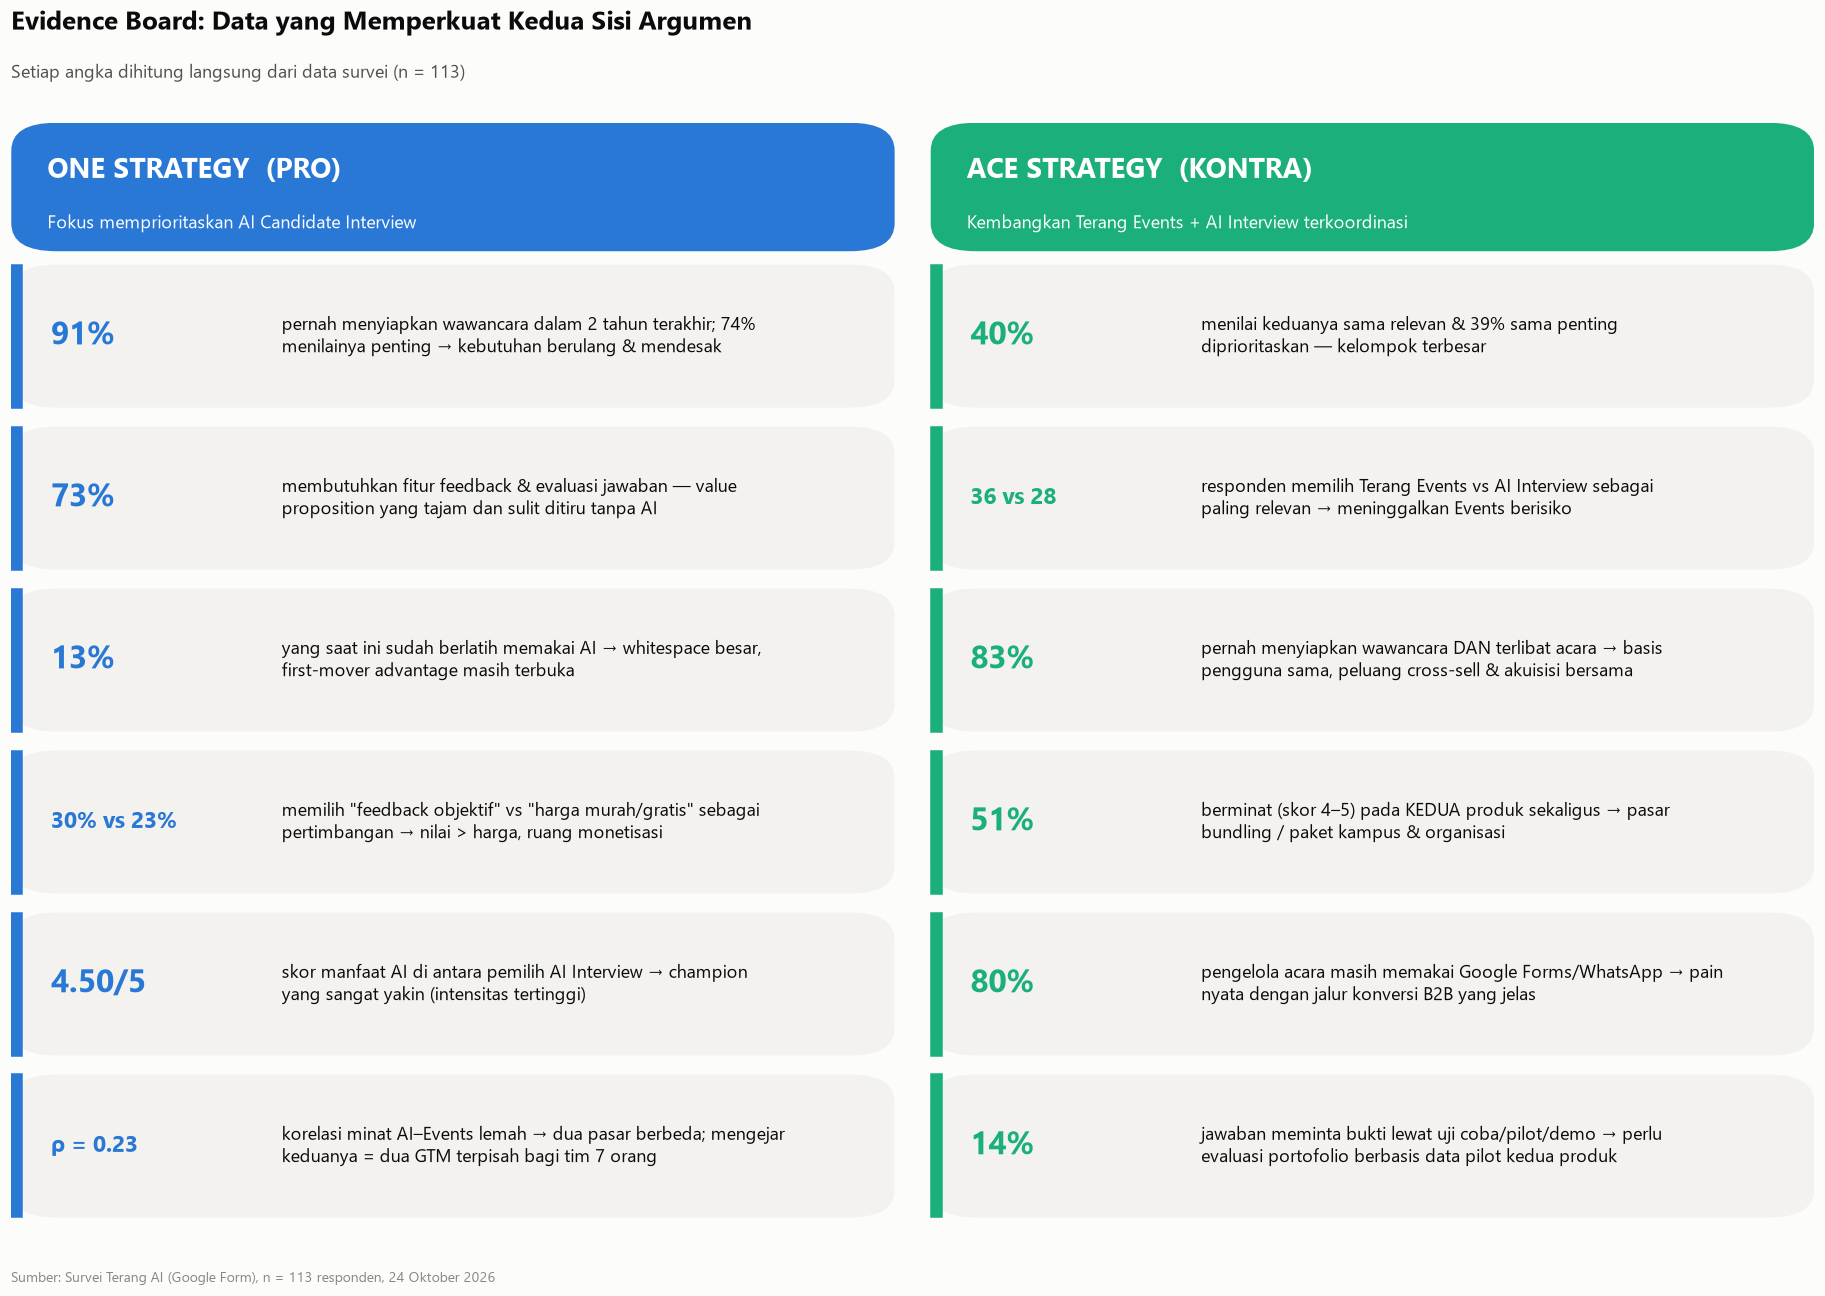

In [33]:
E = {}
E['wwc'] = df['pernah_wwc'].mean(); E['penting'] = df['t2b_penting_wawancara'].mean()
E['feedback_need'] = FA['Feedback dan evaluasi jawaban'].mean(); E['ai_now'] = df['latihan_ai'].mean()
E['obj'] = (df['pertimbangan_ai'] == 'Mendapatkan feedback yang objektif').mean(); E['price'] = (df['pertimbangan_ai'] == 'Harga terjangkau atau gratis').mean()
E['champ_ai_int'] = champ_ai['manfaat_ai'].mean(); E['fg_ai'] = (df.loc[df.tahap == 'Fresh Graduate', 'pilih_relevan'] == 'AI Candidate Interview').mean()
E['rho'] = r_s.statistic; E['differs'] = TH['Kebutuhan kandidat ≠ penyelenggara'].mean()
E['both_rel'] = (df['pilih_relevan'] == 'Keduanya').mean(); E['both_pri'] = (df['pilih_prioritas'] == 'Keduanya').mean()
E['overlap'] = both_exp; E['dual'] = df['t2b_both'].mean(); E['manual'] = mgr['tools_manual'].mean()
E['ev_vs_ai'] = (rel['Terang Events'], rel['AI Candidate Interview']); E['reach_ev'] = any_ev
E['pilot'] = TH['Butuh bukti: pilot / uji coba / demo'].mean()

ONE = [(f"{E['wwc']:.0%}", 'pernah menyiapkan wawancara dalam 2 tahun terakhir; ' + f"{E['penting']:.0%} menilainya penting → kebutuhan berulang & mendesak"),
       (f"{E['feedback_need']:.0%}", 'membutuhkan fitur feedback & evaluasi jawaban — value proposition yang tajam dan sulit ditiru tanpa AI'),
       (f"{E['ai_now']:.0%}", 'yang saat ini sudah berlatih memakai AI → whitespace besar, first-mover advantage masih terbuka'),
       (f"{E['obj']:.0%} vs {E['price']:.0%}", 'memilih "feedback objektif" vs "harga murah/gratis" sebagai pertimbangan → nilai > harga, ruang monetisasi'),
       (f"{E['champ_ai_int']:.2f}/5", 'skor manfaat AI di antara pemilih AI Interview → champion yang sangat yakin (intensitas tertinggi)'),
       (f"ρ = {E['rho']:.2f}", 'korelasi minat AI–Events lemah → dua pasar berbeda; mengejar keduanya = dua GTM terpisah bagi tim 7 orang')]
ACE = [(f"{E['both_rel']:.0%}", f"menilai keduanya sama relevan & {E['both_pri']:.0%} sama penting diprioritaskan — kelompok terbesar"),
       (f"{E['ev_vs_ai'][0]} vs {E['ev_vs_ai'][1]}", 'responden memilih Terang Events vs AI Interview sebagai paling relevan → meninggalkan Events berisiko'),
       (f"{E['overlap']:.0%}", 'pernah menyiapkan wawancara DAN terlibat acara → basis pengguna sama, peluang cross-sell & akuisisi bersama'),
       (f"{E['dual']:.0%}", 'berminat (skor 4–5) pada KEDUA produk sekaligus → pasar bundling / paket kampus & organisasi'),
       (f"{E['manual']:.0%}", 'pengelola acara masih memakai Google Forms/WhatsApp → pain nyata dengan jalur konversi B2B yang jelas'),
       (f"{E['pilot']:.0%}", 'jawaban meminta bukti lewat uji coba/pilot/demo → perlu evaluasi portofolio berbasis data pilot kedua produk')]

fig, ax = plt.subplots(figsize=(17, 10.5))
ax.axis('off'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
for x0, col, head, sub, ev in [(0.0, AI, 'ONE STRATEGY  (PRO)', 'Fokus memprioritaskan AI Candidate Interview', ONE),
                               (0.51, BOTH, 'ACE STRATEGY  (KONTRA)', 'Kembangkan Terang Events + AI Interview terkoordinasi', ACE)]:
    card(ax, x0, 0.885, 0.49, 0.115, col)
    ax.text(x0 + 0.02, 0.957, head, fontsize=18, weight='bold', color='white', va='center')
    ax.text(x0 + 0.02, 0.91, sub, fontsize=12, color='white', va='center')
    for i, (num, txt) in enumerate(ev):
        y0 = 0.745 - i * 0.145
        card(ax, x0, y0, 0.49, 0.128, PLANE)
        ax.add_patch(mpatches.Rectangle((x0, y0), 0.006, 0.128, color=col, transform=ax.transAxes))
        ax.text(x0 + 0.022, y0 + 0.064, num, fontsize=21 if len(num) < 8 else 15, weight='bold', color=col, va='center')
        ax.text(x0 + 0.15, y0 + 0.064, wrap(txt, 60), fontsize=11.5, color=INK, va='center', linespacing=1.35)
titled(fig, 'Evidence Board: Data yang Memperkuat Kedua Sisi Argumen', 'Setiap angka dihitung langsung dari data survei (n = 113)')
save(fig, '29_evidence_board_one_ace')

## 12. Pemetaan Data ke Tiga *Strategic Gap*
Bagaimana temuan survei menguatkan tiga akar masalah Terang AI pada studi kasus?

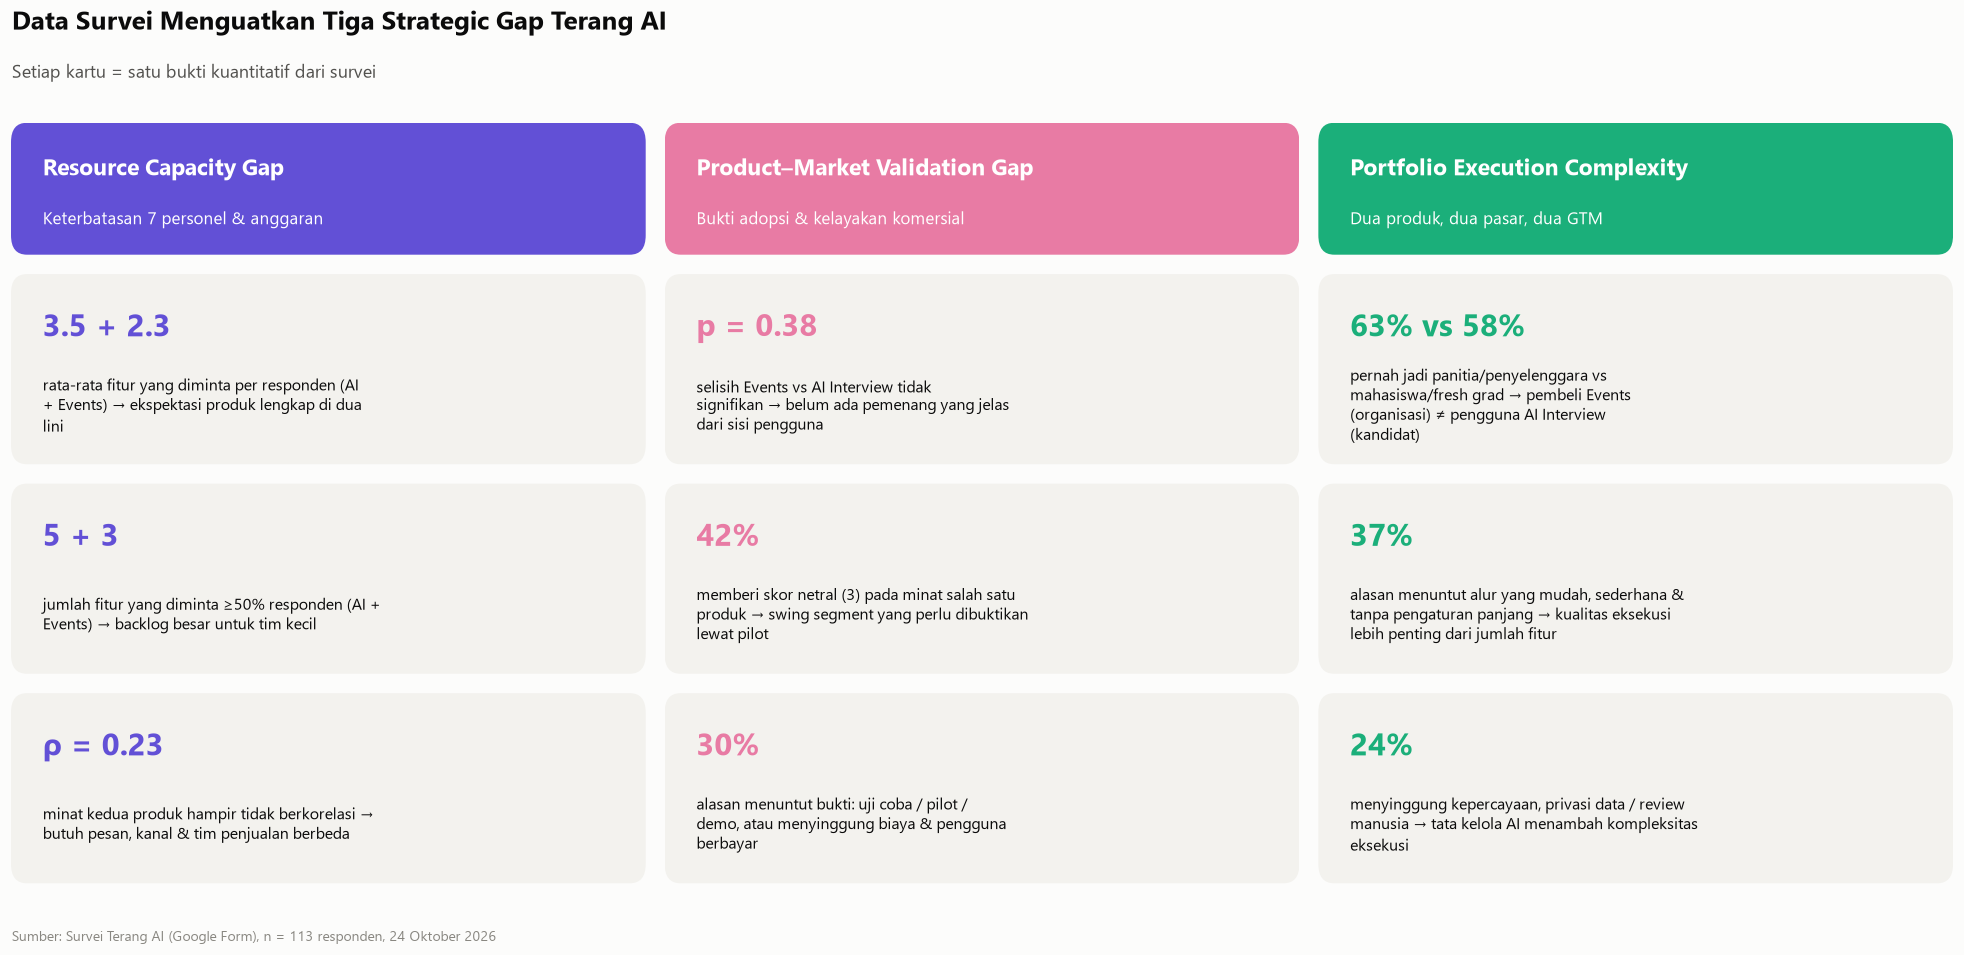

In [34]:
gaps = [
    ('Resource Capacity Gap', 'Keterbatasan 7 personel & anggaran', VIOLET, [
        (f"{df['n_fitur_ai'].mean():.1f} + {df['n_fitur_ev'].mean():.1f}", 'rata-rata fitur yang diminta per responden (AI + Events) → ekspektasi produk lengkap di dua lini'),
        (f"{(FA.mean() >= 0.5).sum()} + {(FE.mean() >= 0.5).sum()}", 'jumlah fitur yang diminta ≥50% responden (AI + Events) → backlog besar untuk tim kecil'),
        (f"ρ = {E['rho']:.2f}", 'minat kedua produk hampir tidak berkorelasi → butuh pesan, kanal & tim penjualan berbeda'),
    ]),
    ('Product–Market Validation Gap', 'Bukti adopsi & kelayakan komersial', MAGENTA, [
        (f"p = {bt_rel.pvalue:.2f}", 'selisih Events vs AI Interview tidak signifikan → belum ada pemenang yang jelas dari sisi pengguna'),
        (f"{((df['minat_ai'] == 3) | (df['minat_ev'] == 3)).mean():.0%}", 'memberi skor netral (3) pada minat salah satu produk → swing segment yang perlu dibuktikan lewat pilot'),
        (f"{(TH['Butuh bukti: pilot / uji coba / demo'] | TH['Biaya, harga & pengguna berbayar']).mean():.0%}", 'alasan menuntut bukti: uji coba / pilot / demo, atau menyinggung biaya & pengguna berbayar'),
    ]),
    ('Portfolio Execution Complexity', 'Dua produk, dua pasar, dua GTM', BOTH, [
        (f"{(df['peran_acara'] == 'Pernah jadi panitia/penyelenggara').mean():.0%} vs {df['tahap'].isin(['Mahasiswa', 'Fresh Graduate']).mean():.0%}",
         'pernah jadi panitia/penyelenggara vs mahasiswa/fresh grad → pembeli Events (organisasi) ≠ pengguna AI Interview (kandidat)'),
        (f"{TH['Kemudahan & kesederhanaan'].mean():.0%}", 'alasan menuntut alur yang mudah, sederhana & tanpa pengaturan panjang → kualitas eksekusi lebih penting dari jumlah fitur'),
        (f"{TH['Kepercayaan, privasi & human review'].mean():.0%}", 'menyinggung kepercayaan, privasi data / review manusia → tata kelola AI menambah kompleksitas eksekusi'),
    ]),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 7.4))
for ax, (g, sub, col, items) in zip(axes, gaps):
    ax.axis('off'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    card(ax, 0, 0.83, 1, 0.17, col)
    ax.text(0.05, 0.94, g, fontsize=15, weight='bold', color='white', va='center')
    ax.text(0.05, 0.875, sub, fontsize=11, color='white', va='center')
    for i, (num, txt) in enumerate(items):
        y0 = 0.56 - i * 0.27
        card(ax, 0, y0, 1, 0.245, PLANE)
        ax.text(0.05, y0 + 0.175, num, fontsize=20, weight='bold', color=col, va='center')
        ax.text(0.05, y0 + 0.075, wrap(txt, 46), fontsize=10.5, color=INK, va='center', linespacing=1.3)
titled(fig, 'Data Survei Menguatkan Tiga Strategic Gap Terang AI', 'Setiap kartu = satu bukti kuantitatif dari survei')
save(fig, '30_strategic_gaps')

## 13. Ekspor Angka Kunci untuk Slide
Seluruh angka kunci disimpan ke `figures/terang-ai/headline_stats.csv` agar mudah disalin ke pitch deck.

In [35]:
headline = pd.DataFrame([
    ('Profil', 'Total responden', N),
    ('Profil', '% usia 17–29', df['usia'].eq('17 - 29').mean() * 100),
    ('Profil', '% mahasiswa', df['pekerjaan'].eq('Mahasiswa').mean() * 100),
    ('Profil', '% mahasiswa + fresh graduate', df['tahap'].isin(['Mahasiswa', 'Fresh Graduate']).mean() * 100),
    ('AI Interview', '% pernah menyiapkan wawancara', E['wwc'] * 100),
    ('AI Interview', '% wawancara penting (4–5)', E['penting'] * 100),
    ('AI Interview', '% tantangan: sulit mendapat feedback', TW['Sulit mendapat feedback'].mean() * 100),
    ('AI Interview', '% tantangan: kurang percaya diri', TW['Kurang percaya diri'].mean() * 100),
    ('AI Interview', '% berlatih sendiri', (df['cara_latihan'] == 'Berlatih sendiri').mean() * 100),
    ('AI Interview', '% sudah pakai AI untuk latihan', E['ai_now'] * 100),
    ('AI Interview', '% butuh fitur feedback & evaluasi', E['feedback_need'] * 100),
    ('AI Interview', '% pertimbangan feedback objektif', E['obj'] * 100),
    ('AI Interview', '% pertimbangan harga murah/gratis', E['price'] * 100),
    ('AI Interview', '% manfaat (4–5)', df['t2b_manfaat_ai'].mean() * 100),
    ('AI Interview', '% minat mencoba (4–5)', df['t2b_minat_ai'].mean() * 100),
    ('AI Interview', 'Early adopter penuh (orang)', ai_steps[-1][1]),
    ('Events', '% pernah terlibat acara', (df['pernah_acara'] != 'Belum pernah').mean() * 100),
    ('Events', '% pernah jadi panitia/penyelenggara', org * 100),
    ('Events', '% info acara dari medsos/WA', (si['Instagram atau media sosial'] + si['WhatsApp atau grup kampus']) * 100),
    ('Events', '% pengelola masih pakai tools manual', E['manual'] * 100),
    ('Events', '% tantangan: pendaftaran & data peserta', ta['Mengelola pendaftaran dan data peserta'] * 100),
    ('Events', '% butuh pendaftaran online', FE['Pendaftaran peserta online'].mean() * 100),
    ('Events', '% manfaat (4–5)', df['t2b_manfaat_ev'].mean() * 100),
    ('Events', '% minat menggunakan (4–5)', df['t2b_minat_ev'].mean() * 100),
    ('Events', 'Early adopter penuh (orang)', ev_steps[-1][1]),
    ('Strategi', '% keduanya sama relevan', E['both_rel'] * 100),
    ('Strategi', '% keduanya sama penting (prioritas)', E['both_pri'] * 100),
    ('Strategi', '% pilih Terang Events (relevan)', rel['Terang Events'] / N * 100),
    ('Strategi', '% pilih AI Interview (relevan)', rel['AI Candidate Interview'] / N * 100),
    ('Strategi', '% pilih Terang Events (prioritas)', pri['Terang Events'] / N * 100),
    ('Strategi', '% pilih AI Interview (prioritas)', pri['AI Candidate Interview'] / N * 100),
    ('Strategi', '% minat KEDUA produk (4–5)', E['dual'] * 100),
    ('Strategi', '% punya pengalaman wawancara & acara', E['overlap'] * 100),
    ('Strategi', 'p-value binomial Events vs AI (relevan)', bt_rel.pvalue),
    ('Strategi', 'Spearman ρ indeks AI vs Events', E['rho']),
], columns=['Blok', 'Metrik', 'Nilai'])
headline['Nilai'] = headline['Nilai'].astype(float).round(2)
headline.to_csv(FIG_DIR / 'headline_stats.csv', index=False)
display(headline)
print(f'\n✅ {len(list(FIG_DIR.glob("*.png")))} grafik + headline_stats.csv tersimpan di {FIG_DIR.resolve()}')

,Blok,Metrik,Nilai
0,Profil,Total responden,113.00
1,Profil,% usia 17–29,69.03
2,Profil,% mahasiswa,41.59
3,Profil,% mahasiswa + fresh graduate,57.52
4,AI Interview,% pernah menyiapkan wawancara,91.15
5,AI Interview,% wawancara penting (4–5),74.34
6,AI Interview,% tantangan: sulit mendapat feedback,43.36
7,AI Interview,% tantangan: kurang percaya diri,44.25
8,AI Interview,% berlatih sendiri,36.28
9,AI Interview,% sudah pakai AI untuk latihan,13.27



✅ 30 grafik + headline_stats.csv tersimpan di C:\Users\stanl\OneDrive\Documents\Code\Lomba 2026\BCDC\Repository\data-analysis\figures\terang-ai


## 14. Kesimpulan, Rekomendasi & Keterbatasan

### 14.1 Jawaban atas *Key Strategic Question*
> *Bagaimana Terang AI dapat mengoptimalkan prioritas pengembangan produk, alokasi sumber daya, dan penetrasi pasar untuk mencapai pertumbuhan B2B yang berkelanjutan?*

Data survei menunjukkan bahwa **kedua produk sama-sama memiliki permintaan nyata** (±70% melihat manfaat dan berminat), tetapi **tidak ada yang unggul signifikan**. Karena itu, pertanyaannya bergeser dari *"produk mana yang lebih disukai?"* menjadi *"bagaimana mengubah permintaan menjadi pertumbuhan B2B yang terukur dengan tim 7 orang?"* — sesuai *core business insight* studi kasus.

### 14.2 Bagaimana data memperkuat **ONE Strategy** (fokus AI Candidate Interview)

| Pilar ONE | Bukti dari survei | Implikasi |
|---|---|---|
| **O**ptimize Product Value | 73% butuh feedback & evaluasi jawaban, 76% simulasi sesuai posisi, 72% rekomendasi perbaikan personal; feedback objektif adalah pertimbangan #1 (30%) di atas harga (23%) | Bangun MVP yang unggul di **kualitas evaluasi** (simulasi per posisi + feedback objektif + *human review*), bukan sekadar bank soal |
| **N**avigate Market Growth | Hanya 13% sudah berlatih dengan AI (whitespace); 39% paling butuh persiapan saat **melamar pekerjaan**; fresh graduate 100% pernah menyiapkan wawancara dan 89% memilih AI/keduanya | *Beachhead*: fresh graduate & pencari kerja → masuk B2B lewat **career center kampus & perusahaan perekrut lulusan baru** |
| **E**valuate for Expansion | 51% berminat pada kedua produk; korelasi minat AI–Events lemah (ρ = 0,23) | Events menjadi **opsi ekspansi tahap berikutnya** setelah AI Interview tervalidasi; fokus menghindari dua GTM paralel bagi tim kecil |

**Kalimat kunci ONE:** *"Masalah wawancara dialami 96% responden, solusinya (feedback objektif) belum dimiliki 87% responden, dan pengguna menilai kualitas di atas harga — ini adalah peluang first-mover yang hanya bisa dimenangkan dengan fokus."*

### 14.3 Bagaimana data memperkuat **ACE Strategy** (dua produk terkoordinasi)

| Pilar ACE | Bukti dari survei | Implikasi |
|---|---|---|
| **A**gile Feature Development | 80% butuh *pengumpulan karya & pelacakan review* (Events) dan 65–73% butuh *skor & feedback* (AI) → keduanya adalah **mesin evaluasi**; 87% butuh registrasi online | Bangun **modul bersama** (registrasi/data peserta, engine penilaian AI) yang dipakai kedua produk → efisiensi pengembangan |
| **C**oordinate Markets & Capacity | 83% responden punya pengalaman wawancara *dan* acara; 40% menilai keduanya sama relevan; 75% info acara lewat IG/WA kampus | **Satu kanal akuisisi (kampus & organisasi)** untuk dua produk: acara/kompetisi kampus menjadi pintu masuk AI Interview (mis. seleksi panitia, career fair) |
| **E**valuate and Evolve Portfolio | Selisih permintaan tidak signifikan (p = 0,38); Events 36 vs AI 28 pemilih; responden sendiri meminta pilot, demo, dan bukti biaya/pengguna berbayar | Jalankan **pilot terukur di kedua produk** dengan *stage-gate* (KPI adopsi & konversi berbayar) sebelum alokasi sumber daya final |

**Kalimat kunci ACE:** *"Pengguna kedua produk adalah orang yang sama (83% irisan), permintaan Events tidak kalah dari AI Interview, dan 80% pengelola acara masih manual — meninggalkan Terang Events berarti melepas pasar yang sudah siap."*

### 14.4 Amunisi *rebuttal* (untuk debat)

| Jika lawan berkata… | Jawaban berbasis data |
|---|---|
| (ke ONE) "Events lebih diminati, kenapa ditinggalkan?" | Selisih Events vs AI **tidak signifikan** (p = 0,38 relevansi; p = 0,61 prioritas). AI Interview justru memiliki prevalensi masalah tertinggi (96%) dan *whitespace* terbesar (87% belum memakai AI). |
| (ke ONE) "Pasar terlalu sempit?" | 91% pernah menyiapkan wawancara dalam 2 tahun; kebutuhan berulang (magang → beasiswa → kerja). |
| (ke ACE) "Tim 7 orang tidak mampu dua produk." | ACE bukan paralel penuh: modul inti **berbagi teknologi** (registrasi & engine review/penilaian) dan **berbagi kanal** (kampus) — 83% irisan pengguna menurunkan biaya akuisisi. |
| (ke ACE) "Kebutuhan kandidat dan penyelenggara berbeda." | Benar untuk *pembeli* (organisasi vs kandidat), tetapi *penggunanya* sama; 51% berminat pada keduanya — peluang bundling paket kampus/organisasi. |

### 14.5 Keterbatasan analisis
1. **Sampel non-probabilitas** (n = 113, satu hari pengisian, didominasi usia 17–29). *Margin of error* proporsi ±9,2 poin persentase pada tingkat kepercayaan 95%.
2. **Responden adalah pengguna akhir** (kandidat, peserta, panitia), bukan **pembeli B2B** (HR perusahaan, institusi, penyelenggara profesional). *Willingness to pay* B2B belum diukur.
3. **Minat (*stated intention*) ≠ adopsi nyata.** Skor 4–5 perlu dikonfirmasi dengan metrik pilot (aktivasi, retensi, konversi berbayar).
4. **Jawaban terbuka cenderung seragam dan terstruktur**, sehingga coding tema berbasis kamus kata kunci; hasil analisis teks dibaca sebagai indikasi tema, bukan ukuran intensitas.
5. Beberapa segmen berukuran kecil (n < 15) — temuan segmen adalah **hipotesis targeting**, bukan kesimpulan final.

### 14.6 Rekomendasi langkah lanjut
- **Survei/wawancara pembeli B2B** (HR & rekruter untuk AI Interview; BEM/himpunan/EO untuk Terang Events) untuk mengukur *willingness to pay* dan siklus pembelian.
- **Pilot berbasis KPI** (mis. 2 kampus × 1 perusahaan) dengan metrik: % aktivasi, skor kepuasan feedback, jumlah acara yang dikelola, konversi berbayar.
- **Uji harga** (mis. Van Westendorp) karena 23% responden sensitif terhadap harga dan tema biaya muncul di jawaban terbuka.
- Pantau **persona "Antusias Ganda" (46%)** sebagai indikator kesiapan bundling — dasar keputusan *evaluate for expansion* (ONE) maupun *evolve portfolio* (ACE).

---
*Notebook ini dapat dijalankan ulang dari atas ke bawah; seluruh angka pada insight dan grafik dihitung otomatis dari `dataset.csv`.*